# Skin Cancer Classification - Tabular Data Analysis

## Import Libraries

In [441]:
# 1. Libraries
import os                  # Working with files and folders
import warnings            # Managing warning messages

# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Import Train-Test Splitting Method
from sklearn.model_selection import StratifiedGroupKFold

# Import Imputation Tool
from sklearn.impute import SimpleImputer

# Import OneHotEncoder from scikit-learn
from sklearn.preprocessing import OneHotEncoder

# Import StandardScaler for feature scaling
from sklearn.preprocessing import StandardScaler

# Import Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier

# Import confusion matrix functions
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Import K-Nearest Neighbours Classifier
from sklearn.neighbors import KNeighborsClassifier

# Import Logistic Regression Classifier
from sklearn.linear_model import LogisticRegression

# Import Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

# Import Multi-Layer Perceptron Classifier
from sklearn.neural_network import MLPClassifier

# Import tools for hyperparameter tuning
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.metrics import make_scorer, f1_score

# Import evaluation metrics to assess model performance,
# including accuracy, balanced accuracy, F1-scores,
# ROC-AUC, Average Precision and class-specific recall.
# Import label_binarize to prepare multiclass labels
# for ROC-AUC and Average Precision calculations.
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    recall_score
)

# Import label_binarize to convert multiclass labels
# into binary format for ROC-AUC and Average Precision calculations.

from sklearn.preprocessing import label_binarize

# Apply sample weights to MLP to account for class imbalance
from sklearn.utils.class_weight import compute_sample_weight

# Import SMOTE to generate synthetic samples for minority classes
from imblearn.over_sampling import SMOTE

# Import clone to create independent copies of tuned models
from sklearn.base import clone

# Import classification_report to calculate precision, recall and F1-score
from sklearn.metrics import classification_report

In [2]:
# 2. Check working directory

# Display the current working directory
print(os.getcwd())

C:\Users\97152


In [3]:
# 3. Display files and folders in the current directory
print(os.listdir())

['.anaconda', '.astropy', '.azure', '.bash_history', '.conda', '.condarc', '.continuum', '.docker', '.gitconfig', '.influxdb', '.influx_history', '.ipynb_checkpoints', '.ipython', '.jupyter', '.kube', '.lesshst', '.m2', '.matplotlib', '.ms-ad', '.Protege', '.spyder-py3', '.ssh', '.VirtualBox', '.vscode', 'alert', 'anaconda3', 'AppData', 'Application Data', 'Automation using Python', 'backup', 'BIC.ipynb', 'chronograf', 'chronograf-1.10.4_windows_amd64.zip', 'chronograf-v1.db', 'Contacts', 'Cookies', 'd3_sales_dashboard', 'Data Visualization & Analytics - EDA (1).ipynb', 'Data Visualization & Analytics - EDA.ipynb', 'Data Visualization and Analytics', 'directory to extract', 'DMML', 'Documents', 'Downloads', 'Downloads.png', 'EDA - Data Visualization and Analytics.ipynb', 'Exploratory Data Analysis.ipynb', 'F21AS_PG04', 'Favorites', 'forecast_bin_status.ipynb', 'generate_red_bins_expo.ipynb', 'ID Management.py', 'IdeaProjects', 'Influxdb new data.ipynb', 'influxdb-1.11.8_windows_amd64.z

In [12]:
# 4. Load the CSV file into a Pandas DataFrame
df = pd.read_csv(r"C:\Users\97152\OneDrive\Documents\Heriot Watt Uni\DMML\clinical_data.csv")

# Stage 1 - Data Inspection

In [13]:
# Display the first 5 rows
df.head()

,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,TRUE,TRUE,FALSE,TRUE,TRUE,TRUE,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,TRUE,TRUE,FALSE,FALSE,TRUE,TRUE,PAT_684_1302_588.png,True


In [14]:
# 5. UNDERSTANDING THE DATASET
# Display the number of rows and columns
print(df.shape)

(2298, 26)


In [15]:
# Display all column names
print(df.columns)

Index(['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father',
       'background_mother', 'age', 'pesticide', 'gender',
       'skin_cancer_history', 'cancer_history', 'has_piped_water',
       'has_sewage_system', 'fitspatrick', 'region', 'diameter_1',
       'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed',
       'elevation', 'img_id', 'biopsed'],
      dtype='object')


In [16]:
# Display information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2298 entries, 0 to 2297
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           2298 non-null   object 
 1   lesion_id            2298 non-null   int64  
 2   smoke                1494 non-null   object 
 3   drink                1494 non-null   object 
 4   background_father    1480 non-null   object 
 5   background_mother    1476 non-null   object 
 6   age                  2298 non-null   int64  
 7   pesticide            1494 non-null   object 
 8   gender               1494 non-null   object 
 9   skin_cancer_history  1494 non-null   object 
 10  cancer_history       1494 non-null   object 
 11  has_piped_water      1494 non-null   object 
 12  has_sewage_system    1494 non-null   object 
 13  fitspatrick          1494 non-null   float64
 14  region               2298 non-null   object 
 15  diameter_1           1494 non-null   f

In [17]:
# 6. Check missing values
# Count missing values in each column
print(df.isnull().sum())

patient_id               0
lesion_id                0
smoke                  804
drink                  804
background_father      818
background_mother      822
age                      0
pesticide              804
gender                 804
skin_cancer_history    804
cancer_history         804
has_piped_water        804
has_sewage_system      804
fitspatrick            804
region                   0
diameter_1             804
diameter_2             804
diagnostic               0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                    0
elevation                0
img_id                   0
biopsed                  0
dtype: int64


In [18]:
# Calculate missing values as a percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100

# Display the results
print(missing_percentage)

patient_id              0.000000
lesion_id               0.000000
smoke                  34.986945
drink                  34.986945
background_father      35.596171
background_mother      35.770235
age                     0.000000
pesticide              34.986945
gender                 34.986945
skin_cancer_history    34.986945
cancer_history         34.986945
has_piped_water        34.986945
has_sewage_system      34.986945
fitspatrick            34.986945
region                  0.000000
diameter_1             34.986945
diameter_2             34.986945
diagnostic              0.000000
itch                    0.000000
grew                    0.000000
hurt                    0.000000
changed                 0.000000
bleed                   0.000000
elevation               0.000000
img_id                  0.000000
biopsed                 0.000000
dtype: float64


In [19]:
# Display the number of unique values in each column
print(df.nunique())

patient_id             1373
lesion_id              1641
smoke                     2
drink                     2
background_father        13
background_mother        11
age                      84
pesticide                 2
gender                    2
skin_cancer_history       2
cancer_history            2
has_piped_water           2
has_sewage_system         2
fitspatrick               6
region                   14
diameter_1               42
diameter_2               38
diagnostic                6
itch                      3
grew                      3
hurt                      3
changed                   3
bleed                     3
elevation                 3
img_id                 2298
biopsed                   2
dtype: int64


In [20]:
# CLASSIFICATION OF DATASET VARIABLES

# Numerical Variables
# age, diameter_1, diameter_2

# Categorical Variables
# gender, region, diagnostic
# background_father, background_mother, fitspatrick

# Identifiers
# patient_id, lesion_id, img_id

In [21]:
# 7. Target Variable Distribution
# Count records in each diagnostic category
print(df["diagnostic"].value_counts())

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64


In [22]:
# Calculate the percentage of each diagnostic category
print(df["diagnostic"].value_counts(normalize=True) * 100)

diagnostic
BCC    36.771105
ACK    31.766754
NEV    10.617929
SEK    10.226284
SCC     8.355091
MEL     2.262837
Name: proportion, dtype: float64


# Stage 2 - Exploratory Data Analysis - Univariate Analysis

### EDA - NUMERICAL VARIABLES

In [23]:
# 8. Generate descriptive statistics
df[["age", "diameter_1", "diameter_2"]].describe()

,age,diameter_1,diameter_2
count,2298.000000,1494.000000,1494.000000
mean,60.464752,11.897055,8.852209
std,15.894866,8.634492,5.797036
min,6.000000,0.000000,0.000000
25%,52.000000,7.000000,5.000000
50%,62.000000,10.000000,8.000000
75%,72.000000,15.000000,10.000000
max,94.000000,100.000000,70.000000


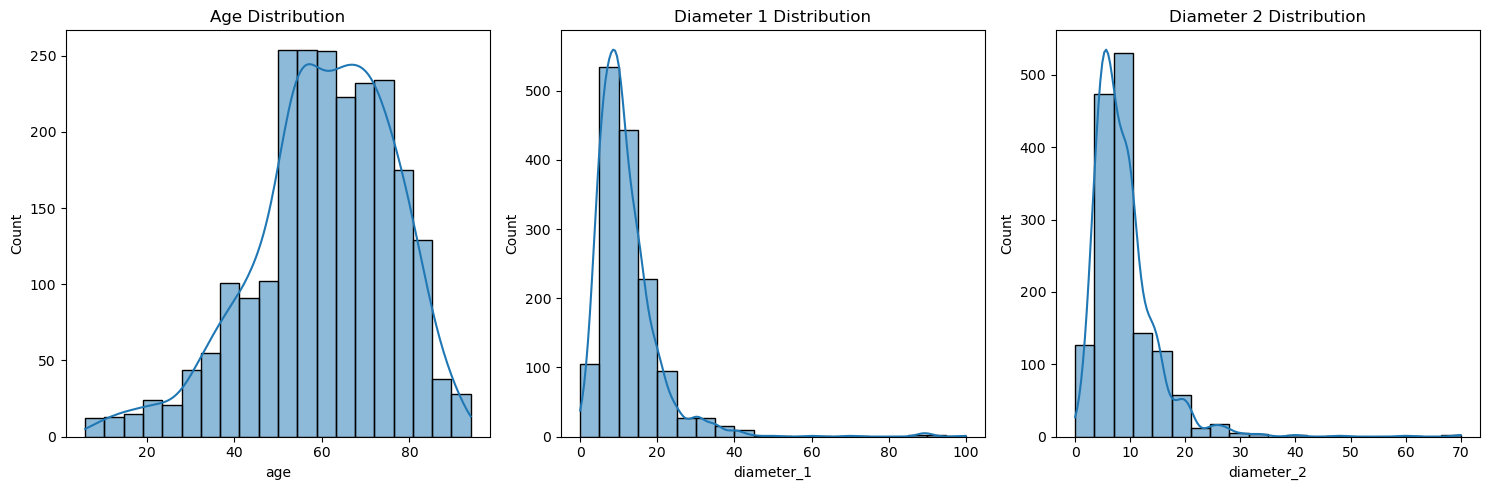

In [24]:
# 9. HISTOGRAMS - NUMERICAL VARIABLES
# Create three subplots
fig, axes = plt.subplots(1, 3, figsize=(15, 5)) #creates one row containing three plots.
# figsize changes the size of the figure

# bins=20 divides the data into 20 intervals
# kde=True adds a smooth curve showing the estimated distribution
# axes[0], axes[1], axes[2] refer to the first, second and third plots

# Age distribution
sns.histplot(data=df, x="age", bins=20, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

# Diameter 1 distribution
sns.histplot(data=df, x="diameter_1", bins=20, kde=True, ax=axes[1])
axes[1].set_title("Diameter 1 Distribution")

# Diameter 2 distribution
sns.histplot(data=df, x="diameter_2", bins=20, kde=True, ax=axes[2])
axes[2].set_title("Diameter 2 Distribution")

# Adjust layout
plt.tight_layout()

# Display plots
plt.show()

# Observations – Numerical Variable Distributions

**Age**
- The age distribution is slightly left-skewed (negatively skewed).
- Most patients are concentrated in the older age groups.

**Diameter 1**
- The distribution is right-skewed (positively skewed).
- Most observations have smaller lesion measurements, with a few considerably larger values.

**Diameter 2**
- The distribution is right-skewed (positively skewed).
- Most observations have smaller lesion measurements, with a few considerably larger values.

### EDA - CATEGORICAL VARIABLES

In [26]:
# 10. EDA - CATEGORICAL VARIABLES
# Count records in each gender category
print(df["gender"].value_counts())

gender
FEMALE    753
MALE      741
Name: count, dtype: int64


In [27]:
# Calculate gender distribution as percentages
print(df["gender"].value_counts(normalize=True) * 100)

gender
FEMALE    50.401606
MALE      49.598394
Name: proportion, dtype: float64


In [28]:
### 804 records are missing gender information,
### so these percentages describe only the 1,494 records where gender is known.

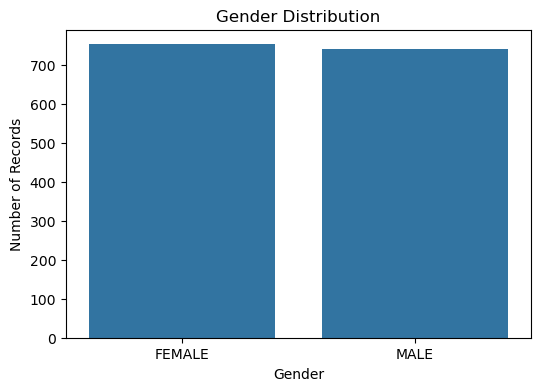

In [29]:
# 11. GENDER DISTRIBUTION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="gender")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Records")

plt.show()

# Gender Distribution
- The dataset contains 753 female records (50.40%) and 741 male records (49.60%) with available gender information.
- The distribution is relatively balanced between the two categories.
- However, 804 records (approximately 35%) have missing gender information.

### EDA - REGION VARIABLES

In [31]:
# 12. REGION DISTRIBUTION
# Count records in each region
print(df["region"].value_counts())

region
FACE       570
FOREARM    392
CHEST      280
BACK       248
ARM        192
NOSE       158
HAND       126
NECK        93
THIGH       73
EAR         73
ABDOMEN     36
LIP         23
SCALP       18
FOOT        16
Name: count, dtype: int64


In [32]:
# Calculate the percentage of records in each region
print(df["region"].value_counts(normalize=True) * 100)

region
FACE       24.804178
FOREARM    17.058312
CHEST      12.184508
BACK       10.791993
ARM         8.355091
NOSE        6.875544
HAND        5.483029
NECK        4.046997
THIGH       3.176675
EAR         3.176675
ABDOMEN     1.566580
LIP         1.000870
SCALP       0.783290
FOOT        0.696258
Name: proportion, dtype: float64


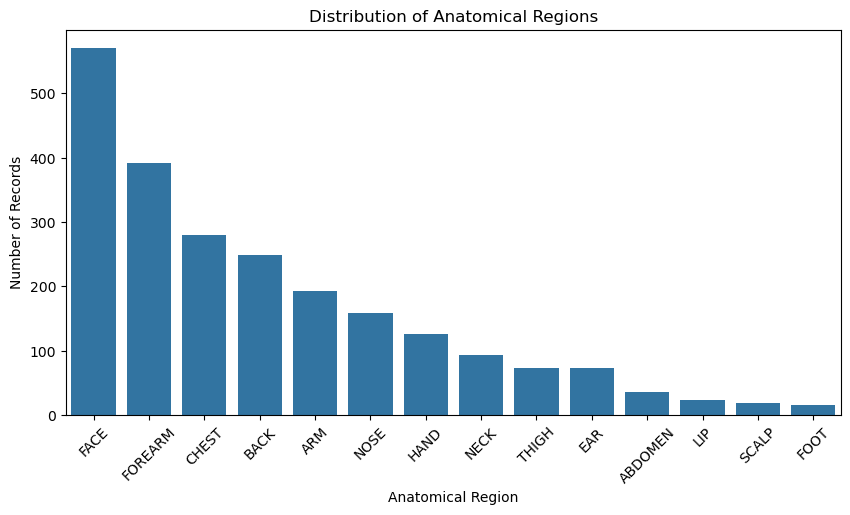

In [33]:
# 13. REGION DISTRIBUTION VISUALISATION

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="region", order=df["region"].value_counts().index)

plt.title("Distribution of Anatomical Regions")
plt.xlabel("Anatomical Region")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

# Region Distribution
- The dataset contains 14 anatomical regions.
- Face is the most represented region (24.80%), followed by forearm (17.06%).
- Foot is the least represented region (0.70%).
- The distribution across anatomical regions is uneven, which may be relevant when evaluating model performance.

### EDA - SMOKING VARIABLES

In [35]:
# 14. SMOKING DISTRIBUTION
# Count records in each smoking category
print(df["smoke"].value_counts())

smoke
False    1292
True      202
Name: count, dtype: int64


In [36]:
# Calculate percentages
print(df["smoke"].value_counts(normalize=True) * 100)

smoke
False    86.47925
True     13.52075
Name: proportion, dtype: float64


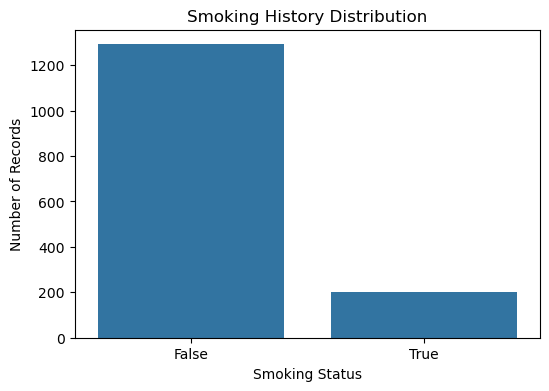

In [37]:
# 15. SMOKING DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="smoke")

plt.title("Smoking History Distribution")
plt.xlabel("Smoking Status")
plt.ylabel("Number of Records")

plt.show()

# Smoking Distribution
- 1,292 records (86.48%) are classified as False.
- 202 records (13.52%) are classified as True.
- The distribution is imbalanced, with substantially more False than True records.
- 804 records have missing smoking information.

### EDA - DRINKING VARIABLES

In [39]:
# 16. DRINKING DISTRIBUTION

# Count records in each drinking category
print(df["drink"].value_counts())

drink
False    1126
True      368
Name: count, dtype: int64


In [40]:
# Calculate percentages
print(df["drink"].value_counts(normalize=True) * 100)

drink
False    75.368139
True     24.631861
Name: proportion, dtype: float64


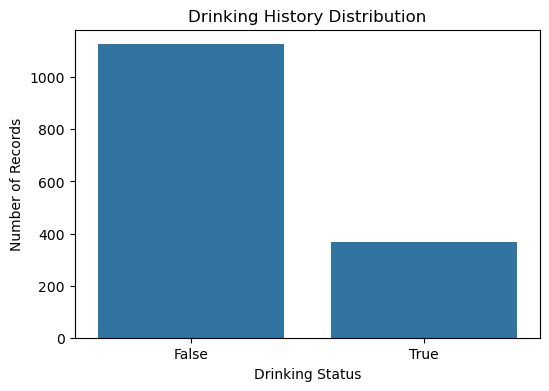

In [41]:
# 17. DRINKING DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="drink")

plt.title("Drinking History Distribution")
plt.xlabel("Drinking Status")
plt.ylabel("Number of Records")

plt.show()

# Drinking Distribution
- 1,126 records (75.37%) are classified as False.
- 368 records (24.63%) are classified as True.
- The distribution is somewhat imbalanced, with more records classified as False.
- 804 records have missing drinking information.

### EDA - FATHER'S BACKGROUND

In [43]:
# 18. FATHER'S BACKGROUND DISTRIBUTION

print(df["background_father"].value_counts())

background_father
POMERANIA      530
GERMANY        466
ITALY          250
UNK             95
BRAZIL          89
NETHERLANDS     19
PORTUGAL        15
POLAND           7
BRASIL           3
CZECH            3
AUSTRIA          1
SPAIN            1
ISRAEL           1
Name: count, dtype: int64


In [44]:
# Calculate percentages
print(df["background_father"].value_counts(normalize=True) * 100)

background_father
POMERANIA      35.810811
GERMANY        31.486486
ITALY          16.891892
UNK             6.418919
BRAZIL          6.013514
NETHERLANDS     1.283784
PORTUGAL        1.013514
POLAND          0.472973
BRASIL          0.202703
CZECH           0.202703
AUSTRIA         0.067568
SPAIN           0.067568
ISRAEL          0.067568
Name: proportion, dtype: float64


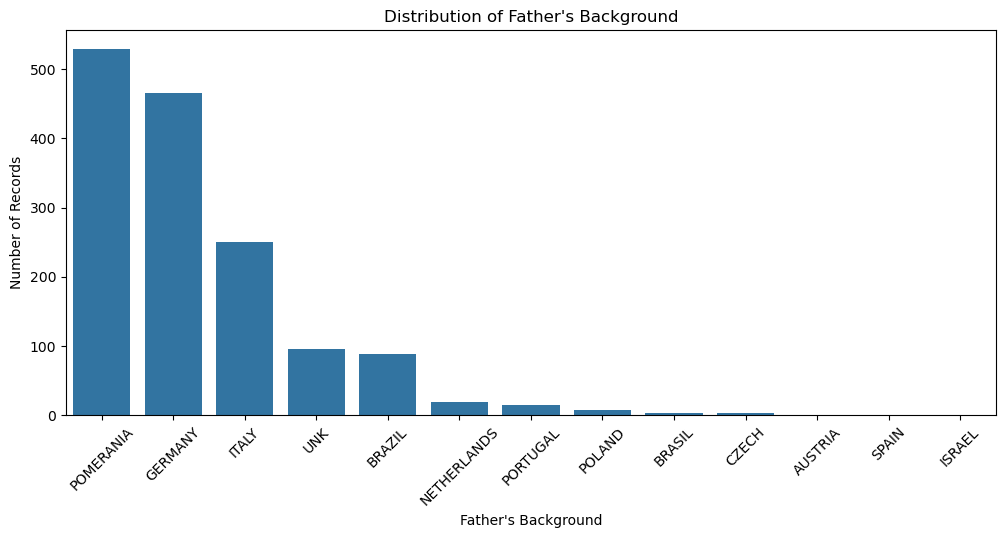

In [45]:
# 19. FATHER'S BACKGROUND VISUALISATION

plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="background_father",
    order=df["background_father"].value_counts().index
)

plt.title("Distribution of Father's Background")
plt.xlabel("Father's Background")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

# Father's Background Distribution
- POMERANIA is the most frequent category (35.81%), followed by GERMANY (31.49%) and ITALY (16.89%).
- These three categories account for approximately 84.19% of available records.
- UNK represents 6.42% of records and may indicate unknown information.
- BRAZIL and BRASIL appear as separate categories, suggesting a possible inconsistency in category naming.
- Several categories have very few observations, resulting in an uneven distribution.

### EDA - MOTHER'S BACKGROUND

In [47]:
# 20. MOTHER'S BACKGROUND DISTRIBUTION
# Count records in each category
print(df["background_mother"].value_counts())

background_mother
POMERANIA      533
GERMANY        482
ITALY          236
UNK             84
BRAZIL          81
PORTUGAL        20
NETHERLANDS     20
POLAND           9
NORWAY           7
FRANCE           2
SPAIN            2
Name: count, dtype: int64


In [48]:
# Calculate percentages
print(df["background_mother"].value_counts(normalize=True) * 100)

background_mother
POMERANIA      36.111111
GERMANY        32.655827
ITALY          15.989160
UNK             5.691057
BRAZIL          5.487805
PORTUGAL        1.355014
NETHERLANDS     1.355014
POLAND          0.609756
NORWAY          0.474255
FRANCE          0.135501
SPAIN           0.135501
Name: proportion, dtype: float64


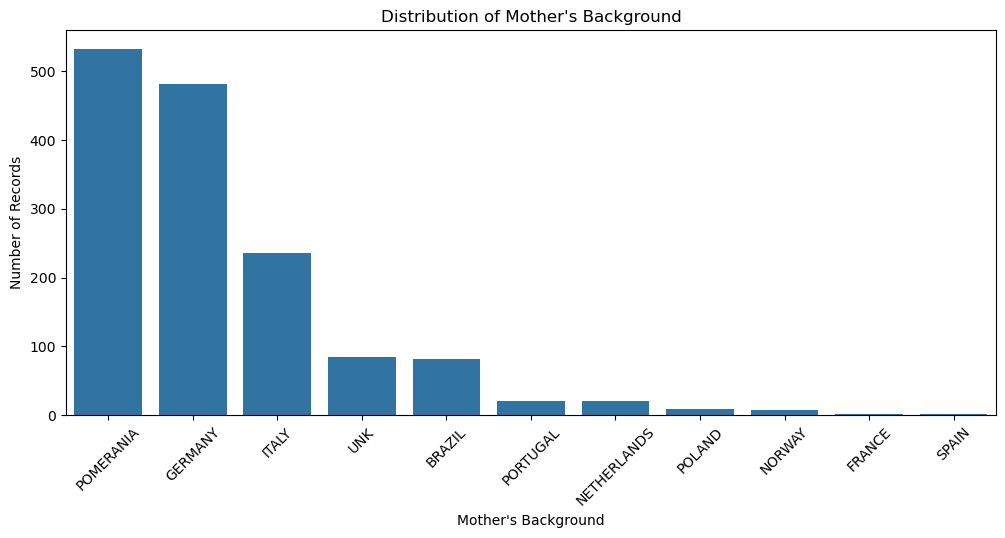

In [49]:
# 21. MOTHER'S BACKGROUND VISUALISATION

plt.figure(figsize=(12, 5))

sns.countplot(
    data=df,
    x="background_mother",
    order=df["background_mother"].value_counts().index
)

plt.title("Distribution of Mother's Background")
plt.xlabel("Mother's Background")
plt.ylabel("Number of Records")

plt.xticks(rotation=45)

plt.show()

# Mother's Background Distribution
- POMERANIA is the most frequent category (36.11%), followed by GERMANY (32.66%) and ITALY (15.99%).
- These three categories account for approximately 84.76% of available records.
- UNK represents 5.69% of records and may indicate unknown information.
- FRANCE and SPAIN have very few observations.
- The distribution is concentrated in a small number of categories.

### EDA - PESTICIDE EXPOSURE 

In [51]:
# 22. PESTICIDE EXPOSURE DISTRIBUTION

print(df["pesticide"].value_counts())

print(df["pesticide"].value_counts(normalize=True) * 100)

pesticide
False    897
True     597
Name: count, dtype: int64
pesticide
False    60.040161
True     39.959839
Name: proportion, dtype: float64


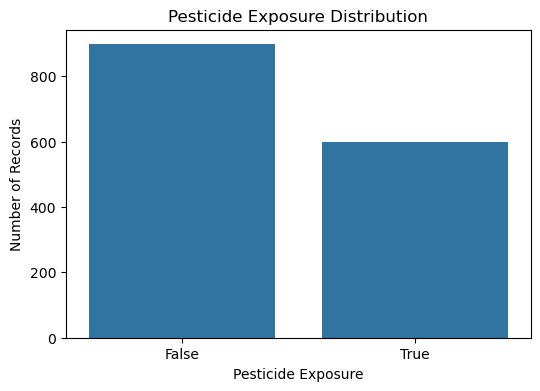

In [52]:
# 23. PESTICIDE EXPOSURE VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="pesticide")

plt.title("Pesticide Exposure Distribution")
plt.xlabel("Pesticide Exposure")
plt.ylabel("Number of Records")

plt.show()

# Pesticide Exposure Distribution
- 897 records (60.04%) are classified as False.
- 597 records (39.96%) are classified as True.
- The distribution is relatively balanced compared with some other categorical variables.
- 804 records have missing pesticide information.

### EDA - SKIN CANCER HISTORY

In [54]:
# 24. SKIN CANCER HISTORY DISTRIBUTION

print(df["skin_cancer_history"].value_counts())

print(df["skin_cancer_history"].value_counts(normalize=True) * 100)

skin_cancer_history
False    813
True     681
Name: count, dtype: int64
skin_cancer_history
False    54.417671
True     45.582329
Name: proportion, dtype: float64


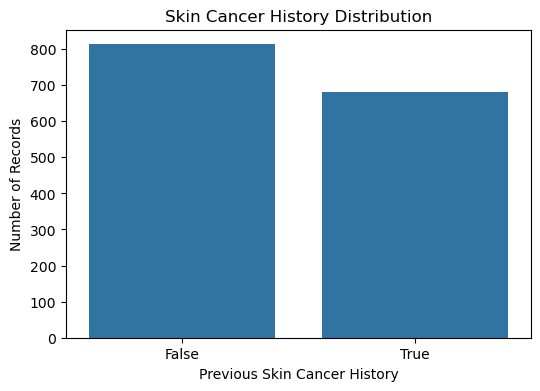

In [55]:
# 25. SKIN CANCER HISTORY VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="skin_cancer_history")

plt.title("Skin Cancer History Distribution")
plt.xlabel("Previous Skin Cancer History")
plt.ylabel("Number of Records")

plt.show()

# Skin Cancer History Distribution
- 813 records (54.42%) are classified as False.
- 681 records (45.58%) are classified as True.
- The distribution is relatively balanced.
- 804 records have missing information.
- This variable represents previous skin cancer history and should be distinguished from the current diagnosis.

### EDA - CANCER HISTORY

In [57]:
# 26. CANCER HISTORY DISTRIBUTION

print(df["cancer_history"].value_counts())

print(df["cancer_history"].value_counts(normalize=True) * 100)

cancer_history
True     779
False    715
Name: count, dtype: int64
cancer_history
True     52.141901
False    47.858099
Name: proportion, dtype: float64


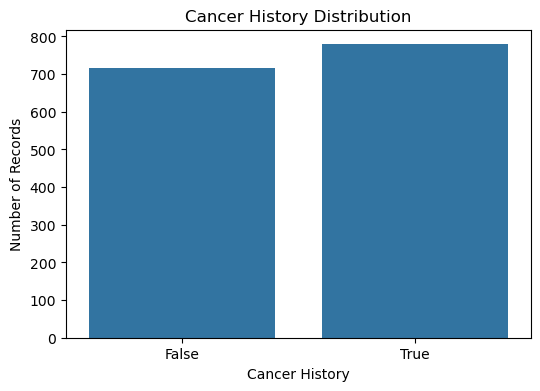

In [58]:
# 27. CANCER HISTORY VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="cancer_history")

plt.title("Cancer History Distribution")
plt.xlabel("Cancer History")
plt.ylabel("Number of Records")

plt.show()

# Cancer History Distribution
- 779 records (52.14%) are classified as True.
- 715 records (47.86%) are classified as False.
- The distribution is relatively balanced.
- 804 records have missing information.
- This variable should be distinguished from skin_cancer_history, as the two may represent different types of medical history.

### EDA - PIPED WATER DISTRIBUTION

In [60]:
# 28. PIPED WATER DISTRIBUTION

print(df["has_piped_water"].value_counts())

print(df["has_piped_water"].value_counts(normalize=True) * 100)

has_piped_water
True     923
False    571
Name: count, dtype: int64
has_piped_water
True     61.780455
False    38.219545
Name: proportion, dtype: float64


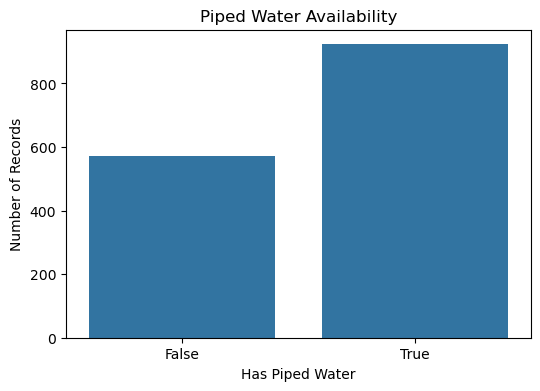

In [61]:
# 29. PIPED WATER DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="has_piped_water")

plt.title("Piped Water Availability")
plt.xlabel("Has Piped Water")
plt.ylabel("Number of Records")

plt.show()

# Piped Water Distribution
- 923 records (61.78%) are classified as True.
- 571 records (38.22%) are classified as False.
- The distribution is moderately uneven.
- 804 records have missing information.

### EDA - SEWAGE SYSTEM DISTRIBUTION

In [435]:
# 30. SEWAGE SYSTEM DISTRIBUTION

print(df["has_sewage_system"].value_counts())

print(df["has_sewage_system"].value_counts(normalize=True) * 100)

has_sewage_system
True     846
False    648
Name: count, dtype: int64
has_sewage_system
True     56.626506
False    43.373494
Name: proportion, dtype: float64


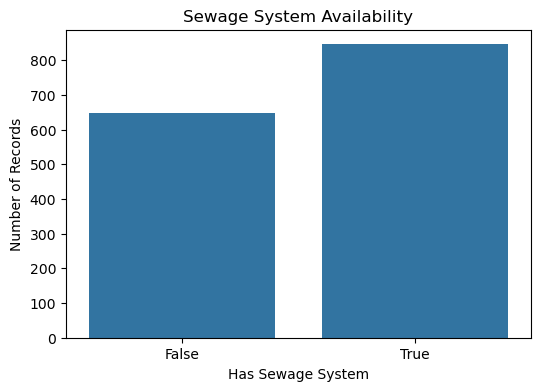

In [64]:
# 31. SEWAGE SYSTEM DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="has_sewage_system")

plt.title("Sewage System Availability")
plt.xlabel("Has Sewage System")
plt.ylabel("Number of Records")

plt.show()

# Sewage System Distribution
- 846 records (56.63%) are classified as True.
- 648 records (43.37%) are classified as False.
- The distribution is relatively balanced.
- 804 records have missing information.

### EDA - FITSPATRICK

In [66]:
# 32. FITZPATRICK SKIN TYPE DISTRIBUTION

print(df["fitspatrick"].value_counts())

print(df["fitspatrick"].value_counts(normalize=True) * 100)

fitspatrick
2.0    876
3.0    392
1.0    153
4.0     62
5.0     10
6.0      1
Name: count, dtype: int64
fitspatrick
2.0    58.634538
3.0    26.238286
1.0    10.240964
4.0     4.149933
5.0     0.669344
6.0     0.066934
Name: proportion, dtype: float64


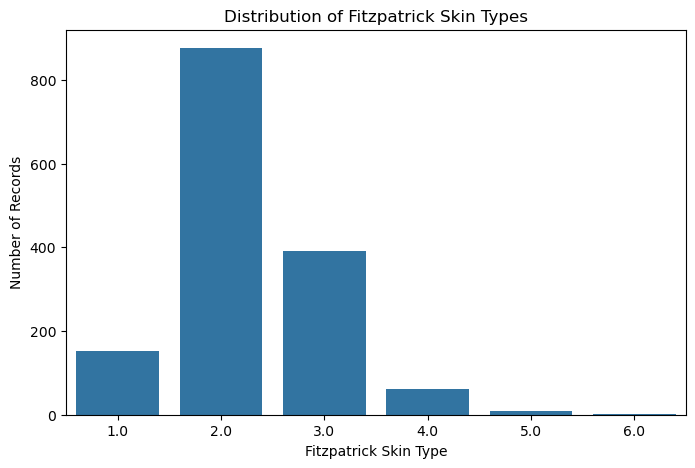

In [67]:
# 33. FITZPATRICK SKIN TYPE VISUALISATION

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="fitspatrick",
    order=sorted(df["fitspatrick"].dropna().unique())
)

plt.title("Distribution of Fitzpatrick Skin Types")
plt.xlabel("Fitzpatrick Skin Type")
plt.ylabel("Number of Records")

plt.show()

It refers to the Fitzpatrick skin phototype scale, which classifies skin according to its response to sunlight, particularly its tendency to burn or tan.

It has six types, ranging from Type I to Type VI.

 Fitzpatrick Skin Type Distribution
- Type II is the most frequent category (58.63%), followed by Type III (26.24%).
- Types II and III account for approximately 84.87% of available records.
- Type VI is extremely underrepresented, with only one observation.
- The distribution is highly concentrated in Types II and III.
- Fitzpatrick skin type is an ordinal categorical variable because the categories have a meaningful order (I to VI).

### EDA - ITCH DISTRIBUTION

In [69]:
# 34. ITCH DISTRIBUTION

# Count records in each category
print(df["itch"].value_counts())

# Calculate percentages
print(df["itch"].value_counts(normalize=True) * 100)

itch
TRUE     1455
FALSE     837
UNK         6
Name: count, dtype: int64
itch
TRUE     63.315927
FALSE    36.422977
UNK       0.261097
Name: proportion, dtype: float64


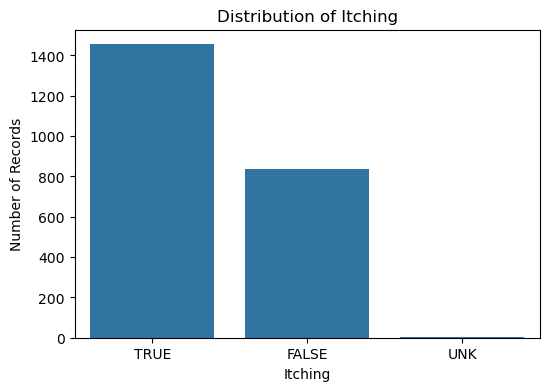

In [70]:
# 35. ITCH DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="itch",
    order=df["itch"].value_counts().index
)

plt.title("Distribution of Itching")
plt.xlabel("Itching")
plt.ylabel("Number of Records")

plt.show()

In [71]:
# Itch Distribution
# - TRUE represents 63.32% of records, while FALSE represents 36.42%.
# - Only 6 records (0.26%) are classified as UNK.
# - The variable has three categories and no missing values.
# - UNK represents an explicit unknown category that may require consideration during preprocessing.

### EDA - GREW DISTRIBUTION

In [72]:
# 36. LESION GROWTH DISTRIBUTION

print(df["grew"].value_counts())

print(df["grew"].value_counts(normalize=True) * 100)

grew
FALSE    971
TRUE     925
UNK      402
Name: count, dtype: int64
grew
FALSE    42.254134
TRUE     40.252393
UNK      17.493473
Name: proportion, dtype: float64


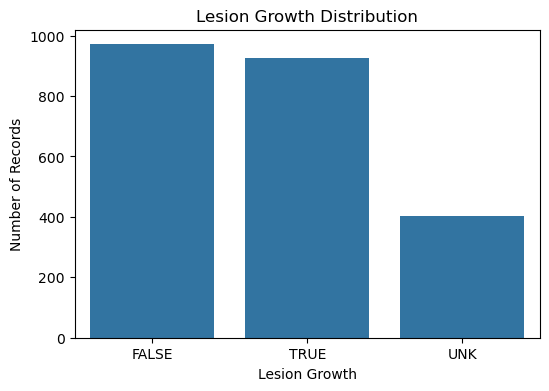

In [73]:
# 37. LESION GROWTH DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="grew",
    order=df["grew"].value_counts().index
)

plt.title("Lesion Growth Distribution")
plt.xlabel("Lesion Growth")
plt.ylabel("Number of Records")

plt.show()

# Lesion Growth Distribution
- 971 records (42.25%) are classified as FALSE.
- 925 records (40.25%) are classified as TRUE.
- 402 records (17.49%) are classified as UNK.
- The TRUE and FALSE categories are relatively balanced.
- A considerable proportion of records have an explicitly unknown growth status.

### EDA - HURT

In [75]:
# 38. LESION PAIN DISTRIBUTION

print(df["hurt"].value_counts())

print(df["hurt"].value_counts(normalize=True) * 100)

hurt
FALSE    1891
TRUE      397
UNK        10
Name: count, dtype: int64
hurt
FALSE    82.288947
TRUE     17.275892
UNK       0.435161
Name: proportion, dtype: float64


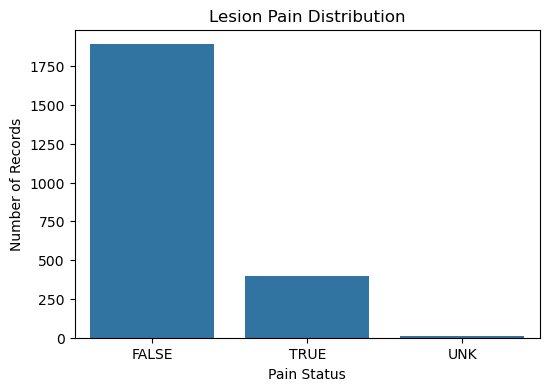

In [76]:
# 39. LESION PAIN DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="hurt",
    order=df["hurt"].value_counts().index
)

plt.title("Lesion Pain Distribution")
plt.xlabel("Pain Status")
plt.ylabel("Number of Records")

plt.show()

# Lesion Pain Distribution
- 1,891 records (82.29%) are classified as FALSE.
- 397 records (17.28%) are classified as TRUE.
- 10 records (0.44%) are classified as UNK.
- The distribution is heavily concentrated in the FALSE category.
- The variable contains an explicitly unknown category.

### EDA - CHANGED

In [78]:
# 40. LESION CHANGE DISTRIBUTION

print(df["changed"].value_counts())

print(df["changed"].value_counts(normalize=True) * 100)

changed
FALSE    1700
UNK       396
TRUE      202
Name: count, dtype: int64
changed
FALSE    73.977372
UNK      17.232376
TRUE      8.790252
Name: proportion, dtype: float64


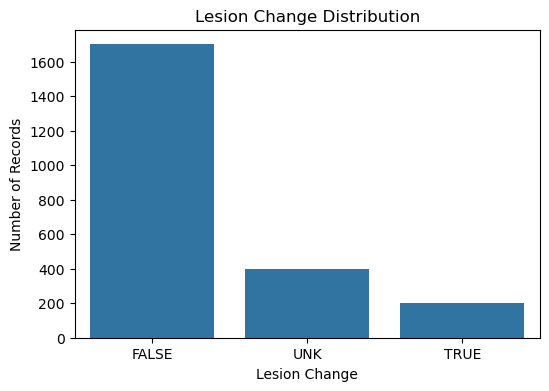

In [79]:
# 41. LESION CHANGE DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="changed",
    order=df["changed"].value_counts().index
)

plt.title("Lesion Change Distribution")
plt.xlabel("Lesion Change")
plt.ylabel("Number of Records")

plt.show()

# Lesion Change Distribution
- 1,700 records (73.98%) are classified as FALSE.
- 202 records (8.79%) are classified as TRUE.
- 396 records (17.23%) are classified as UNK.
- The distribution is heavily concentrated in FALSE.
- A considerable proportion of records have an explicitly unknown status.

### EDA - BLEED

In [81]:
# 42. LESION BLEEDING DISTRIBUTION

print(df["bleed"].value_counts())

print(df["bleed"].value_counts(normalize=True) * 100)

bleed
FALSE    1678
TRUE      614
UNK         6
Name: count, dtype: int64
bleed
FALSE    73.020017
TRUE     26.718886
UNK       0.261097
Name: proportion, dtype: float64


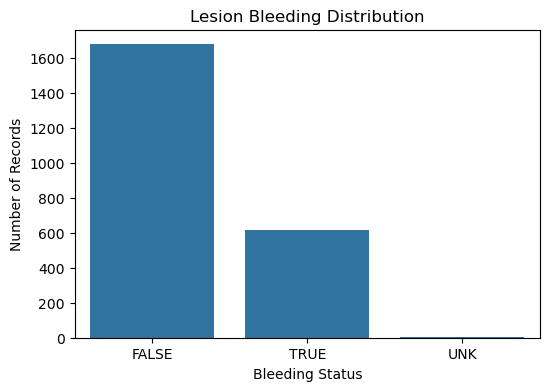

In [82]:
# 43. LESION BLEEDING DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="bleed",
    order=df["bleed"].value_counts().index
)

plt.title("Lesion Bleeding Distribution")
plt.xlabel("Bleeding Status")
plt.ylabel("Number of Records")

plt.show()

# Lesion Bleeding Distribution
- 1,678 records (73.02%) are classified as FALSE.
- 614 records (26.72%) are classified as TRUE.
- 6 records (0.26%) are classified as UNK.
- The distribution is concentrated in FALSE.
- The variable contains an explicitly unknown category.

### EDA - ELEVATION

In [84]:
# 44. LESION ELEVATION DISTRIBUTION

print(df["elevation"].value_counts())

print(df["elevation"].value_counts(normalize=True) * 100)

elevation
TRUE     1433
FALSE     863
UNK         2
Name: count, dtype: int64
elevation
TRUE     62.358573
FALSE    37.554395
UNK       0.087032
Name: proportion, dtype: float64


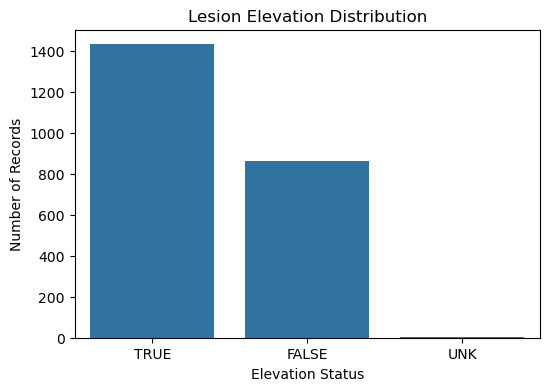

In [85]:
# 45. LESION ELEVATION DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="elevation",
    order=df["elevation"].value_counts().index
)

plt.title("Lesion Elevation Distribution")
plt.xlabel("Elevation Status")
plt.ylabel("Number of Records")

plt.show()

# Lesion Elevation Distribution
- 1,433 records (62.36%) are classified as TRUE.
- 863 records (37.55%) are classified as FALSE.
- Only 2 records (0.09%) are classified as UNK.
- The distribution is moderately concentrated in TRUE.

### EDA - BIOPSY

In [87]:
# 46. BIOPSY DISTRIBUTION

print(df["biopsed"].value_counts())

print(df["biopsed"].value_counts(normalize=True) * 100)

biopsed
True     1342
False     956
Name: count, dtype: int64
biopsed
True     58.398607
False    41.601393
Name: proportion, dtype: float64


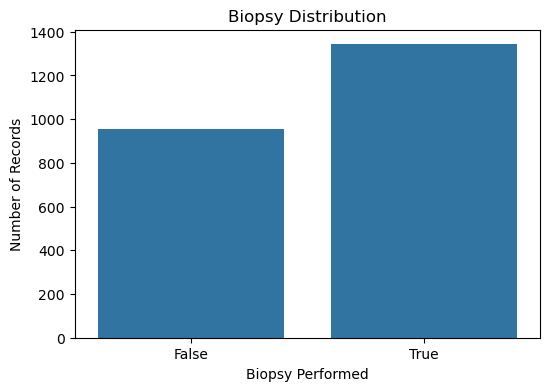

In [88]:
# 47. BIOPSY DISTRIBUTION VISUALISATION

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="biopsed")

plt.title("Biopsy Distribution")
plt.xlabel("Biopsy Performed")
plt.ylabel("Number of Records")

plt.show()

# Biopsy Distribution
- 1,342 records (58.40%) are classified as True.
- 956 records (41.60%) are classified as False.
- The distribution is relatively balanced.
- There are no missing values.

### EDA - DIAGNOSTIC

In [90]:
# 48. DIAGNOSTIC DISTRIBUTION

# Count records in each diagnostic category
print(df["diagnostic"].value_counts())

# Calculate percentages
print(df["diagnostic"].value_counts(normalize=True) * 100)

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64
diagnostic
BCC    36.771105
ACK    31.766754
NEV    10.617929
SEK    10.226284
SCC     8.355091
MEL     2.262837
Name: proportion, dtype: float64


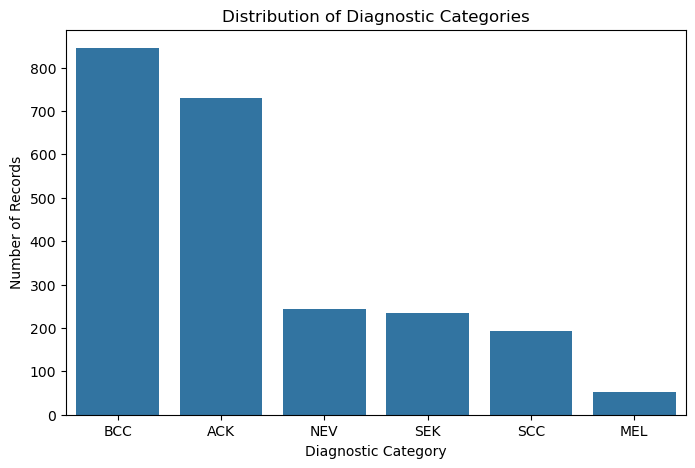

In [91]:
# 49. DIAGNOSTIC DISTRIBUTION

plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="diagnostic",
              order=df["diagnostic"].value_counts().index)

plt.title("Distribution of Diagnostic Categories")
plt.xlabel("Diagnostic Category")
plt.ylabel("Number of Records")

plt.show()

# ### Diagnostic Distribution

The target variable contains six diagnostic categories. 
BCC is the most frequent category, representing approximately 
36.77% of the dataset, followed by ACK at 31.77%.

MEL is the least represented category, accounting for only 
2.26% of the records.

The distribution indicates class imbalance. This may affect 
model performance, particularly when predicting minority 
classes. Therefore, accuracy alone may not be a sufficient 
evaluation metric. We will also consider precision, recall, 
F1-score and the confusion matrix.

# Stage 3 - Exploratory Data Analysis - Bivariate Analysis

### EDA - GENDER VS DIAGNOSIS

In [93]:
# BIVARIATE ANALYSIS
# GENDER VS DIAGNOSTIC

# 50. Create a cross-tabulation
pd.crosstab(df["gender"], df["diagnostic"])

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
gender,,,,,,
FEMALE,153,406,28,49,90,27
MALE,130,439,24,26,102,20


# A few observations:
- BCC is the most frequent diagnosis in both groups.
- BCC has more male records (439) than female records (406).
- NEV has almost twice as many female records (49) as male records (26).
- SCC has more male records (102) than female records (90).
- MEL has relatively few records in both groups.

In [95]:
# 51. Calculate percentages within each gender
pd.crosstab(
    df["gender"],
    df["diagnostic"],
    normalize="index"
) * 100

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
gender,,,,,,
FEMALE,20.318725,53.917663,3.718459,6.507304,11.952191,3.585657
MALE,17.543860,59.244265,3.238866,3.508772,13.765182,2.699055


A cross-tabulation was used to examine the relationship between 
gender and diagnostic category.

BCC was the most frequent diagnosis in both gender groups.
It represented 53.92% of female records and 59.24% of male records.

ACK and NEV represented a higher proportion of female records,
while BCC and SCC represented a higher proportion of male records.

These observations suggest differences in diagnostic distributions
between the two groups. However, further statistical analysis would
be required to determine whether these associations are significant.

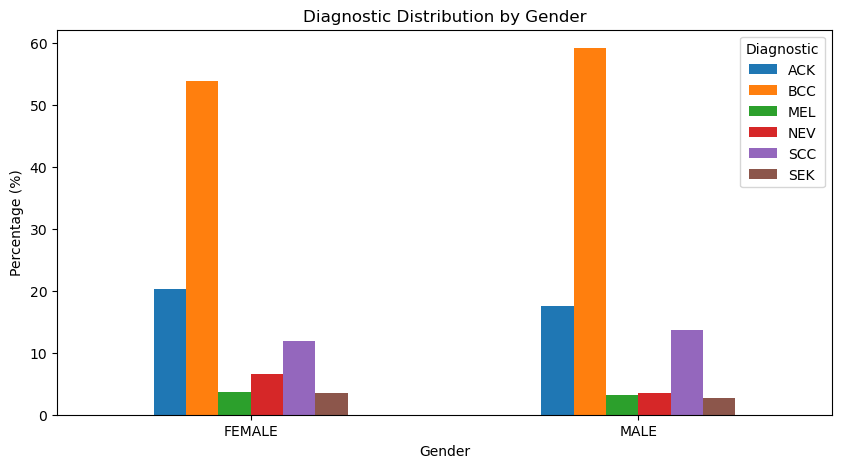

In [97]:
# 52. GENDER VS DIAGNOSTIC - BAR CHART

gender_diagnosis = pd.crosstab(
    df["gender"],
    df["diagnostic"],
    normalize="index"
) * 100

gender_diagnosis.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Diagnostic Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Diagnostic")
plt.show()

### EDA - REGION VS DIAGNOSTIC

In [98]:
# 53. REGION VS DIAGNOSTIC

# Count records for each region and diagnostic category
pd.crosstab(df["region"], df["diagnostic"])

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
region,,,,,,
ABDOMEN,3,2,2,19,2,8
ARM,91,44,7,10,21,19
BACK,16,91,14,86,17,24
CHEST,60,135,5,29,20,31
EAR,11,36,2,3,13,8
FACE,139,260,5,38,29,99
FOOT,4,0,0,6,6,0
FOREARM,261,67,5,10,28,21
HAND,78,19,2,6,19,2


In [99]:
# 54. Calculate percentages within each body region
pd.crosstab(
    df["region"],
    df["diagnostic"],
    normalize="index"
) * 100

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
region,,,,,,
ABDOMEN,8.333333,5.555556,5.555556,52.777778,5.555556,22.222222
ARM,47.395833,22.916667,3.645833,5.208333,10.937500,9.895833
BACK,6.451613,36.693548,5.645161,34.677419,6.854839,9.677419
CHEST,21.428571,48.214286,1.785714,10.357143,7.142857,11.071429
EAR,15.068493,49.315068,2.739726,4.109589,17.808219,10.958904
FACE,24.385965,45.614035,0.877193,6.666667,5.087719,17.368421
FOOT,25.000000,0.000000,0.000000,37.500000,37.500000,0.000000
FOREARM,66.581633,17.091837,1.275510,2.551020,7.142857,5.357143
HAND,61.904762,15.079365,1.587302,4.761905,15.079365,1.587302


# Region vs Diagnostic Category

A cross-tabulation was used to investigate the relationship 
between lesion location and diagnostic category.

The results show differences in diagnostic distributions 
across body regions.

ACK represented the largest proportion of records on the 
forearm (66.58%) and hand (61.90%), whereas BCC was the 
largest category on the nose (77.85%), ear (49.32%), 
chest (48.21%) and face (45.61%).

NEV represented 52.78% of abdomen records and 50% of 
scalp records. However, these regions had relatively 
small sample sizes.

The findings suggest that lesion location may be a useful 
feature to investigate during classification. However, 
these descriptive results do not establish causation.

### EDA - AGE VS DIAGNOSITC

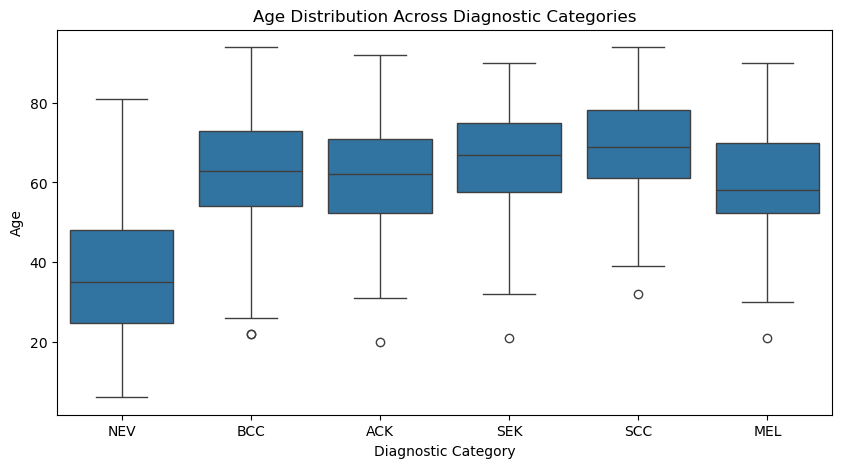

In [101]:
# 55. AGE VS DIAGNOSTIC

plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="diagnostic", y="age")

plt.title("Age Distribution Across Diagnostic Categories")
plt.xlabel("Diagnostic Category")
plt.ylabel("Age")

plt.show()

In [102]:
# 56. Age statistics for each diagnostic category
df.groupby("diagnostic")["age"].describe()

,count,mean,std,min,25%,50%,75%,max
diagnostic,,,,,,,,
ACK,730.0,61.749315,12.696042,20.0,52.25,62.0,71.00,92.0
BCC,845.0,63.146746,13.459515,22.0,54.00,63.0,73.00,94.0
MEL,52.0,59.826923,13.865914,21.0,52.25,58.0,70.00,90.0
NEV,244.0,35.643443,15.581193,6.0,24.75,35.0,48.00,81.0
SCC,192.0,68.864583,12.210304,32.0,61.00,69.0,78.25,94.0
SEK,235.0,65.880851,12.155802,21.0,57.50,67.0,75.00,90.0


# Age vs Diagnostic Category

Age statistics were grouped by diagnostic category to examine 
differences in age distributions.

SCC had the highest mean age (68.86), followed by SEK (65.88) 
and BCC (63.15).

NEV had a considerably lower mean age of 35.64 compared with 
the other diagnostic categories.

The median age followed a similar pattern, with NEV at 35 
and SCC at 69.

These observations suggest that age may be a useful feature 
for distinguishing between diagnostic categories. However, 
further model evaluation is required to determine its predictive value.

### EDA - Fitzpatrick skin type vs diagnosis

In [104]:
# 57. FITZPATRICK SKIN TYPE VS DIAGNOSTIC

pd.crosstab(
    df["fitspatrick"],
    df["diagnostic"]
)

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
fitspatrick,,,,,,
1.0,25,101,3,4,16,4
2.0,156,502,35,34,126,23
3.0,89,217,10,24,45,7
4.0,10,22,4,12,3,11
5.0,3,3,0,1,2,1
6.0,0,0,0,0,0,1


# A few observations:
- Type II has the highest number of records across the dataset.
- BCC is the most frequent diagnosis for Types I, II and III.
- Type IV has a more varied distribution, with BCC (22) and NEV (12) among its more frequent categories.
- Type V has very few records (10 in total).
- Type VI has only one record, classified as SEK.
- Note, these are raw counts. Type II has many more records than the other skin types, so we should calculate percentages before comparing distributions.

In [106]:
# 58. Calculate percentages within each Fitzpatrick skin type
pd.crosstab(
    df["fitspatrick"],
    df["diagnostic"],
    normalize="index"
) * 100

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
fitspatrick,,,,,,
1.0,16.339869,66.013072,1.960784,2.614379,10.457516,2.614379
2.0,17.808219,57.305936,3.995434,3.881279,14.383562,2.625571
3.0,22.704082,55.357143,2.551020,6.122449,11.479592,1.785714
4.0,16.129032,35.483871,6.451613,19.354839,4.838710,17.741935
5.0,30.000000,30.000000,0.000000,10.000000,20.000000,10.000000
6.0,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000


# ### Fitzpatrick Skin Type vs Diagnostic Category

A cross-tabulation was used to investigate the relationship 
between Fitzpatrick skin type and diagnostic category.

BCC was the most frequent diagnosis among Types I, II, III 
and IV. Its proportion decreased from 66.01% in Type I 
to 35.48% in Type IV.

Type IV showed a more varied distribution of diagnostic 
categories compared with Types I–III.

Types V and VI had very small sample sizes (10 and 1 
records respectively). Therefore, their percentages should 
be interpreted cautiously.

These observations suggest that Fitzpatrick skin type may 
be worth investigating as a predictive feature. However, 
further model evaluation is required.

### EDA - Lesion Diameter 1 vs Diagnosis

In [108]:
# 59. DIAMETER 1 VS DIAGNOSTIC

df.groupby("diagnostic")["diameter_1"].describe()

,count,mean,std,min,25%,50%,75%,max
diagnostic,,,,,,,,
ACK,283.0,10.978799,7.108050,1.0,6.00,10.0,13.0,50.0
BCC,845.0,12.049941,8.118752,0.0,7.00,10.0,15.0,100.0
MEL,52.0,15.153846,7.606459,5.0,9.00,13.5,20.0,40.0
NEV,75.0,12.133333,17.510100,2.0,5.00,7.0,10.0,89.0
SCC,192.0,12.223958,8.407604,0.0,7.75,10.0,15.0,90.0
SEK,47.0,9.361702,5.006194,3.0,6.00,8.0,12.5,25.0


# ### Diameter 1 vs Diagnostic Category

Descriptive statistics were calculated to compare diameter_1 
across the six diagnostic categories.

MEL had the highest mean diameter (15.15) and median (13.5), 
while SEK had the lowest mean (9.36) and median (8).

NEV showed considerable variability, with a standard deviation 
of 17.51 and a maximum value of 89, despite a median of 7.

Large maximum values were also observed for BCC (100) and 
SCC (90), suggesting potential extreme values that require 
further investigation.

Only 1,494 records had available diameter_1 measurements, 
with 804 missing values.

### EDA - Lesion Diameter 2 vs Diagnosis

In [110]:
# 60. DIAMETER 2 VS DIAGNOSTIC

df.groupby("diagnostic")["diameter_2"].describe()

,count,mean,std,min,25%,50%,75%,max
diagnostic,,,,,,,,
ACK,283.0,8.187279,5.220348,1.0,5.0,7.0,10.00,48.0
BCC,845.0,9.022722,6.017097,0.0,5.0,8.0,11.00,70.0
MEL,52.0,11.173077,6.498027,3.0,7.0,10.0,12.50,34.0
NEV,75.0,7.346667,6.636291,2.0,4.0,5.0,8.50,40.0
SCC,192.0,9.515625,5.117444,0.0,6.0,8.0,12.25,33.0
SEK,47.0,6.914894,3.775377,2.0,4.0,6.0,8.50,15.0


# ### Diameter 2 vs Diagnostic Category

Descriptive statistics were calculated to compare diameter_2 
across the six diagnostic categories.

MEL had the highest mean diameter (11.17) and median (10), 
while SEK had the lowest mean (6.91) and median (6).

NEV showed considerable variability, with a standard deviation 
of 6.64 relative to its median of 5.

BCC had the highest maximum measurement of 70, suggesting 
potential extreme values that require further investigation.

Only 1,494 records had available diameter_2 measurements, 
with 804 missing values.

### CORRELATION ANALYSIS

# What is correlation?
Correlation measures how two numerical variables move in relation to each other.

For example, in our dataset:
- Does age tend to increase when diameter_1 increases?
- Do diameter_1 and diameter_2 tend to increase together?
Correlation values range from -1 to +1.
Correlation	Meaning
 +1	Perfect positive relationship
Close to +1	Strong positive relationship
0	Little or no linear relationship
Close to -1	Strong negative relationship
-1	Perfect negative relationship

A positive correlation means that when one variable increases, the other tends to increase.

A negative correlation means that when one increases, the other tends to decrease.

Note: correlation does not establish causation.

In [113]:
# 61. CORRELATION ANALYSIS

# Select numerical variables
numerical_df = df[["age", "diameter_1", "diameter_2"]]

# Calculate correlation matrix
correlation_matrix = numerical_df.corr()

# Display results
correlation_matrix

,age,diameter_1,diameter_2
age,1.000000,-0.000525,0.054748
diameter_1,-0.000525,1.000000,0.858215
diameter_2,0.054748,0.858215,1.000000


Correlation measures the strength and direction of the linear relationship
between two numerical variables.

Correlation values range from -1 to +1:
+1 = Perfect positive correlation
0 = No linear correlation
-1 = Perfect negative correlation

Positive correlation: Both variables tend to increase together.
Negative correlation: One variable tends to decrease as the other increases.

Correlation does not imply causation.

# ### Correlation Analysis

Pearson correlation was used to examine relationships 
between the numerical variables.

Age showed almost no linear correlation with diameter_1 
(-0.0005) or diameter_2 (0.0547).

However, diameter_1 and diameter_2 showed a strong 
positive correlation of 0.8582.

This indicates that the two lesion measurements tend 
to increase together and may contain overlapping 
information.

Both variables will be retained for further investigation 
during feature selection.

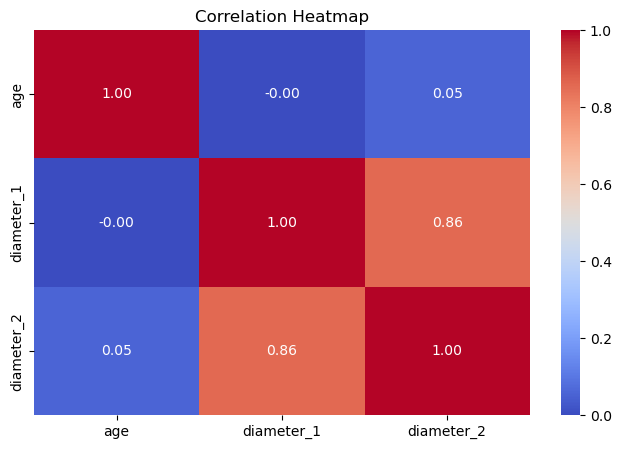

In [116]:
# 62. CORRELATION HEATMAP

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

### OUTLIER ANALYSIS

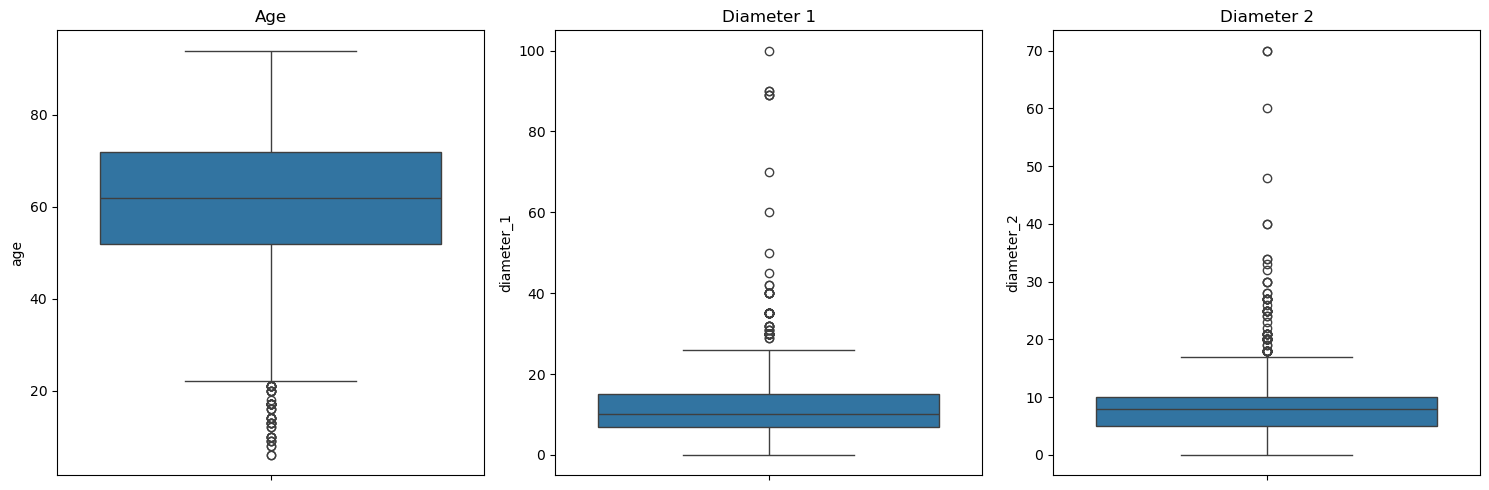

In [117]:
# 63. OUTLIER ANALYSIS

# Create boxplots for numerical variables
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.boxplot(data=df, y="age", ax=axes[0])
axes[0].set_title("Age")

sns.boxplot(data=df, y="diameter_1", ax=axes[1])
axes[1].set_title("Diameter 1")

sns.boxplot(data=df, y="diameter_2", ax=axes[2])
axes[2].set_title("Diameter 2")

plt.tight_layout()
plt.show()

### Calculate quartiles for Age

In [118]:
# 64. Calculate quartiles
Q1 = df["age"].quantile(0.25)
Q3 = df["age"].quantile(0.75)

# Calculate Interquartile Range
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 52.0
Q3: 72.0
IQR: 20.0
Lower Bound: 22.0
Upper Bound: 102.0


In [119]:
# 65. Identify potential outliers
outliers = df[
    (df["age"] < lower_bound) |
    (df["age"] > upper_bound)
]

print("Number of potential outliers:", len(outliers))

Number of potential outliers: 53


In [120]:
# 66. Display potential age outliers
print(outliers["age"].sort_values().to_list())

[6, 6, 8, 8, 9, 9, 9, 10, 10, 10, 10, 10, 12, 12, 13, 13, 13, 13, 13, 14, 14, 14, 14, 14, 14, 16, 16, 16, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 18, 20, 20, 20, 20, 20, 21, 21, 21, 21, 21, 21, 21, 21]


# Age Outlier Analysis

Using the IQR method, 53 potential outliers were identified in the age variable.

All identified values were below the lower boundary of 22, ranging from 6 to 21 years.

These observations were not removed because they may represent genuine patient records rather than data-entry errors.

### Calculate Quartiles for Diameter 1

In [122]:
# 67. Calculate quartiles
Q1 = df["diameter_1"].quantile(0.25)
Q3 = df["diameter_1"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 7.0
Q3: 15.0
IQR: 8.0
Lower Bound: -5.0
Upper Bound: 27.0


In [123]:
# 68. Identify potential outliers
outliers_d1 = df[
    (df["diameter_1"] < lower_bound) |
    (df["diameter_1"] > upper_bound)
]

print("Number of potential outliers:", len(outliers_d1))

Number of potential outliers: 63


In [124]:
# 69. Display potential outlier values
print(outliers_d1["diameter_1"].sort_values().to_list())

[29.0, 29.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 30.0, 31.0, 31.0, 31.0, 32.0, 32.0, 32.0, 32.0, 32.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 35.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 40.0, 42.0, 42.0, 45.0, 50.0, 60.0, 70.0, 89.0, 89.0, 89.0, 90.0, 90.0, 100.0]


# Diameter 1 Outlier Analysis

Using the IQR method, 63 potential outliers were identified in diameter_1.

The upper boundary was 27, and the identified values ranged from 29 to 100.

Most potential outliers were between 29 and 40, with a few considerably larger values.

These observations were retained for further investigation because they may represent genuine measurements rather than data-entry errors.

### Calculate Quartiles for Diameter 2

In [126]:
# 70. Calculate quartiles
Q1 = df["diameter_2"].quantile(0.25)
Q3 = df["diameter_2"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

# Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 5.0
Q3: 10.0
IQR: 5.0
Lower Bound: -2.5
Upper Bound: 17.5


In [127]:
# 71. Identify potential outliers
outliers_d2 = df[
    (df["diameter_2"] < lower_bound) |
    (df["diameter_2"] > upper_bound)
]

print("Number of potential outliers:", len(outliers_d2))

Number of potential outliers: 102


In [128]:
# 72. Display potential outlier values
print(outliers_d2["diameter_2"].sort_values().to_list())

[18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 18.0, 19.0, 19.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 20.0, 21.0, 21.0, 21.0, 21.0, 21.0, 21.0, 21.0, 21.0, 22.0, 23.0, 24.0, 24.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 25.0, 26.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 27.0, 28.0, 28.0, 30.0, 30.0, 30.0, 32.0, 33.0, 34.0, 34.0, 40.0, 40.0, 48.0, 60.0, 70.0, 70.0]


# Outlier Analysis

The Interquartile Range (IQR) method was used to identify potential outliers in the numerical variables.

- **Age:** 53 potential outliers were identified, ranging from 6 to 21 years.
- **Diameter 1:** 63 potential outliers were identified, ranging from 29 to 100.
- **Diameter 2:** 102 potential outliers were identified, ranging from 18 to 70.

The diameter variables showed potential outliers on the upper end of their distributions, consistent with their right-skewed distributions.

The identified observations were not removed because they may represent genuine patient measurements. Further investigation is required before deciding whether any values should be modified or excluded.

### Missing Value Patterns

In [130]:
# 73. MISSING VALUE PATTERN ANALYSIS

# Count missing values in each row
missing_per_row = df.isnull().sum(axis=1)

# Count how many rows have each number of missing values
missing_per_row.value_counts().sort_index()

0     1474
1        8
2       12
13     804
Name: count, dtype: int64

In [131]:
# 74. Select rows with exactly 13 missing values
rows_with_13_missing = df[missing_per_row == 13]

# Display columns that contain missing values
rows_with_13_missing.isnull().sum()

patient_id               0
lesion_id                0
smoke                  804
drink                  804
background_father      804
background_mother      804
age                      0
pesticide              804
gender                 804
skin_cancer_history    804
cancer_history         804
has_piped_water        804
has_sewage_system      804
fitspatrick            804
region                   0
diameter_1             804
diameter_2             804
diagnostic               0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                    0
elevation                0
img_id                   0
biopsed                  0
dtype: int64

# Missing Value Pattern Analysis

The missing-value investigation revealed that 804 records contain exactly 13 missing values.

The missing values occur consistently in the same 13 columns, including demographic information, medical history, skin characteristics and lesion measurements.

The remaining 1,494 records contain complete information in these columns.

This suggests a structured missing-data pattern rather than completely random missing values.

The reason for this pattern requires further investigation before selecting an imputation strategy.

In [133]:
# 75. Compare diagnostic distributions
# between complete and incomplete records

df["missing_group"] = np.where(
    missing_per_row == 0,
    "Complete",
    "Incomplete"
)

pd.crosstab(
    df["missing_group"],
    df["diagnostic"],
    normalize="index"
) * 100

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
missing_group,,,,,,
Complete,18.521031,57.327001,3.527815,4.884668,13.02578,2.713704
Incomplete,55.461165,0.000000,0.000000,20.873786,0.00000,23.665049


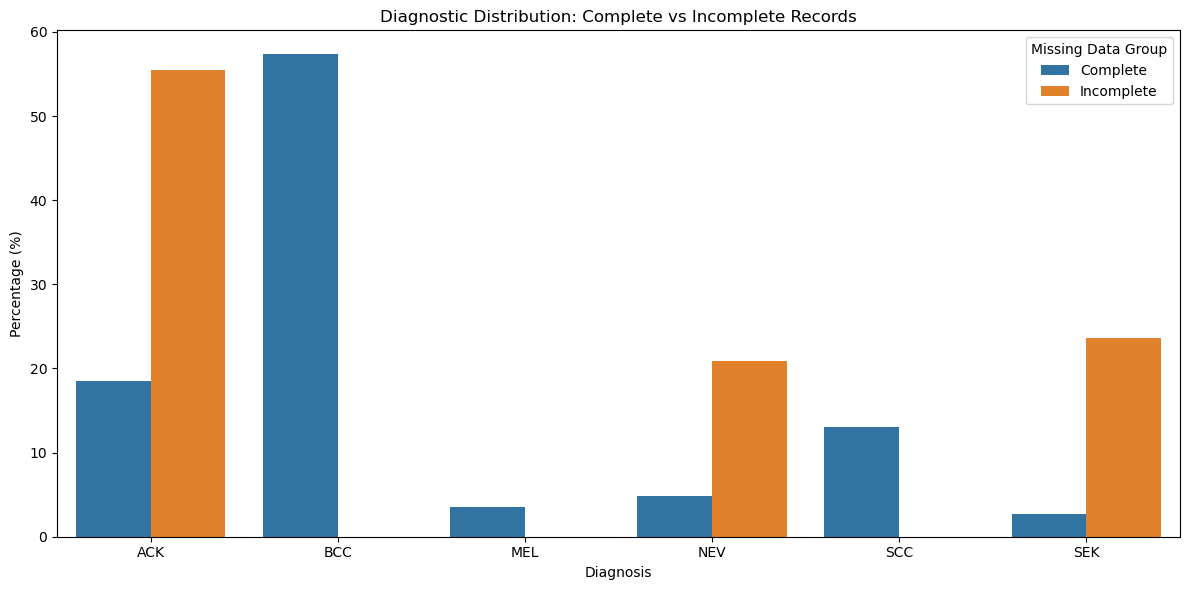

In [134]:
# 76. DIAGNOSTIC DISTRIBUTION BY MISSING GROUP

# Calculate diagnostic percentages
diagnostic_percentages = pd.crosstab(
    df["missing_group"],
    df["diagnostic"],
    normalize="index"
) * 100

# Convert the table into a format suitable for plotting
diagnostic_percentages = diagnostic_percentages.reset_index().melt(
    id_vars="missing_group",
    var_name="diagnostic",
    value_name="percentage"
)

# Create grouped bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=diagnostic_percentages,
    x="diagnostic",
    y="percentage",
    hue="missing_group"
)

plt.title("Diagnostic Distribution: Complete vs Incomplete Records")
plt.xlabel("Diagnosis")
plt.ylabel("Percentage (%)")
plt.legend(title="Missing Data Group")
plt.tight_layout()
plt.show()

# Missing Data and Diagnostic Distribution

The diagnostic distribution differs considerably between complete and incomplete records.

Complete records contain all six diagnostic categories, whereas incomplete records contain only ACK, NEV and SEK.

The incomplete group consists of:
- ACK: 55.46%
- NEV: 20.87%
- SEK: 23.67%

BCC, MEL and SCC are absent from the incomplete group.

Removing all incomplete records could therefore introduce selection bias and alter the diagnostic distribution.

Missing-value handling will require careful consideration to preserve the representation of diagnostic classes.

In [136]:
# 77. Compare diagnostic counts
pd.crosstab(
    df["missing_group"],
    df["diagnostic"]
)

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
missing_group,,,,,,
Complete,273,845,52,72,192,40
Incomplete,457,0,0,172,0,195


# Diagnostic Distribution Across Missing-Data Groups

The diagnostic counts revealed substantial differences between complete and incomplete records.

- All 845 BCC, 52 MEL and 192 SCC records belong to the complete group.
- ACK has 273 complete and 457 incomplete records.
- NEV has 72 complete and 172 incomplete records.
- SEK has 40 complete and 195 incomplete records.

The incomplete group contains 824 records in total, including 804 records with 13 missing values and 20 records with either 1 or 2 missing values.

Removing all incomplete records could substantially alter the diagnostic distribution and introduce selection bias.

In [138]:
# 78. Select records with exactly 13 missing values
group_804 = df[missing_per_row == 13]

# Compare their diagnostic counts
group_804["diagnostic"].value_counts()

diagnostic
ACK    447
SEK    188
NEV    169
Name: count, dtype: int64

# Analysis of Records with 13 Missing Values

The 804 records containing exactly 13 missing values were examined separately.

Their diagnostic distribution was:

- ACK: 447 records (55.60%)
- SEK: 188 records (23.38%)
- NEV: 169 records (21.02%)

BCC, MEL and SCC were absent from this group.

This demonstrates an association between the observed missing-data pattern and the diagnostic category. The reason for this association cannot be established from the distribution alone.

### Duplicate Records

In [140]:
# 79. DUPLICATE ANALYSIS

# Count completely duplicated rows
df.duplicated().sum()

# Count completely duplicated rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [141]:
# 80. Count records associated with each patient
df["patient_id"].value_counts()

patient_id
PAT_645     10
PAT_388     10
PAT_330     10
PAT_53       7
PAT_270      7
            ..
PAT_403      1
PAT_1130     1
PAT_841      1
PAT_1020     1
PAT_1714     1
Name: count, Length: 1373, dtype: int64

In [142]:
# 81. Count unique lesion IDs
print("Unique lesions:", df["lesion_id"].nunique())

# Count duplicated lesion IDs
print("Duplicate lesion IDs:", df["lesion_id"].duplicated().sum())

Unique lesions: 1641
Duplicate lesion IDs: 657


In [143]:
# 82. Count occurrences of each lesion ID
lesion_counts = df["lesion_id"].value_counts()

# Display lesion IDs that appear more than once
lesion_counts[lesion_counts > 1]

lesion_id
1246    8
361     6
1402    5
1286    5
1156    4
       ..
3335    2
659     2
738     2
1387    2
824     2
Name: count, Length: 512, dtype: int64

In [144]:
# 83. Inspect records belonging to one repeated lesion
df[df["lesion_id"] == 1246][
    ["patient_id", "lesion_id", "img_id", "diagnostic"]
]

,patient_id,lesion_id,img_id,diagnostic
312,PAT_1364,1246,PAT_1364_1246_420.png,NEV
409,PAT_1364,1246,PAT_1364_1246_927.png,NEV
567,PAT_1364,1246,PAT_1364_1246_447.png,NEV
1091,PAT_1364,1246,PAT_1364_1246_143.png,NEV
1356,PAT_1364,1246,PAT_1364_1246_583.png,NEV
1461,PAT_656,1246,PAT_656_1246_483.png,MEL
1873,PAT_1364,1246,PAT_1364_1246_238.png,NEV
1916,PAT_656,1246,PAT_656_1246_489.png,MEL


In [145]:
# 84. Check duplicates using patient_id and lesion_id together
print(
    "Duplicate patient-lesion combinations:",
    df.duplicated(subset=["patient_id", "lesion_id"]).sum()
)

Duplicate patient-lesion combinations: 407


In [146]:
# 85. Examine one patient-lesion combination
df[
    (df["patient_id"] == "PAT_1364") &
    (df["lesion_id"] == 1246)
][["patient_id", "lesion_id", "img_id", "diagnostic"]]

,patient_id,lesion_id,img_id,diagnostic
312,PAT_1364,1246,PAT_1364_1246_420.png,NEV
409,PAT_1364,1246,PAT_1364_1246_927.png,NEV
567,PAT_1364,1246,PAT_1364_1246_447.png,NEV
1091,PAT_1364,1246,PAT_1364_1246_143.png,NEV
1356,PAT_1364,1246,PAT_1364_1246_583.png,NEV
1873,PAT_1364,1246,PAT_1364_1246_238.png,NEV


In [147]:
# 86. Compare clinical information for the repeated lesion
df[
    (df["patient_id"] == "PAT_1364") &
    (df["lesion_id"] == 1246)
].drop(columns=["img_id"]).T

,312,409,567,1091,1356,1873
patient_id,PAT_1364,PAT_1364,PAT_1364,PAT_1364,PAT_1364,PAT_1364
lesion_id,1246,1246,1246,1246,1246,1246
smoke,NaN,NaN,NaN,NaN,NaN,NaN
drink,NaN,NaN,NaN,NaN,NaN,NaN
background_father,NaN,NaN,NaN,NaN,NaN,NaN
background_mother,NaN,NaN,NaN,NaN,NaN,NaN
age,17,17,17,17,17,17
pesticide,NaN,NaN,NaN,NaN,NaN,NaN
gender,NaN,NaN,NaN,NaN,NaN,NaN
skin_cancer_history,NaN,NaN,NaN,NaN,NaN,NaN


# Repeated Patient-Lesion Records

The dataset contains repeated combinations of patient_id and lesion_id.

An investigation of patient PAT_1364 and lesion 1246 identified six records with identical clinical information but different image identifiers.

This suggests that multiple images may be associated with the same underlying lesion.

Since this project focuses exclusively on tabular data, repeated clinical records may lead to overrepresentation of certain lesions.

Further investigation is required to determine whether these records should be consolidated or retained. Patient-level grouping will also be considered during model evaluation to prevent data leakage.

In [149]:
# 87. Count unique patient-lesion combinations
print(
    "Unique patient-lesion combinations:",
    df[["patient_id", "lesion_id"]].drop_duplicates().shape[0]
)

Unique patient-lesion combinations: 1891


In [150]:
# 88. Count records per patient-lesion combination
combination_counts = df.groupby(
    ["patient_id", "lesion_id"]
).size()

# Count combinations appearing more than once
print(
    "Repeated patient-lesion combinations:",
    (combination_counts > 1).sum()
)

# Show the distribution of occurrences
print(combination_counts.value_counts().sort_index())

Repeated patient-lesion combinations: 361
1    1530
2     324
3      31
4       4
5       1
6       1
Name: count, dtype: int64


# There are 361 patient-lesion combinations that appear more than once.

Let's distinguish two things:
- 361 = number of repeated patient-lesion combinations.
- 407 = number of additional rows caused by those repetitions.
For example, a combination appearing twice contributes one additional row; a combination appearing six times contributes five additional rows.

This explains why we found 407 duplicate patient-lesion combinations at the row level.

### Clinical Consistency

In [152]:
# 89. Select clinical columns, excluding identifiers
clinical_columns = df.columns.drop(
    ["patient_id", "lesion_id", "img_id", "missing_group"]
)

# Count distinct values within each patient-lesion combination
clinical_variations = df.groupby(
    ["patient_id", "lesion_id"]
)[clinical_columns].nunique(dropna=False)

# Find combinations with differences in clinical information
inconsistent = clinical_variations[
    (clinical_variations > 1).any(axis=1)
]

print("Inconsistent patient-lesion combinations:", len(inconsistent))

Inconsistent patient-lesion combinations: 0


# Repeated Records and Consistency Analysis

The dataset contains 361 patient-lesion combinations that appear more than once, accounting for 407 additional records.

An investigation of these combinations found no inconsistencies in their clinical information. Repeated records contain identical clinical attributes, although their image identifiers may differ.

This suggests that multiple images are associated with the same patient-lesion combination.

These records are not completely duplicated rows. However, retaining every repeated record could give certain lesions greater representation during model training.

The appropriate treatment of repeated records will be considered during preprocessing.

In [154]:
# 90. Count unique lesions for each patient
lesions_per_patient = df.groupby("patient_id")["lesion_id"].nunique()

# Display summary statistics
lesions_per_patient.describe()

count    1373.000000
mean        1.377276
std         0.764830
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         8.000000
Name: lesion_id, dtype: float64

# Lesions per Patient

The dataset contains 1,373 unique patients, with an average of approximately 1.38 unique lesions per patient.

The median number of lesions per patient is 1, while the maximum is 8.

This indicates that some patients have multiple lesions recorded in the dataset.

Patient identifiers will therefore be important when splitting the data into training and testing sets, to reduce the risk of data leakage.

# Stage 4 - Data Preprocessing

In [156]:
# 91. REVIEW DATASET COLUMNS

# Display all dataset column names
df.columns.tolist()

['patient_id',
 'lesion_id',
 'smoke',
 'drink',
 'background_father',
 'background_mother',
 'age',
 'pesticide',
 'gender',
 'skin_cancer_history',
 'cancer_history',
 'has_piped_water',
 'has_sewage_system',
 'fitspatrick',
 'region',
 'diameter_1',
 'diameter_2',
 'diagnostic',
 'itch',
 'grew',
 'hurt',
 'changed',
 'bleed',
 'elevation',
 'img_id',
 'biopsed',
 'missing_group']

In [157]:
# 92. IDENTIFY IDENTIFIER AND HELPER COLUMNS

# Columns excluded from predictive features
excluded_columns = [
    "patient_id",
    "lesion_id",
    "img_id",
    "missing_group"
]

# Target variable
target_column = "diagnostic"

print("Excluded columns:", excluded_columns)
print("Target variable:", target_column)

Excluded columns: ['patient_id', 'lesion_id', 'img_id', 'missing_group']
Target variable: diagnostic


In [158]:
# 93. INVESTIGATE BIOPSY STATUS

# Count biopsy status for each diagnosis
pd.crosstab(df["diagnostic"], df["biopsed"])

biopsed,False,True
diagnostic,,
ACK,552,178
BCC,0,845
MEL,0,52
NEV,184,60
SCC,0,192
SEK,220,15


# Investigation of Biopsy Status

Biopsy status was examined in relation to the diagnostic categories.

BCC, MEL and SCC records all had a biopsy status of True, while ACK and SEK had a higher proportion of False values.

This indicates a strong association between biopsy status and diagnosis.

Since biopsy status may reflect information obtained during the diagnostic process, including it as a predictive feature could introduce target leakage.

Therefore, biopsed will be excluded from the initial predictive feature set.

### Feature Selection

In [160]:
# 94. INITIAL FEATURE SELECTION

# Exclude identifiers, helper columns, target and biopsy status
excluded_columns = [
    "patient_id",
    "lesion_id",
    "img_id",
    "missing_group",
    "diagnostic",
    "biopsed"
]

# Select remaining candidate features
candidate_features = df.drop(columns=excluded_columns).columns.tolist()

print("Number of candidate features:", len(candidate_features))
print(candidate_features)

Number of candidate features: 21
['smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']


In [161]:
# 95. MISSING VALUE ANALYSIS

# Calculate missing values for candidate features
missing_summary = pd.DataFrame({
    "Missing Values": df[candidate_features].isnull().sum(),
    "Missing Percentage": df[candidate_features].isnull().mean() * 100
})

# Display columns with missing values
missing_summary[missing_summary["Missing Values"] > 0]

,Missing Values,Missing Percentage
smoke,804,34.986945
drink,804,34.986945
background_father,818,35.596171
background_mother,822,35.770235
pesticide,804,34.986945
gender,804,34.986945
skin_cancer_history,804,34.986945
cancer_history,804,34.986945
has_piped_water,804,34.986945
has_sewage_system,804,34.986945


In [162]:
# 96. IDENTIFY MISSING NUMERICAL FEATURES

# Select numerical candidate features
numerical_features = df[candidate_features].select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical features:", numerical_features)

# Display missing values in numerical features
df[numerical_features].isnull().sum()

Numerical features: ['age', 'fitspatrick', 'diameter_1', 'diameter_2']


age              0
fitspatrick    804
diameter_1     804
diameter_2     804
dtype: int64

In [163]:
# 97. IDENTIFY MISSING CATEGORICAL FEATURES

# Select categorical candidate features
categorical_features = df[candidate_features].select_dtypes(
    include=["object", "bool"]
).columns.tolist()

print("Categorical features:", categorical_features)

# Display missing values in categorical features
df[categorical_features].isnull().sum()

Categorical features: ['smoke', 'drink', 'background_father', 'background_mother', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'region', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']


smoke                  804
drink                  804
background_father      818
background_mother      822
pesticide              804
gender                 804
skin_cancer_history    804
cancer_history         804
has_piped_water        804
has_sewage_system      804
region                   0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                    0
elevation                0
dtype: int64

### Missing Values by Diagnosis

In [164]:
# 98. MISSING VALUES BY DIAGNOSIS

# Calculate the percentage of missing values
# in each diagnostic category
missing_by_diagnosis = df.groupby("diagnostic")[
    candidate_features
].apply(lambda group: group.isnull().mean() * 100)

missing_by_diagnosis.round(2)

,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,cancer_history,has_piped_water,...,fitspatrick,region,diameter_1,diameter_2,itch,grew,hurt,changed,bleed,elevation
diagnostic,,,,,,,,,,,,,,,,,,,,,
ACK,61.23,61.23,61.92,62.33,0.0,61.23,61.23,61.23,61.23,61.23,...,61.23,0.0,61.23,61.23,0.0,0.0,0.0,0.0,0.0,0.0
BCC,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,...,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0
MEL,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,...,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0
NEV,69.26,69.26,70.08,70.49,0.0,69.26,69.26,69.26,69.26,69.26,...,69.26,0.0,69.26,69.26,0.0,0.0,0.0,0.0,0.0,0.0
SCC,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,...,0.00,0.0,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0
SEK,80.00,80.00,82.98,82.98,0.0,80.00,80.00,80.00,80.00,80.00,...,80.00,0.0,80.00,80.00,0.0,0.0,0.0,0.0,0.0,0.0


In [165]:
# 99. VERIFY STRUCTURED MISSINGNESS

# Count records by missingness group and diagnosis
pd.crosstab(df["missing_group"], df["diagnostic"])

diagnostic,ACK,BCC,MEL,NEV,SCC,SEK
missing_group,,,,,,
Complete,273,845,52,72,192,40
Incomplete,457,0,0,172,0,195


# Missing Value Investigation and Findings

The dataset contains 824 incomplete records out of 2,298.

A structured missingness pattern was identified:
- 804 records have the same 13 missing features.
- The remaining 20 incomplete records have one or two missing values.

Missingness is concentrated in ACK, NEV and SEK diagnostic categories. BCC, MEL and SCC have no incomplete records in the investigated features.

Removing all incomplete records would disproportionately reduce the representation of ACK, NEV and SEK.

Therefore, all records will initially be retained. Appropriate imputation strategies will be investigated and evaluated during preprocessing.

### Consolidating Repeated Records

In [167]:
# 100. IDENTIFY UNIQUE PATIENT-LESION RECORDS

# Keep one record per patient-lesion combination
df_unique = df.drop_duplicates(
    subset=["patient_id", "lesion_id"]
)

# Compare dataset sizes
print("Original dataset:", df.shape)
print("Unique lesion dataset:", df_unique.shape)

Original dataset: (2298, 27)
Unique lesion dataset: (1891, 27)


In [168]:
# 101. CHECK THE UNIQUE LESION DATASET

# Check the first five rows
df_unique.head()

# Check the dataset dimensions
df_unique.shape

(1891, 27)

In [169]:
# 102. CHECK MISSING VALUES

# Count missing values in each column
df_unique.isnull().sum()

patient_id               0
lesion_id                0
smoke                  712
drink                  712
background_father      722
background_mother      726
age                      0
pesticide              712
gender                 712
skin_cancer_history    712
cancer_history         712
has_piped_water        712
has_sewage_system      712
fitspatrick            712
region                   0
diameter_1             712
diameter_2             712
diagnostic               0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                    0
elevation                0
img_id                   0
biopsed                  0
missing_group            0
dtype: int64

In [170]:
# 103. CHECK MISSING VALUES PER ROW

# Count missing values in each row
missing_per_row = df_unique.isnull().sum(axis=1)

# Count how many rows have each missing-value total
missing_per_row.value_counts().sort_index()

0     1163
1        8
2        8
13     712
Name: count, dtype: int64

In [171]:
# 104. MISSING VALUES BY DIAGNOSIS

# Identify records with 13 missing values
rows_with_13_missing = df_unique[missing_per_row == 13]

# Count diagnostic categories
rows_with_13_missing["diagnostic"].value_counts()

diagnostic
ACK    396
SEK    163
NEV    153
Name: count, dtype: int64

In [172]:
# 105. IDENTIFY COLUMNS WITH MISSING VALUES

# Count missing values in the affected records
rows_with_13_missing.isnull().sum()

patient_id               0
lesion_id                0
smoke                  712
drink                  712
background_father      712
background_mother      712
age                      0
pesticide              712
gender                 712
skin_cancer_history    712
cancer_history         712
has_piped_water        712
has_sewage_system      712
fitspatrick            712
region                   0
diameter_1             712
diameter_2             712
diagnostic               0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                    0
elevation                0
img_id                   0
biopsed                  0
missing_group            0
dtype: int64

### Create Preprocessing DataFrame

In [173]:
# 106. CREATE PREPROCESSING DATAFRAME

# Create a copy of the unique dataset
df_preprocessed = df_unique.copy()

# Check its dimensions
df_preprocessed.shape

(1891, 27)

In [174]:
# 107. IDENTIFY CONTINUOUS NUMERICAL FEATURES

# Continuous numerical variables
numerical_features = [
    "age",
    "diameter_1",
    "diameter_2"
]

# Check their data types
df_preprocessed[numerical_features].dtypes

age             int64
diameter_1    float64
diameter_2    float64
dtype: object

## Patient-level Train/Test Split

In [175]:
# 108. SEPARATE FEATURES AND TARGET

# Independent variables (features)
X = df_preprocessed[candidate_features]

# Dependent variable (target)
y = df_preprocessed["diagnostic"]

# Patient identifiers for group-based splitting
groups = df_preprocessed["patient_id"]

# Why Patient-Level Train/Test Splitting?

The dataset contains multiple skin lesions belonging to some patients. If we randomly split the records, lesions from the same patient could appear in both the training and testing datasets.

This could lead to **data leakage**, because the model may learn patient-specific patterns during training and encounter the same patient again during testing.

To avoid this, we use patient-level splitting, ensuring that all records belonging to one patient are assigned to either the training set or the testing set, never both.

This allows us to evaluate whether the model can generalise to previously unseen patients, providing a more reliable assessment of its performance.

### Configure The Split 

In [177]:
# 109. CONFIGURE TRAIN-TEST SPLIT

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [178]:
# 110. GENERATE TRAIN-TEST INDICES

train_idx, test_idx = next(
    splitter.split(X, y, groups)
)

### Create The Training and Testing Datasets

In [179]:
# 111. CREATE TRAINING AND TESTING DATASETS

# Training features and target
X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

# Testing features and target
X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

In [180]:
# 112. CHECK TRAIN-TEST SPLIT

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1510, 21)
Testing features: (381, 21)
Training target: (1510,)
Testing target: (381,)


In [181]:
# 113. VERIFY PATIENT-LEVEL SPLIT

# Get unique patient IDs in each dataset
train_patients = groups.iloc[train_idx]
test_patients = groups.iloc[test_idx]

# Find patients appearing in both datasets
overlapping_patients = set(train_patients) & set(test_patients)

print("Overlapping patients:", len(overlapping_patients))

Overlapping patients: 0


# 2.25 Feature Grouping

Before handling missing values, we need to separate our features according to their data types.

We will use three groups:

1. **Continuous numerical features:** Variables representing measurable quantities, such as age and lesion diameter.
2. **Ordinal categorical features:** Variables with categories that have a natural order, such as the Fitzpatrick skin type scale.
3. **Other categorical features:** Variables representing labels or groups, such as gender, region and smoking status.

This separation is important because different feature types require different preprocessing techniques.

### Identify Feature Groups

In [183]:
# 114. IDENTIFY FEATURE GROUPS

# Continuous numerical features
numerical_features = [
    "age",
    "diameter_1",
    "diameter_2"
]

# Ordinal categorical features
ordinal_features = ["fitspatrick"]

# Other categorical features
categorical_features = X_train.select_dtypes(
    include=["object", "bool"]
).columns.tolist()

# Display feature groups
print("Numerical features:", numerical_features)
print("Ordinal features:", ordinal_features)
print("Categorical features:", categorical_features)

Numerical features: ['age', 'diameter_1', 'diameter_2']
Ordinal features: ['fitspatrick']
Categorical features: ['smoke', 'drink', 'background_father', 'background_mother', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'region', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation']


### Configure Numerical Imputation

In [184]:
# 115. CONFIGURE NUMERICAL IMPUTATION

# Create a median imputer
numerical_imputer = SimpleImputer(strategy="median")

In [185]:
# 116. FIT NUMERICAL IMPUTER

# Learn the median values from training data
numerical_imputer.fit(X_train[numerical_features])

,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False


In [186]:
# 117. VIEW LEARNED MEDIAN VALUES

# Display the median calculated for each feature
for feature, median in zip(
    numerical_features,
    numerical_imputer.statistics_
):
    print(feature, ":", median)

age : 62.0
diameter_1 : 10.0
diameter_2 : 7.0


In [187]:
# 118. APPLY NUMERICAL IMPUTATION

# Transform training numerical features
X_train[numerical_features] = numerical_imputer.transform(
    X_train[numerical_features]
)

# Transform testing numerical features
X_test[numerical_features] = numerical_imputer.transform(
    X_test[numerical_features]
)

C:\Users\97152\AppData\Local\Temp\ipykernel_34328\1782486304.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train[numerical_features] = numerical_imputer.transform(
C:\Users\97152\AppData\Local\Temp\ipykernel_34328\1782486304.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_test[numerical_features] = numerical_imputer.transform(


In [188]:
# 119. CREATE INDEPENDENT DATASET COPIES

# Create independent copies of training and testing data
X_train = X_train.copy()
X_test = X_test.copy()

In [189]:
# 120. APPLY NUMERICAL IMPUTATION

# Transform training numerical features
X_train.loc[:, numerical_features] = numerical_imputer.transform(
    X_train[numerical_features]
)

# Transform testing numerical features
X_test.loc[:, numerical_features] = numerical_imputer.transform(
    X_test[numerical_features]
)

In [190]:
# 121. VERIFY NUMERICAL IMPUTATION

# Check missing values in training data
print("Training data:")
print(X_train[numerical_features].isnull().sum())

# Check missing values in testing data
print("\nTesting data:")
print(X_test[numerical_features].isnull().sum())

Training data:
age           0
diameter_1    0
diameter_2    0
dtype: int64

Testing data:
age           0
diameter_1    0
diameter_2    0
dtype: int64


In [191]:
# 122. INSPECT ORDINAL FEATURE

# Display the frequency of each Fitzpatrick skin type
print(X_train["fitspatrick"].value_counts(dropna=False).sort_index())

fitspatrick
1.0    101
2.0    560
3.0    249
4.0     33
5.0      9
NaN    558
Name: count, dtype: int64


# Handling Missing Values in Ordinal Features

The `fitspatrick` feature represents the Fitzpatrick skin type, which classifies skin into ordered categories (Type I to Type VI).

Unlike nominal categorical features, ordinal features have a meaningful order. Therefore, we need to preserve this ordering during preprocessing.

**Observations:**
- Type II is the most frequent category (560 records).
- Type V is the least frequent category (9 records).
- 558 values are missing in the training dataset.

**Imputation strategy: Median**

We will use median imputation to replace missing values in `fitspatrick`.

The median is suitable for ordinal data because it considers the natural ordering of the categories and is less affected by extreme values than the mean.

The imputer will be fitted on the training data only. The same learned median will then be applied to both training and testing data to prevent data leakage.
We will retain the original feature and its ordinal meaning.

### Configure Ordinal Imputation

In [193]:
# 123. CONFIGURE ORDINAL IMPUTATION

# Create an imputer using the median strategy
ordinal_imputer = SimpleImputer(strategy="median")

In [194]:
# 124. FIT ORDINAL IMPUTER

# Learn the median Fitzpatrick value from training data
ordinal_imputer.fit(X_train[ordinal_features])

,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False


In [195]:
# 125. DISPLAY LEARNED ORDINAL MEDIAN

# Display the median Fitzpatrick value learned from training data
print("Fitzpatrick median:", ordinal_imputer.statistics_[0])

Fitzpatrick median: 2.0


In [196]:
# 126. APPLY ORDINAL IMPUTATION

# Impute missing ordinal values in training data
X_train.loc[:, ordinal_features] = ordinal_imputer.transform(
    X_train[ordinal_features]
)

# Impute missing ordinal values in testing data
X_test.loc[:, ordinal_features] = ordinal_imputer.transform(
    X_test[ordinal_features]
)

In [197]:
# 127. VERIFY ORDINAL IMPUTATION

# Check missing values in training data
print("Training data:")
print(X_train[ordinal_features].isnull().sum())

# Check missing values in testing data
print("\nTesting data:")
print(X_test[ordinal_features].isnull().sum())

Training data:
fitspatrick    0
dtype: int64

Testing data:
fitspatrick    0
dtype: int64


# Ordinal Feature Imputation – Summary

The `fitspatrick` feature was treated as an ordinal variable because its categories represent an ordered scale of skin types.

The training data contained 558 missing values in this feature. Median imputation was selected to preserve the numerical ordering of the categories.

The median was calculated using the training data only and was found to be 2.0 (Fitzpatrick Type II).

The same median was applied to both training and testing datasets to prevent data leakage.

**Verification:** After imputation, no missing values remained in the `fitspatrick` feature in either dataset.

### Inspect Missing Categorical Values

In [199]:
# 128. INSPECT MISSING CATEGORICAL VALUES

# Count missing values in categorical features
print(X_train[categorical_features].isnull().sum())

smoke                  558
drink                  558
background_father      565
background_mother      570
pesticide              558
gender                 558
skin_cancer_history    558
cancer_history         558
has_piped_water        558
has_sewage_system      558
region                   0
itch                     0
grew                     0
hurt                     0
changed                  0
bleed                    0
elevation                0
dtype: int64


# Handling Missing Values in Nominal and Binary Categorical Features

The categorical features were inspected to identify missing values.

Out of the 17 categorical features, 10 contained missing values, while the remaining 7 had complete data.

The missing values were concentrated in the following features:

- Personal and medical information: `smoke`, `drink`, `pesticide`, `gender`, `skin_cancer_history`, `cancer_history`
- Family background: `background_father`, `background_mother`
- Living conditions: `has_piped_water`, `has_sewage_system`

**Imputation strategy: Constant imputation**

Missing values will be replaced with a separate category labelled `"Missing"`.

This approach preserves the distinction between an observed category and unavailable information. It also avoids assuming that missing observations belong to the most frequent category.

The imputer will be fitted on the training data and applied to both training and testing datasets.

The seven categorical features without missing values will remain unchanged.

### Configure Categorical Imputation

In [201]:
# 129. CONFIGURE CATEGORICAL IMPUTATION

# Create an imputer that replaces missing values with "Missing"
categorical_imputer = SimpleImputer(
    strategy="constant",
    fill_value="Missing"
)

In [202]:
# 130. FIT CATEGORICAL IMPUTER

# Learn the categorical features from training data
categorical_imputer.fit(X_train[categorical_features])

,missing_values,nan
,strategy,'constant'
,fill_value,'Missing'
,copy,True
,add_indicator,False
,keep_empty_features,False


In [203]:
# 131. APPLY CATEGORICAL IMPUTATION

# Impute missing categorical values in training data
X_train.loc[:, categorical_features] = categorical_imputer.transform(
    X_train[categorical_features]
)

# Impute missing categorical values in testing data
X_test.loc[:, categorical_features] = categorical_imputer.transform(
    X_test[categorical_features]
)

In [204]:
# 132. VERIFY CATEGORICAL IMPUTATION

# Check missing values in training data
print("Training data:")
print(X_train[categorical_features].isnull().sum())

# Check missing values in testing data
print("\nTesting data:")
print(X_test[categorical_features].isnull().sum())

Training data:
smoke                  0
drink                  0
background_father      0
background_mother      0
pesticide              0
gender                 0
skin_cancer_history    0
cancer_history         0
has_piped_water        0
has_sewage_system      0
region                 0
itch                   0
grew                   0
hurt                   0
changed                0
bleed                  0
elevation              0
dtype: int64

Testing data:
smoke                  0
drink                  0
background_father      0
background_mother      0
pesticide              0
gender                 0
skin_cancer_history    0
cancer_history         0
has_piped_water        0
has_sewage_system      0
region                 0
itch                   0
grew                   0
hurt                   0
changed                0
bleed                  0
elevation              0
dtype: int64


In [205]:
# 133. FINAL MISSING-VALUE CHECK

# Check missing values across all training features
print("Training data:")
print(X_train.isnull().sum().sum())

# Check missing values across all testing features
print("\nTesting data:")
print(X_test.isnull().sum().sum())

Training data:
0

Testing data:
0


# Summary of Missing-Value Imputation

Missing values were handled separately according to feature type.

| Feature type | Imputation strategy |
|---|---|
| Numerical | Median imputation |
| Ordinal | Median imputation |
| Nominal and binary categorical | Constant imputation using `"Missing"` |

The imputers were fitted using the training dataset only. The learned imputation strategy was then applied to both training and testing datasets to prevent data leakage.

**Verification:** The final missing-value check confirmed that both datasets contain zero missing values across all 21 features.

All original feature columns have been retained.

## Categorical Encoding

In [207]:
# 134. CONFIGURE ONE-HOT ENCODER

# Create the One-Hot Encoder
categorical_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# 135. FIT CATEGORICAL ENCODER

Learn the categories from the training data
categorical_encoder.fit(X_train[categorical_features])

In [210]:
# 136. CONVERT CATEGORICAL FEATURES TO STRINGS

# Convert categorical feature values to strings
X_train[categorical_features] = X_train[categorical_features].astype(str)

X_test[categorical_features] = X_test[categorical_features].astype(str)

In [211]:
# 137. FIT CATEGORICAL ENCODER

# Learn the categories from the training data
categorical_encoder.fit(X_train[categorical_features])

,categories,'auto'
,drop,None
,sparse_output,False
,dtype,<class 'numpy.float64'>
,handle_unknown,'ignore'
,min_frequency,None
,max_categories,None
,feature_name_combiner,'concat'


In [212]:
# 138. INSPECT LEARNED CATEGORIES

# Display the categories learned for each feature
for feature, categories in zip(
    categorical_features,
    categorical_encoder.categories_
):
    print(feature, ":", categories)

smoke : ['False' 'Missing' 'True']
drink : ['False' 'Missing' 'True']
background_father : ['BRASIL' 'BRAZIL' 'CZECH' 'GERMANY' 'ISRAEL' 'ITALY' 'Missing'
 'NETHERLANDS' 'POLAND' 'POMERANIA' 'PORTUGAL' 'UNK']
background_mother : ['BRAZIL' 'FRANCE' 'GERMANY' 'ITALY' 'Missing' 'NETHERLANDS' 'NORWAY'
 'POLAND' 'POMERANIA' 'PORTUGAL' 'SPAIN' 'UNK']
pesticide : ['False' 'Missing' 'True']
gender : ['FEMALE' 'MALE' 'Missing']
skin_cancer_history : ['False' 'Missing' 'True']
cancer_history : ['False' 'Missing' 'True']
has_piped_water : ['False' 'Missing' 'True']
has_sewage_system : ['False' 'Missing' 'True']
region : ['ABDOMEN' 'ARM' 'BACK' 'CHEST' 'EAR' 'FACE' 'FOOT' 'FOREARM' 'HAND' 'LIP'
 'NECK' 'NOSE' 'SCALP' 'THIGH']
itch : ['FALSE' 'TRUE' 'UNK']
grew : ['FALSE' 'TRUE' 'UNK']
hurt : ['FALSE' 'TRUE' 'UNK']
changed : ['FALSE' 'TRUE' 'UNK']
bleed : ['FALSE' 'TRUE' 'UNK']
elevation : ['FALSE' 'TRUE' 'UNK']


In [213]:
# 139. COUNT ENCODED COLUMNS

# Count the number of categories in each feature
for feature, categories in zip(
    categorical_features,
    categorical_encoder.categories_
):
    print(feature, ":", len(categories))

# Calculate the total number of encoded columns
total_encoded_columns = sum(
    len(categories) for categories in categorical_encoder.categories_
)

print("\nTotal encoded columns:", total_encoded_columns)

smoke : 3
drink : 3
background_father : 12
background_mother : 12
pesticide : 3
gender : 3
skin_cancer_history : 3
cancer_history : 3
has_piped_water : 3
has_sewage_system : 3
region : 14
itch : 3
grew : 3
hurt : 3
changed : 3
bleed : 3
elevation : 3

Total encoded columns: 80


In [214]:
# 140. APPLY ONE-HOT ENCODING

# Transform categorical features in training data
X_train_encoded = categorical_encoder.transform(
    X_train[categorical_features]
)

# Transform categorical features in testing data
X_test_encoded = categorical_encoder.transform(
    X_test[categorical_features]
)

In [215]:
# 141. CHECK ENCODED DATA DIMENSIONS

# Display the shape of encoded training and testing data
print("Training encoded data:", X_train_encoded.shape)
print("Testing encoded data:", X_test_encoded.shape)

Training encoded data: (1510, 80)
Testing encoded data: (381, 80)


In [216]:
# 142. GET ENCODED COLUMN NAMES

# Retrieve the names of the newly created encoded columns
encoded_feature_names = categorical_encoder.get_feature_names_out(
    categorical_features
)

# Display the encoded column names
print(encoded_feature_names)

['smoke_False' 'smoke_Missing' 'smoke_True' 'drink_False' 'drink_Missing'
 'drink_True' 'background_father_BRASIL' 'background_father_BRAZIL'
 'background_father_CZECH' 'background_father_GERMANY'
 'background_father_ISRAEL' 'background_father_ITALY'
 'background_father_Missing' 'background_father_NETHERLANDS'
 'background_father_POLAND' 'background_father_POMERANIA'
 'background_father_PORTUGAL' 'background_father_UNK'
 'background_mother_BRAZIL' 'background_mother_FRANCE'
 'background_mother_GERMANY' 'background_mother_ITALY'
 'background_mother_Missing' 'background_mother_NETHERLANDS'
 'background_mother_NORWAY' 'background_mother_POLAND'
 'background_mother_POMERANIA' 'background_mother_PORTUGAL'
 'background_mother_SPAIN' 'background_mother_UNK' 'pesticide_False'
 'pesticide_Missing' 'pesticide_True' 'gender_FEMALE' 'gender_MALE'
 'gender_Missing' 'skin_cancer_history_False'
 'skin_cancer_history_Missing' 'skin_cancer_history_True'
 'cancer_history_False' 'cancer_history_Missing' 

In [217]:
# 143. CONVERT ENCODED ARRAYS INTO DATAFRAMES

# Convert training encoded array into a DataFrame
X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns=encoded_feature_names,
    index=X_train.index
)

# Convert testing encoded array into a DataFrame
X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns=encoded_feature_names,
    index=X_test.index
)

In [218]:
# 144. COMBINE PREPROCESSED FEATURES

# Combine numerical, ordinal and encoded categorical features
X_train_processed = pd.concat(
    [
        X_train[numerical_features + ordinal_features],
        X_train_encoded
    ],
    axis=1
)

# Combine numerical, ordinal and encoded categorical features
X_test_processed = pd.concat(
    [
        X_test[numerical_features + ordinal_features],
        X_test_encoded
    ],
    axis=1
)

In [219]:
# 145. CHECK PROCESSED DATASET DIMENSIONS

# Display training and testing dataset dimensions
print("Training data:", X_train_processed.shape)
print("Testing data:", X_test_processed.shape)

Training data: (1510, 84)
Testing data: (381, 84)


In [220]:
# 146. INSPECT PROCESSED DATASET

# Display the first five rows of training data
X_train_processed.head()

,age,diameter_1,diameter_2,fitspatrick,smoke_False,smoke_Missing,smoke_True,drink_False,drink_Missing,drink_True,...,hurt_UNK,changed_FALSE,changed_TRUE,changed_UNK,bleed_FALSE,bleed_TRUE,bleed_UNK,elevation_FALSE,elevation_TRUE,elevation_UNK
0,8.0,10.0,7.0,2.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,75.0,10.0,7.0,2.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,79.0,5.0,5.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
5,53.0,10.0,7.0,2.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
6,52.0,15.0,10.0,3.0,1.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


# Categorical Encoding – Summary

Categorical encoding was performed to convert non-numerical features into a format suitable for machine-learning algorithms.

**1. One-Hot Encoding**

The 17 nominal and binary categorical features were converted using Scikit-learn's `OneHotEncoder`.

The encoder was configured with:
- `handle_unknown="ignore"` to handle previously unseen categories.
- `sparse_output=False` to produce a dense numerical array.

**2. Handling mixed data types**

An error occurred because some categorical features contained a mixture of Boolean and string values.

To resolve this, all categorical features in the training and testing datasets were converted to strings before fitting the encoder.

**3. Learning and applying categories**

The encoder was fitted using the training data only. The learned categories were then applied to both training and testing datasets.

The 17 original categorical features generated 80 encoded columns.

**4. Combining the features**

The encoded categorical columns were combined with the original numerical and ordinal features.

The resulting datasets contained:

| Feature group | Number of features |
|---|---:|
| Numerical | 3 |
| Ordinal | 1 |
| One-Hot Encoded categorical | 80 |
| **Total** | **84** |

**5. Verification**

The processed training and testing datasets were checked to confirm that they had matching dimensions.

- Training dataset: 1,510 rows × 84 columns.
- Testing dataset: 381 rows × 84 columns.

The first five rows were also inspected to confirm that

## Feature Scaling

In [222]:
# 147. Select numerical and ordinal features for scaling
features_to_scale = numerical_features + ordinal_features

# Display the selected features
features_to_scale

['age', 'diameter_1', 'diameter_2', 'fitspatrick']

In [223]:
# 148. Create a StandardScaler object
scaler = StandardScaler()

# Learn the mean and standard deviation from training data
scaler.fit(X_train_processed[features_to_scale])

,copy,True
,with_mean,True
,with_std,True


In [224]:
# 149. Standardise selected features in training data
X_train_scaled = X_train_processed.copy()
X_train_scaled.loc[:, features_to_scale] = scaler.transform(
    X_train_processed[features_to_scale]
)

# Standardise selected features in testing data
X_test_scaled = X_test_processed.copy()
X_test_scaled.loc[:, features_to_scale] = scaler.transform(
    X_test_processed[features_to_scale]
)

In [225]:
# 150. Check the first five rows of scaled training data
X_train_scaled[features_to_scale].head()

,age,diameter_1,diameter_2,fitspatrick
0,-3.373459,-0.136845,-0.202890,-0.270795
3,0.922667,-0.136845,-0.202890,-0.270795
4,1.179152,-0.937015,-0.639245,-1.967479
5,-0.488001,-0.136845,-0.202890,-0.270795
6,-0.552123,0.663325,0.451641,1.425889


In [226]:
# 151. Check the mean of scaled training features
X_train_scaled[features_to_scale].mean()

age            1.076402e-16
diameter_1     6.823092e-17
diameter_2    -1.411674e-16
fitspatrick   -2.988044e-16
dtype: float64

In [227]:
# 152. Check the standard deviation of scaled training features
X_train_scaled[features_to_scale].std()

age            1.000331
diameter_1     1.000331
diameter_2     1.000331
fitspatrick    1.000331
dtype: float64

In [228]:
# 153. Check for missing values in scaled training data
X_train_scaled.isnull().sum().sum()

np.int64(0)

In [229]:
# 154. Check for missing values in scaled testing data
X_test_scaled.isnull().sum().sum()

np.int64(0)

In [230]:
# 155. Check training and testing dataset dimensions
print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

# Check whether training and testing have identical columns
print("Columns match:", X_train_scaled.columns.equals(X_test_scaled.columns))

# Check target dimensions
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (1510, 84)
Testing data shape: (381, 84)
Columns match: True
Training target shape: (1510,)
Testing target shape: (381,)


# Feature Scaling – Standardisation

Feature scaling was performed to ensure that numerical features with different measurement ranges do not disproportionately influence machine-learning algorithms.

**1. Scaling method**

Scikit-learn's `StandardScaler` was used to standardise the three continuous numerical features (`age`, `diameter_1`, `diameter_2`) and the ordinal feature (`fitspatrick`).

Standardisation transforms each feature using its mean and standard deviation:

\[
z = \frac{x-\mu}{\sigma}
\]

**2. Fitting and transformation**

The scaler was fitted using the training dataset only. The learned mean and standard deviation were then applied to both training and testing datasets.

This approach prevents data leakage from the testing dataset.

**3. Verification**

The scaled training features were checked:

- Mean: approximately 0.
- Standard deviation: approximately 1.

Both training and testing datasets were also checked for missing values, with zero missing values remaining.

**4. Final dataset validation**

| Dataset | Observations | Features |
|---|---:|---:|
| Training | 1,510 | 84 |
| Testing | 381 | 84 |

Both datasets contained identical feature columns, and their target arrays had matching observation counts.

The processed and scaled datasets are ready for machine-learning model development.

**Note:** The scaled datasets will be used for algorithms that benefit from feature scaling, such as KNN, Logistic Regression and MLP. The unscaled processed datasets will be retained for tree-based algorithms, which generally do not require scaling.

### Feature Selection 

In [232]:
# 156. FEATURE SELECTION
# Check the number of unique values in each training feature
X_train_processed.nunique().sort_values()

skin_cancer_history_Missing     2
region_HAND                     2
region_FOREARM                  2
region_FOOT                     2
region_FACE                     2
                               ..
background_mother_PORTUGAL      2
fitspatrick                     5
diameter_2                     36
diameter_1                     40
age                            83
Length: 84, dtype: int64

In [233]:
# 157. Identify features with only one unique value
constant_features = X_train_processed.columns[
    X_train_processed.nunique() == 1
].tolist()

# Display constant features
print("Constant features:", constant_features)
print("Number of constant features:", len(constant_features))

Constant features: []
Number of constant features: 0


In [234]:
# 158. Calculate correlation between numerical and ordinal features
correlation_matrix = X_train_processed[
    numerical_features + ordinal_features
].corr()

# Display the correlation matrix
correlation_matrix

,age,diameter_1,diameter_2,fitspatrick
age,1.000000,0.047543,0.092101,-0.067016
diameter_1,0.047543,1.000000,0.878428,-0.017277
diameter_2,0.092101,0.878428,1.000000,-0.008118
fitspatrick,-0.067016,-0.017277,-0.008118,1.000000


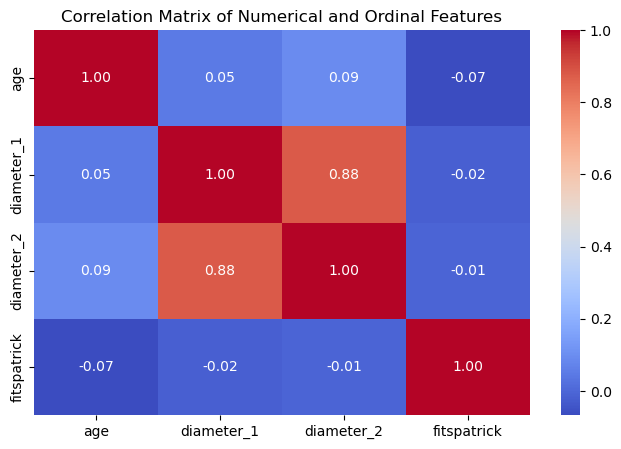

In [235]:
# 159. Visualise correlations between numerical and ordinal features
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical and Ordinal Features")
plt.show()

In [236]:
# 160. Display correlation values rounded to three decimal places
correlation_matrix.round(3)

,age,diameter_1,diameter_2,fitspatrick
age,1.000,0.048,0.092,-0.067
diameter_1,0.048,1.000,0.878,-0.017
diameter_2,0.092,0.878,1.000,-0.008
fitspatrick,-0.067,-0.017,-0.008,1.000


In [237]:
# 161. Compare average age across diagnostic categories
X_train_processed.assign(diagnostic=y_train).groupby(
    "diagnostic"
)["age"].mean().sort_values(ascending=False)

diagnostic
SCC    68.520000
SEK    66.827815
BCC    63.506591
ACK    61.772640
MEL    57.230769
NEV    35.417722
Name: age, dtype: float64

In [238]:
# 162. Compare average diameter_1 across diagnostic categories
X_train_processed.assign(diagnostic=y_train).groupby(
    "diagnostic"
)["diameter_1"].mean().sort_values(ascending=False)

diagnostic
MEL    13.961538
SCC    11.808000
BCC    11.478719
ACK    10.329480
NEV    10.246835
SEK     9.781457
Name: diameter_1, dtype: float64

In [239]:
# 163. Compare average diameter_2 across diagnostic categories
X_train_processed.assign(diagnostic=y_train).groupby(
    "diagnostic"
)["diameter_2"].mean().sort_values(ascending=False)

diagnostic
MEL    9.807692
SCC    9.376000
BCC    8.542750
ACK    7.473988
SEK    6.940397
NEV    6.860759
Name: diameter_2, dtype: float64

In [240]:
# 164. Compare average Fitzpatrick skin type across diagnostic categories
X_train_processed.assign(diagnostic=y_train).groupby(
    "diagnostic"
)["fitspatrick"].mean().sort_values(ascending=False)

diagnostic
MEL    2.346154
SCC    2.232000
BCC    2.171375
NEV    2.164557
ACK    2.140655
SEK    2.086093
Name: fitspatrick, dtype: float64

# Numerical and Ordinal Feature Analysis

The relationships between the numerical and ordinal features and the target variable (`diagnostic`) were investigated using correlation analysis and group-level descriptive statistics.

**1. Correlation analysis**

Pearson correlation was used to examine linear relationships between the numerical and ordinal features.

The main finding was a strong positive correlation between `diameter_1` and `diameter_2` (0.878). The remaining feature pairs showed very weak correlations.

Both diameter measurements were retained because they represent separate lesion measurements and may provide useful predictive information.

**2. Age by diagnostic category**

The average age varied across diagnostic categories:

- SCC had the highest average age (68.52).
- NEV had the lowest average age (35.42).

This suggests that age may provide useful information for distinguishing between diagnostic categories.

**3. Lesion diameter by diagnostic category**

Both diameter measurements showed similar patterns:

- MEL had the highest average `diameter_1` (13.96) and `diameter_2` (9.81).
- SEK had the lowest average `diameter_1` (9.78).
- NEV had the lowest average `diameter_2` (6.86).

**4. Fitzpatrick skin type by diagnostic category**

The average Fitzpatrick values ranged from 2.09 (SEK) to 2.35 (MEL). The differences were relatively small.

Since Fitzpatrick is an ordinal variable, its mean should be interpreted cautiously.

**5. Overall findings**

Age and lesion diameter measurements showed differences across diagnostic categories and may contribute useful predictive information. The two diameter measurements were also strongly correlated,

### Gender vs Diagnosis

In [242]:
# 165. Compare gender distribution across diagnostic categories
X_train.assign(diagnostic=y_train).groupby(
    ["diagnostic", "gender"]
).size().unstack(fill_value=0)

gender,FEMALE,MALE,Missing
diagnostic,,,
ACK,111,91,317
BCC,260,271,0
MEL,14,12,0
NEV,28,13,117
SCC,60,65,0
SEK,17,10,124


In [243]:
# 166. Compare lesion region across diagnostic categories
X_train.assign(diagnostic=y_train).groupby(
    ["diagnostic", "region"]
).size().unstack(fill_value=0)

region,ABDOMEN,ARM,BACK,CHEST,EAR,FACE,FOOT,FOREARM,HAND,LIP,NECK,NOSE,SCALP,THIGH
diagnostic,,,,,,,,,,,,,,
ACK,1,51,12,41,8,107,3,182,62,3,15,17,3,14
BCC,1,26,49,76,25,169,0,41,12,7,29,88,0,8
MEL,1,3,7,3,1,2,0,3,0,0,1,0,0,5
NEV,10,7,51,16,3,24,4,9,6,3,5,0,7,13
SCC,1,12,13,9,8,23,4,19,12,5,7,4,1,7
SEK,7,8,16,21,8,62,0,13,1,0,3,2,4,6


### Symptom vs Diagnosis

In [244]:
# 167. Compare itching across diagnostic categories
X_train.assign(diagnostic=y_train).groupby(
    ["diagnostic", "itch"]
).size().unstack(fill_value=0)

itch,FALSE,TRUE,UNK
diagnostic,,,
ACK,124,394,1
BCC,133,398,0
MEL,23,3,0
NEV,142,15,1
SCC,23,99,3
SEK,108,43,0


# Itching (`itch`) by Diagnostic Category

The distribution of itching responses was examined across the six diagnostic categories.

The main observations were:

- ACK and BCC had high counts of lesions recorded as itching (TRUE).
- MEL and NEV had higher counts of lesions recorded as not itching (FALSE).
- SCC also had more observations recorded as itching.
- SEK had more observations recorded as not itching.
- The UNK category had very few observations across all diagnostic categories.

The differences in itching responses across diagnostic categories suggest that `itch` may provide useful information for classification.
The UNK category represents an existing unknown response in the dataset and was retained separately. These findings are descriptive and do not establish predictive importance.

In [246]:
# 168. Compare lesion growth across diagnostic categories
X_train.assign(diagnostic=y_train).groupby(
    ["diagnostic", "grew"]
).size().unstack(fill_value=0)

grew,FALSE,TRUE,UNK
diagnostic,,,
ACK,429,87,3
BCC,81,234,216
MEL,2,18,6
NEV,49,90,19
SCC,21,42,62
SEK,76,69,6


# Lesion Growth (`grew`) by Diagnostic Category

The distribution of lesion growth was examined across the six diagnostic categories.

The main observations were:

- ACK had the highest count of lesions recorded as not growing (FALSE).
- BCC had more observations recorded as growing (TRUE) than not growing, with a substantial number classified as UNK.
- MEL and NEV had more observations recorded as growing.
- SCC had a considerable number of unknown responses.
- SEK showed relatively similar counts for growing and not growing.

The `UNK` category represents an existing unknown response in the dataset and was retained as a separate category during preprocessing.

The differences in growth responses across diagnostic categories suggest that `grew` may provide useful information for classification. However, these results are descriptive and do not establish predictive importance.

In [248]:
# 169. Compare pain responses across diagnostic categories
X_train.assign(diagnostic=y_train).groupby(
    ["diagnostic", "hurt"]
).size().unstack(fill_value=0)

hurt,FALSE,TRUE,UNK
diagnostic,,,
ACK,481,37,1
BCC,351,177,3
MEL,26,0,0
NEV,151,4,3
SCC,96,28,1
SEK,149,2,0


# Pain (`hurt`) by Diagnostic Category

The distribution of pain responses was examined across the six diagnostic categories.

The main observations were:

- Most lesions across all diagnostic categories were recorded as not painful (FALSE).
- BCC had the highest count of painful lesions (TRUE), with 177 observations.
- MEL had no observations recorded as painful.
- NEV and SEK had very few observations recorded as painful.
- SCC and ACK also had more observations recorded as not painful than painful.

The UNK category had very few observations across the diagnostic categories.

Although the number of painful responses varied between diagnoses, most observations were recorded as not painful. The `hurt` feature will be retained for the classification experiments. These findings are descriptive and do not establish predictive importance.

In [250]:
# 170. Compare changes in lesions across diagnostic categories
X_train.assign(diagnostic=y_train).groupby(
    ["diagnostic", "changed"]
).size().unstack(fill_value=0)

changed,FALSE,TRUE,UNK
diagnostic,,,
ACK,495,22,2
BCC,273,42,216
MEL,5,16,5
NEV,124,15,19
SCC,49,14,62
SEK,141,4,6


# Changes in Appearance (`changed`) by Diagnostic Category

The distribution of reported changes in lesions was examined across the six diagnostic categories.

The main observations were:

- ACK, NEV and SEK had more observations recorded as not having changed (FALSE).
- MEL had more observations recorded as having changed (TRUE), although its sample size was relatively small.
- BCC had a substantial number of unknown responses (UNK).
- SCC also had a considerable number of unknown responses.

The `UNK` category represents an existing unknown response in the dataset and was retained separately during preprocessing.

The variation in responses suggests that `changed` may provide useful information for classification. However, these findings are descriptive and do not establish predictive importance.

In [252]:
# 171. Compare bleeding across diagnostic categories
X_train.assign(diagnostic=y_train).groupby(
    ["diagnostic", "bleed"]
).size().unstack(fill_value=0)

bleed,FALSE,TRUE,UNK
diagnostic,,,
ACK,468,51,0
BCC,250,276,5
MEL,26,0,0
NEV,156,1,1
SCC,86,39,0
SEK,149,2,0


# Bleeding (`bleed`) by Diagnostic Category

The distribution of bleeding responses was examined across the six diagnostic categories.

The main observations were:

- ACK, MEL, NEV, SCC and SEK had more observations recorded as not bleeding (FALSE).
- BCC had more observations recorded as bleeding (TRUE) than not bleeding.
- MEL and NEV had very few or no observations recorded as bleeding.
- The UNK category contained very few observations.

The variation in bleeding responses across diagnostic categories suggests that `bleed` may provide useful information for classification. The feature will be retained for the classification experiments. These findings are descriptive and do not establish predictive importance.

In [254]:
# 172. Compare lesion elevation across diagnostic categories
X_train.assign(diagnostic=y_train).groupby(
    ["diagnostic", "elevation"]
).size().unstack(fill_value=0)

elevation,FALSE,TRUE,UNK
diagnostic,,,
ACK,375,144,0
BCC,74,457,0
MEL,19,7,0
NEV,62,95,1
SCC,29,96,0
SEK,39,112,0


# Lesion Elevation (`elevation`) by Diagnostic Category

The distribution of lesion elevation responses was examined across the six diagnostic categories.

The main observations were:

- ACK and MEL had more observations recorded as not elevated (FALSE).
- BCC had a substantially higher number of observations recorded as elevated (TRUE).
- NEV, SCC and SEK also had more observations recorded as elevated.
- Only one observation was classified as UNK, belonging to NEV.

The variation in elevation responses suggests that `elevation` may provide useful information for classification. The feature will be retained for the classification experiments. These findings are descriptive and do not establish predictive importance.

In [256]:
# ## Feature Selection Summary

# The initial feature-selection analysis was conducted to examine the characteristics and potential relevance of the available features before model development.

# The following observations were made:

# - **Constant features:** No constant features were identified in the training dataset.
# - **Correlation:** `diameter_1` and `diameter_2` showed a strong positive correlation (0.878), indicating that the two measurements are closely related.
# - **Numerical features:** Age, lesion diameters and Fitzpatrick skin type showed variations across diagnostic categories.
# - **Categorical features:** Gender and lesion region showed differences in their distributions across diagnostic categories.
# - **Symptom-related features:** Itching, growth, pain, changes, bleeding and elevation also showed variations across diagnostic categories.

# Based on these preliminary observations, no additional features were removed at this stage. Although some features showed stronger differences or correlations, their actual predictive contribution will be assessed during model development.

# The processed dataset therefore retains 84 features, consisting of numerical, ordinal and one-hot encoded categorical variables.

# The next stage will involve training and evaluating traditional machine-learning classification algorithms.

# STAGE 5 - ML Models

# 4. Traditional Machine Learning

In this stage, traditional machine-learning classification algorithms will be trained and evaluated to predict the diagnostic category of skin lesions.

The target variable is `diagnostic`, which contains six diagnostic categories: ACK, BCC, MEL, NEV, SCC and SEK.

Multiple algorithms will be investigated and compared to identify differences in their classification performance.

# 4.1 Decision Tree Classifier

A Decision Tree Classifier is a supervised machine-learning algorithm that makes predictions by learning a series of decision rules from training data.

It was selected for this project for the following reasons:

- **Classification suitability:** It supports multi-class classification, making it suitable for predicting the six diagnostic categories.
- **Non-linear relationships:** It can identify complex relationships between input features and the target variable.
- **Feature compatibility:** It can work with numerical, ordinal and one-hot encoded categorical features without requiring feature scaling.
- **Interpretability:** Its tree structure allows decision-making processes and feature importance to be examined.
- **Model comparison:** It provides a useful tree-based model against which other classification algorithms can be compared.

The Decision Tree will be trained using the training dataset and evaluated using the held-out test dataset.

### Decision Trees

In [258]:
# 173. Initialise the Decision Tree Classifier
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

# Model Configuration

The Decision Tree Classifier was initialised with the following parameters:

- `criterion="gini"`: Uses Gini impurity to measure the quality of potential splits.
- `max_depth=5`: Limits the maximum depth of the tree to control model complexity and reduce the risk of overfitting.
- `random_state=42`: Ensures reproducibility when the algorithm uses randomised operations.

The maximum depth of five was selected as an initial configuration. Its suitability will be assessed during model evaluation and tuning.

In [260]:
# 174. Train the Decision Tree Classifier
dt_model.fit(X_train_processed, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [261]:
# 175. Predict diagnostic categories using the test dataset
y_pred_dt = dt_model.predict(X_test_processed)

In [262]:
# 176. Import classification evaluation metrics
from sklearn.metrics import accuracy_score, classification_report

In [263]:
# 177. Calculate model accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", accuracy_dt)

Decision Tree Accuracy: 0.7060367454068242


In [264]:
# 178. Generate classification report
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

         ACK       0.75      0.82      0.78       125
         BCC       0.71      0.82      0.76       121
         MEL       0.54      0.70      0.61        10
         NEV       0.75      0.71      0.73        58
         SCC       0.18      0.10      0.13        20
         SEK       0.69      0.38      0.49        47

    accuracy                           0.71       381
   macro avg       0.60      0.59      0.58       381
weighted avg       0.69      0.71      0.69       381



# Decision Tree – Classification Report

The Decision Tree Classifier achieved an accuracy of approximately **70.60%** on the test dataset.

The classification report showed varying performance across the six diagnostic categories:

- **ACK:** Achieved an F1-score of 0.78, with a recall of 0.82.
- **BCC:** Achieved an F1-score of 0.76, with a recall of 0.82.
- **MEL:** Achieved an F1-score of 0.61. This result should be interpreted cautiously because only 10 test records belonged to this category.
- **NEV:** Achieved an F1-score of 0.73, with a recall of 0.71.
- **SCC:** Achieved a low F1-score of 0.13, with a recall of 0.10.
- **SEK:** Achieved an F1-score of 0.49, with a recall of 0.38.

The macro-average F1-score was 0.58, while the weighted-average F1-score was 0.69.

The difference between these scores highlights the effect of class imbalance. The model performed better on some of the more represented diagnostic categories but struggled particularly with SCC and SEK.

Overall, although the Decision Tree achieved 70.60% accuracy, its ability to classify all six diagnostic categories consistently remains limited.

### Confusion Matrix

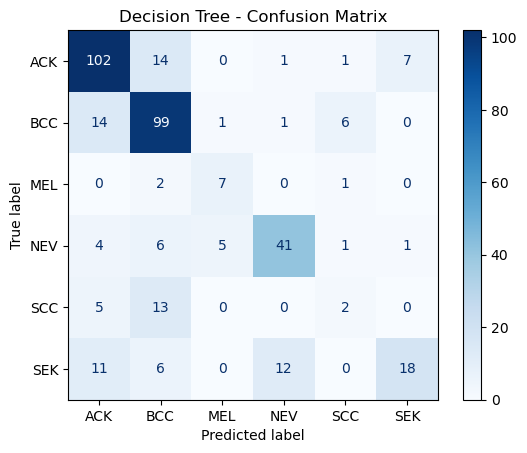

In [266]:
# 179. # Generate confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=dt_model.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [267]:
# 180. Generate confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)

# Convert confusion matrix into a DataFrame
cm_dt_df = pd.DataFrame(
    cm_dt,
    index=dt_model.classes_,
    columns=dt_model.classes_
)

# Display numerical confusion matrix
cm_dt_df

,ACK,BCC,MEL,NEV,SCC,SEK
ACK,102,14,0,1,1,7
BCC,14,99,1,1,6,0
MEL,0,2,7,0,1,0
NEV,4,6,5,41,1,1
SCC,5,13,0,0,2,0
SEK,11,6,0,12,0,18


# Decision Tree – Confusion Matrix

The confusion matrix was examined to identify the correct and incorrect predictions made by the Decision Tree Classifier.

The diagonal values represent correct predictions, while the values outside the diagonal represent misclassifications.

The main observations were:

- ACK had 102 correct predictions out of 125 records.
- BCC had 99 correct predictions out of 121 records.
- MEL had 7 correct predictions out of 10 records.
- NEV had 41 correct predictions out of 58 records.
- SCC had only 2 correct predictions out of 20 records. Most SCC cases were incorrectly classified as BCC.
- SEK had 18 correct predictions out of 47 records, with several cases incorrectly classified as NEV or ACK.

The confusion matrix confirms that the Decision Tree performs better for ACK and BCC but struggles to distinguish SCC and SEK.

These results highlight the difficulty of classifying less represented diagnostic categories and demonstrate why accuracy alone is insufficient for evaluating this multi-class classification problem.

In [269]:
# 181. Extract feature importance from the trained Decision Tree
dt_importance = pd.DataFrame({
    "Feature": X_train_processed.columns,
    "Importance": dt_model.feature_importances_
})

# Sort features by importance
dt_importance = dt_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
dt_importance.head(15)

,Feature,Importance
26,background_mother_Missing,0.339474
0,age,0.156068
67,itch_TRUE,0.149598
69,grew_FALSE,0.128476
82,elevation_TRUE,0.098993
81,elevation_FALSE,0.027245
79,bleed_TRUE,0.022618
2,diameter_2,0.019607
57,region_FACE,0.012988
63,region_NOSE,0.012231


# Decision Tree – Feature Importance

Feature importance was extracted from the trained Decision Tree Classifier to identify which features contributed most to its splitting decisions.

The five most important features were:

1. `background_mother_Missing` – 0.3395
2. `age` – 0.1561
3. `itch_TRUE` – 0.1496
4. `grew_FALSE` – 0.1285
5. `elevation_TRUE` – 0.0990

The most notable finding was the high importance assigned to `background_mother_Missing`.

This may be related to the structured missing-data pattern identified during preprocessing, where several features were missing together and missingness varied across diagnostic categories.

Age and symptom-related features, particularly itching, growth and elevation, also contributed to the model's decisions.

These importance scores reflect the behaviour of this particular Decision Tree and should not be interpreted as evidence of causation or general predictive importance. The influence of missingness will be considered when interpreting the overall model results.

### K-Nearest Neighbours (KNN)

# K-Nearest Neighbours (KNN)

K-Nearest Neighbours (KNN) is a supervised machine-learning algorithm used for classification. It predicts the category of a new observation by identifying the nearest observations in the training dataset.

The algorithm calculates distances between observations, identifies the K nearest neighbours and assigns the most frequent class among them.

KNN was selected for this project for the following reasons:

- **Multi-class classification:** It supports classification across the six diagnostic categories.
- **Distance-based learning:** It identifies similarities between observations based on their feature values.
- **Model comparison:** It provides a different learning approach from the rule-based Decision Tree.
- **Pattern recognition:** It can identify groups of observations with similar characteristics.

Feature scaling is important for KNN because the algorithm relies on distance calculations. Features with larger numerical ranges could otherwise dominate the distance measurements.

Therefore, the scaled training and testing datasets will be used for KNN.

In [272]:
# 182. Initialise the KNN Classifier
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric="minkowski",
    p=2
)

# Model Configuration

The KNN Classifier was initialised with the following parameters:

- `n_neighbors=5`: Considers the five nearest training observations when making predictions.
- `metric="minkowski"`: Specifies the distance metric used to calculate similarity between observations.
- `p=2`: Uses Euclidean distance, which calculates the straight-line distance between observations.

A value of five neighbours was selected as an initial configuration. The choice of K can influence classification performance and will be investigated further during model evaluation and tuning.

In [274]:
# 183. Train the KNN Classifier
knn_model.fit(X_train_scaled, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [275]:
# 184. Predict diagnostic categories using the test dataset
y_pred_knn = knn_model.predict(X_test_scaled)

In [276]:
# 185. Calculate KNN accuracy
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", accuracy_knn)

KNN Accuracy: 0.6797900262467191


In [277]:
# 186. Generate KNN classification report
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

         ACK       0.75      0.84      0.79       125
         BCC       0.65      0.81      0.72       121
         MEL       0.00      0.00      0.00        10
         NEV       0.74      0.55      0.63        58
         SCC       0.27      0.15      0.19        20
         SEK       0.60      0.45      0.51        47

    accuracy                           0.68       381
   macro avg       0.50      0.47      0.48       381
weighted avg       0.66      0.68      0.66       381



# KNN Classification Report – Interpretation

The KNN model achieved an accuracy of 67.98%, with a macro F1-score of 0.48 and a weighted F1-score of 0.66.

The model performed relatively well for ACK and BCC, achieving recall scores of 0.84 and 0.81 respectively. However, performance was considerably weaker for MEL and SCC. The model failed to correctly identify any MEL cases, while SCC recall was only 0.15.

The difference between macro and weighted F1-scores indicates that KNN performs better on the more frequently represented diagnostic categories.

Overall, the classification report highlights the challenges of applying KNN to this imbalanced, multi-class dataset. Accuracy alone does not adequately represent its performance across all diagnostic categories.

### Confusion Matrix

In [279]:
# 187. Generate KNN confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

# Convert confusion matrix into a DataFrame
cm_knn_df = pd.DataFrame(
    cm_knn,
    index=knn_model.classes_,
    columns=knn_model.classes_
)

# Display numerical confusion matrix
cm_knn_df

,ACK,BCC,MEL,NEV,SCC,SEK
ACK,105,14,0,0,1,5
BCC,14,98,0,1,7,1
MEL,1,9,0,0,0,0
NEV,4,12,2,32,0,8
SCC,3,13,0,1,3,0
SEK,13,4,0,9,0,21


# KNN Confusion Matrix – Interpretation

The confusion matrix provides further insight into the KNN model's classification performance.

The model correctly classified 105 ACK cases and 98 BCC cases. However, it struggled with the less represented diagnostic categories.

All 10 MEL cases were misclassified, with 9 predicted as BCC and 1 as ACK. Similarly, only 3 out of 20 SCC cases were correctly identified, while 13 were misclassified as BCC.

The model also confused NEV and SEK with other categories, particularly BCC, ACK and NEV.

Overall, the confusion matrix confirms that KNN performs better for the more frequently represented classes and struggles to distinguish several minority diagnostic categories.

### Logistic Regression

In [281]:
# 188. Initialise the Logistic Regression Classifier
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [282]:
# 189. Train the Logistic Regression Classifier
lr_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [283]:
# 190. Predict diagnostic categories using the test dataset
y_pred_lr = lr_model.predict(X_test_scaled)

In [409]:
# 191. Calculate Logistic Regression accuracy
accuracy_lr = accuracy_score(y_test, y_pred_lr)

print("Logistic Regression Accuracy:", accuracy_lr)

Logistic Regression Accuracy: 0.7296587926509186


In [285]:
# 192. Generate Logistic Regression classification report
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

         ACK       0.77      0.86      0.82       125
         BCC       0.76      0.83      0.79       121
         MEL       0.40      0.20      0.27        10
         NEV       0.79      0.72      0.76        58
         SCC       0.20      0.15      0.17        20
         SEK       0.62      0.49      0.55        47

    accuracy                           0.73       381
   macro avg       0.59      0.54      0.56       381
weighted avg       0.71      0.73      0.72       381



# Logistic Regression Classification Report – Interpretation

The Logistic Regression model achieved an accuracy of 72.97%, with a macro F1-score of 0.56 and a weighted F1-score of 0.72.

The model performed relatively well for ACK, BCC and NEV, achieving F1-scores of 0.82, 0.79 and 0.76 respectively.

However, performance was weaker for MEL and SCC, with F1-scores of 0.27 and 0.17. The model identified only 20% of actual MEL cases and 15% of actual SCC cases.

The difference between macro and weighted F1-scores indicates that the model performs better on the more frequently represented diagnostic categories.

Overall, Logistic Regression achieved the highest accuracy and macro F1-score among the three algorithms evaluated so far, although its performance on minority diagnostic categories remains limited.

### Confusion Matrix

In [287]:
# 193. Generate Logistic Regression confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)

# Convert confusion matrix into a DataFrame
cm_lr_df = pd.DataFrame(
    cm_lr,
    index=lr_model.classes_,
    columns=lr_model.classes_
)

# Display numerical confusion matrix
cm_lr_df

,ACK,BCC,MEL,NEV,SCC,SEK
ACK,108,6,0,2,4,5
BCC,13,100,1,1,6,0
MEL,1,5,2,1,1,0
NEV,1,5,0,42,1,9
SCC,4,11,2,0,3,0
SEK,13,4,0,7,0,23


# Logistic Regression Confusion Matrix – Interpretation

The confusion matrix provides further insight into the Logistic Regression model's classification performance.

The model correctly classified 108 ACK cases, 100 BCC cases and 42 NEV cases.

However, performance was weaker for MEL and SCC. Only 2 out of 10 MEL cases and 3 out of 20 SCC cases were correctly classified. Five MEL cases and eleven SCC cases were misclassified as BCC.

The model also confused NEV with SEK and SEK with ACK.

Overall, the confusion matrix confirms that Logistic Regression performs better for the more frequently represented diagnostic categories, while classification of MEL and SCC remains challenging.

### Random Forest

In [289]:
# 194. Initialise the Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42
)

In [290]:
# 195. Train the Random Forest Classifier
rf_model.fit(X_train_processed, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [291]:
# 196. Predict diagnostic categories using the test dataset
y_pred_rf = rf_model.predict(X_test_processed)

In [292]:
# 197. Calculate Random Forest accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", accuracy_rf)

Random Forest Accuracy: 0.7034120734908137


In [293]:
# 198. Generate Random Forest classification report
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

         ACK       0.78      0.84      0.81       125
         BCC       0.66      0.89      0.76       121
         MEL       0.67      0.20      0.31        10
         NEV       0.75      0.62      0.68        58
         SCC       0.00      0.00      0.00        20
         SEK       0.63      0.36      0.46        47

    accuracy                           0.70       381
   macro avg       0.58      0.49      0.50       381
weighted avg       0.67      0.70      0.67       381



# Random Forest Classification Report – Interpretation

The Random Forest model achieved an accuracy of 70.34%, with a macro F1-score of 0.50 and a weighted F1-score of 0.67.

The model performed relatively well for ACK and BCC, achieving F1-scores of 0.81 and 0.76 respectively. BCC had a recall of 0.89, indicating that the model identified most of the actual BCC cases.

However, performance was weaker for MEL, SCC and SEK. Although MEL achieved a precision of 0.67, its recall was only 0.20. The model failed to identify any of the 20 SCC cases.

The difference between macro and weighted F1-scores indicates that the model performs better on the more frequently represented diagnostic categories.

Overall, Random Forest provides reasonable performance for the more frequent categories but struggles with some minority diagnostic classes.

### Confusion Matrix

In [295]:
# 199. Generate Random Forest confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)

# Convert confusion matrix into a DataFrame
cm_rf_df = pd.DataFrame(
    cm_rf,
    index=rf_model.classes_,
    columns=rf_model.classes_
)

# Display numerical confusion matrix
cm_rf_df

,ACK,BCC,MEL,NEV,SCC,SEK
ACK,105,14,0,2,1,3
BCC,11,108,1,0,1,0
MEL,1,5,2,0,2,0
NEV,2,13,0,36,0,7
SCC,3,17,0,0,0,0
SEK,13,7,0,10,0,17


# Random Forest Confusion Matrix – Interpretation

The confusion matrix provides further insight into the Random Forest model's classification performance.

The model correctly classified 105 ACK cases, 108 BCC cases, 2 MEL cases, 36 NEV cases and 17 SEK cases.

However, it failed to correctly classify any SCC cases. Seventeen SCC cases were incorrectly predicted as BCC, while the remaining three were predicted as ACK.

The model also confused MEL with BCC, with five out of ten MEL cases incorrectly classified as BCC.

Overall, the confusion matrix shows that Random Forest performs relatively well for BCC and ACK but struggles to distinguish several less frequently represented diagnostic categories, particularly SCC.

# Comparison of Traditional Machine Learning Algorithms

Four traditional machine-learning algorithms were evaluated: Decision Tree, K-Nearest Neighbours (KNN), Logistic Regression and Random Forest. All models were evaluated using the same held-out test dataset of 381 records.

# 1. Overall Performance Comparison

| Evaluation Metric | Decision Tree | KNN | Logistic Regression | Random Forest |
|---|---:|---:|---:|---:|
| Accuracy | 70.60% | 67.98% | **72.97%** | 70.34% |
| Macro Precision | **0.60** | 0.50 | 0.59 | 0.58 |
| Macro Recall | **0.59** | 0.47 | 0.54 | 0.49 |
| Macro F1-score | **0.58** | 0.48 | 0.56 | 0.50 |
| Weighted F1-score | 0.69 | 0.66 | **0.72** | 0.67 |

Logistic Regression achieved the highest accuracy and weighted F1-score, while Decision Tree achieved the highest macro precision, macro recall and macro F1-score.

# 2. Performance Comparison by Diagnostic Category

| Diagnosis | Decision Tree | KNN | Logistic Regression | Random Forest |
|---|---:|---:|---:|---:|
| ACK | 0.78 | 0.79 | **0.82** | 0.81 |
| BCC | 0.76 | 0.72 | **0.79** | 0.76 |
| MEL | **0.61** | 0.00 | 0.27 | 0.31 |
| NEV | 0.73 | 0.63 | **0.76** | 0.68 |
| SCC | 0.13 | **0.19** | 0.17 | 0.00 |
| SEK | 0.49 | 0.51 | **0.55** | 0.46 |

The results show that Logistic Regression achieved the highest F1-scores for ACK, BCC, NEV and SEK. Decision Tree performed best for MEL, while KNN performed best for SCC. However, all models struggled with SCC classification.

# 3. Model Strengths and Limitations

| Algorithm | Strengths | Limitations |
|---|---|---|
| Decision Tree | Interpretable, learns non-linear relationships and achieved the highest macro F1-score. | A single tree can overfit and is sensitive to its configuration. |
| KNN | Distance-based classification identifies similarities between observations. | Sensitive to feature scaling, high-dimensional data and class imbalance. |
| Logistic Regression | Highest accuracy and weighted F1-score; performed well across several diagnostic categories. | May struggle with complex non-linear relationships. |
| Random Forest | Combines multiple decision trees and can learn complex patterns. | Did not outperform Decision Tree in this experiment and failed to identify SCC cases. |

# 4. Overall Comparison and Conclusion

| Comparison Area | Best Performing Model |
|---|---|
| Highest Accuracy | Logistic Regression (72.97%) |
| Highest Macro Precision | Decision Tree (0.60) |
| Highest Macro Recall | Decision Tree (0.59) |
| Highest Macro F1-score | Decision Tree (0.58) |
| Highest Weighted F1-score | Logistic Regression (0.72) |
| Best ACK F1-score | Logistic Regression (0.82) |
| Best BCC F1-score | Logistic Regression (0.79) |
| Best MEL F1-score | Decision Tree (0.61) |
| Best NEV F1-score | Logistic Regression (0.76) |
| Best SCC F1-score | KNN (0.19) |
| Best SEK F1-score | Logistic Regression (0.55) |

**Conclusion**

Logistic Regression demonstrated the strongest overall performance in terms of accuracy and weighted F1-score. Decision Tree achieved the highest macro F1-score and macro recall, indicating more balanced performance across the six diagnostic categories.

All four models struggled to classify minority categories, particularly MEL and SCC. This suggests that class imbalance and the characteristics of the dataset may have influenced model performance.

Further evaluation using a neural network and model tuning will help determine whether classification performance can be improved.

## Hyperparameter Tuning

# Hyperparameter Tuning

Hyperparameter tuning is the process of testing different model configurations to identify which settings produce the best performance.

In this stage, GridSearchCV will be used with five-fold StratifiedGroupKFold cross-validation. Macro F1-score will be used to evaluate the configurations, giving equal importance to all six diagnostic categories.

The models will be tuned individually, and their performance will later be compared with the baseline models.

### Decision Tree Tuning

In [299]:
# 200. DECISION TREE HYPERPARAMETER TUNING

# Define hyperparameter combinations for Decision Tree
dt_param_grid = {
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "criterion": ["gini", "entropy"]
}

In [300]:
# 201. Configure 5-fold stratified group cross-validation
dt_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [301]:
# 202. Configure GridSearchCV for Decision Tree
dt_grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    scoring="f1_macro",
    cv=dt_cv,
    n_jobs=-1,
    verbose=1
)

In [310]:
# Restore patient groups for the training and test sets

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

In [311]:
# 203. Perform hyperparameter tuning
dt_grid_search.fit(
    X_train_processed,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 72 candidates, totalling 360 fits


,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedGro... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [312]:
# 204. Display the best Decision Tree parameters
print("Best Parameters:", dt_grid_search.best_params_)

# Display the best cross-validation macro F1-score
print("Best CV Macro F1-score:", dt_grid_search.best_score_)

Best Parameters: {'criterion': 'gini', 'max_depth': None, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best CV Macro F1-score: 0.5454898606722545


In [313]:
# 205. Retrieve the best Decision Tree model
dt_tuned = dt_grid_search.best_estimator_

In [314]:
# 206. Generate predictions using the tuned Decision Tree
y_pred_dt_tuned = dt_tuned.predict(X_test_processed)

In [315]:
# 207. Calculate accuracy of the tuned Decision Tree
dt_tuned_accuracy = accuracy_score(y_test, y_pred_dt_tuned)

print("Tuned Decision Tree Accuracy:", dt_tuned_accuracy)

Tuned Decision Tree Accuracy: 0.6824146981627297


In [316]:
# 208. Generate classification report for tuned Decision Tree
print(classification_report(y_test, y_pred_dt_tuned))

              precision    recall  f1-score   support

         ACK       0.72      0.83      0.77       125
         BCC       0.71      0.74      0.72       121
         MEL       0.80      0.40      0.53        10
         NEV       0.75      0.62      0.68        58
         SCC       0.17      0.20      0.18        20
         SEK       0.68      0.49      0.57        47

    accuracy                           0.68       381
   macro avg       0.64      0.55      0.58       381
weighted avg       0.69      0.68      0.68       381



### Tuned Confusion Matrix

In [317]:
# 209. Generate confusion matrix for tuned Decision Tree
cm_dt_tuned = confusion_matrix(y_test, y_pred_dt_tuned)

print(cm_dt_tuned)

[[104  10   0   3   4   4]
 [ 18  89   0   1  13   0]
 [  0   2   4   1   2   1]
 [  4  11   0  36   1   6]
 [  6   9   1   0   4   0]
 [ 12   5   0   7   0  23]]


# Decision Tree – Hyperparameter Tuning Results

Hyperparameter tuning was performed using GridSearchCV with five-fold StratifiedGroupKFold cross-validation. Macro F1-score was used as the optimisation metric.

The best configuration was:

| Hyperparameter | Selected value |
|---|---|
| Criterion | Gini |
| Maximum depth | None |
| Minimum samples split | 2 |
| Minimum samples leaf | 4 |

The best cross-validation macro F1-score was 0.5455.

On the test dataset, the tuned Decision Tree achieved an accuracy of 68.24%, compared with 70.60% for the baseline model.

| Metric | Baseline | Tuned |
|---|---:|---:|
| Accuracy | 0.71 | 0.68 |
| Macro precision | 0.60 | 0.64 |
| Macro recall | 0.59 | 0.55 |
| Macro F1-score | 0.58 | 0.58 |
| Weighted F1-score | 0.69 | 0.68 |

The tuned model improved the F1-score for SCC and SEK but performed worse for ACK, BCC, MEL and NEV.

Overall, hyperparameter tuning did not produce a clear improvement in test performance. The baseline Decision Tree achieved higher accuracy and weighted F1-score, while both models had approximately the same macro F1-score.

### KNN Hyperparameter Tuning

In [319]:
# 210. KNN HYPERPARAMETER TUNING

# Define hyperparameter combinations for KNN
knn_param_grid = {
    "n_neighbors": [3, 5, 7, 9, 11],
    "weights": ["uniform", "distance"],
    "p": [1, 2]
}

In [320]:
# 211. Configure 5-fold stratified group cross-validation for KNN
knn_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [321]:
# 212. Configure GridSearchCV for KNN
knn_grid_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=knn_param_grid,
    scoring="f1_macro",
    cv=knn_cv,
    n_jobs=-1,
    verbose=1
)

In [322]:
# 213. Perform hyperparameter tuning for KNN
knn_grid_search.fit(
    X_train_scaled,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


,estimator,KNeighborsClassifier()
,param_grid,"{'n_neighbors': [3, 5, ...], 'p': [1, 2], 'weights': ['uniform', 'distance']}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedGro... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_neighbors,3


In [323]:
# 214. Display the best KNN parameters
print("Best Parameters:", knn_grid_search.best_params_)

# Display the best cross-validation macro F1-score
print("Best CV Macro F1-score:", knn_grid_search.best_score_)

Best Parameters: {'n_neighbors': 3, 'p': 2, 'weights': 'distance'}
Best CV Macro F1-score: 0.5533632612192203


In [324]:
# 215. Retrieve the best KNN model
knn_tuned = knn_grid_search.best_estimator_

In [325]:
# 216. Generate predictions using the tuned KNN model
y_pred_knn_tuned = knn_tuned.predict(X_test_scaled)

In [326]:
# 217. Calculate accuracy of the tuned KNN model
knn_tuned_accuracy = accuracy_score(y_test, y_pred_knn_tuned)

print("Tuned KNN Accuracy:", knn_tuned_accuracy)

Tuned KNN Accuracy: 0.6456692913385826


In [330]:
# 218. Generate classification report for tuned KNN
print(classification_report(y_test, y_pred_knn_tuned))

              precision    recall  f1-score   support

         ACK       0.72      0.80      0.76       125
         BCC       0.67      0.76      0.71       121
         MEL       0.00      0.00      0.00        10
         NEV       0.73      0.52      0.61        58
         SCC       0.18      0.20      0.19        20
         SEK       0.53      0.43      0.47        47

    accuracy                           0.65       381
   macro avg       0.47      0.45      0.46       381
weighted avg       0.64      0.65      0.64       381



### Tuned Confusion Matrix

In [331]:
# 219. Generate confusion matrix for tuned KNN
cm_knn_tuned = confusion_matrix(y_test, y_pred_knn_tuned)

print(cm_knn_tuned)

[[100  13   1   2   3   6]
 [ 17  92   0   0  10   2]
 [  1   6   0   0   2   1]
 [  3  11   4  30   2   8]
 [  2  12   0   1   4   1]
 [ 15   3   0   8   1  20]]


# KNN – Hyperparameter Tuning Results

Hyperparameter tuning was performed using GridSearchCV with five-fold StratifiedGroupKFold cross-validation. Macro F1-score was used as the optimisation metric.

The best configuration was:

| Hyperparameter | Selected value |
|---|---|
| Number of neighbours | 3 |
| Distance weighting | Distance |
| Distance parameter (p) | 2 |

The best cross-validation macro F1-score was 0.5534.

On the test dataset, the tuned KNN achieved an accuracy of 64.57%, compared with 67.98% for the baseline model.

| Metric | Baseline | Tuned |
|---|---:|---:|
| Accuracy | 0.68 | 0.65 |
| Macro precision | 0.50 | 0.47 |
| Macro recall | 0.47 | 0.45 |
| Macro F1-score | 0.48 | 0.46 |
| Weighted F1-score | 0.66 | 0.64 |

The tuned model did not improve the overall test performance. It also failed to correctly classify any MEL records.

Therefore, the baseline KNN was retained as the better-performing configuration based on the test results.

### Logistic Regression Tuning

In [333]:
# 220. LOGISTIC REGRESSION HYPERPARAMETER TUNING

# Define hyperparameter combinations for Logistic Regression
lr_param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": [None, "balanced"]
}

In [334]:
# 221. Configure 5-fold stratified group cross-validation for Logistic Regression
lr_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [335]:
# 222. Configure GridSearchCV for Logistic Regression
lr_grid_search = GridSearchCV(
    estimator=LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    param_grid=lr_param_grid,
    scoring="f1_macro",
    cv=lr_cv,
    n_jobs=-1,
    verbose=1
)

In [336]:
# 223. Perform hyperparameter tuning for Logistic Regression
lr_grid_search.fit(
    X_train_scaled,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,estimator,LogisticRegre...ndom_state=42)
,param_grid,"{'C': [0.01, 0.1, ...], 'class_weight': [None, 'balanced']}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedGro... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [337]:
# 224. Display the best Logistic Regression parameters and CV score
print("Best Parameters:", lr_grid_search.best_params_)
print("Best CV Macro F1-score:", lr_grid_search.best_score_)

Best Parameters: {'C': 1, 'class_weight': None}
Best CV Macro F1-score: 0.6196059474447752


In [338]:
# 225. Retrieve the best Logistic Regression model
lr_tuned = lr_grid_search.best_estimator_

In [339]:
# 226. Generate predictions using the tuned Logistic Regression model
y_pred_lr_tuned = lr_tuned.predict(X_test_scaled)

In [340]:
# 227. Calculate accuracy of the tuned Logistic Regression model
lr_tuned_accuracy = accuracy_score(y_test, y_pred_lr_tuned)

print("Tuned Logistic Regression Accuracy:", lr_tuned_accuracy)

Tuned Logistic Regression Accuracy: 0.7296587926509186


In [341]:
# 228. Generate classification report for tuned Logistic Regression
print(classification_report(y_test, y_pred_lr_tuned))

              precision    recall  f1-score   support

         ACK       0.77      0.86      0.82       125
         BCC       0.76      0.83      0.79       121
         MEL       0.40      0.20      0.27        10
         NEV       0.79      0.72      0.76        58
         SCC       0.20      0.15      0.17        20
         SEK       0.62      0.49      0.55        47

    accuracy                           0.73       381
   macro avg       0.59      0.54      0.56       381
weighted avg       0.71      0.73      0.72       381



In [342]:
# 229. Generate confusion matrix for tuned Logistic Regression
cm_lr_tuned = confusion_matrix(y_test, y_pred_lr_tuned)

print(cm_lr_tuned)

[[108   6   0   2   4   5]
 [ 13 100   1   1   6   0]
 [  1   5   2   1   1   0]
 [  1   5   0  42   1   9]
 [  4  11   2   0   3   0]
 [ 13   4   0   7   0  23]]


# Logistic Regression – Hyperparameter Tuning Results

Hyperparameter tuning was performed using GridSearchCV with five-fold StratifiedGroupKFold cross-validation. Macro F1-score was used as the optimisation metric.

The best configuration was:

| Hyperparameter | Selected value |
|---|---|
| Regularisation strength (C) | 1 |
| Class weight | None |

The best cross-validation macro F1-score was 0.6196.

On the test dataset, the tuned Logistic Regression achieved an accuracy of 72.97%, identical to the baseline model.

| Metric | Baseline | Tuned |
|---|---|---|
| Accuracy | 0.73 | 0.73 |
| Macro precision | 0.59 | 0.59 |
| Macro recall | 0.54 | 0.54 |
| Macro F1-score | 0.56 | 0.56 |
| Weighted F1-score | 0.72 | 0.72 |

GridSearchCV selected the same effective hyperparameter configuration as the original model. Consequently, the predictions and evaluation metrics remained unchanged.

Therefore, hyperparameter tuning did not improve the test performance, but confirmed that the original Logistic Regression configuration was a strong choice among the combinations tested.

### Random Forest Tuning

In [344]:
# 230. RANDOM FOREST HYPERPARAMETER TUNING

# Define hyperparameter combinations for Random Forest
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_leaf": [1, 2, 4]
}

In [345]:
# 231. Configure 5-fold stratified group cross-validation
rf_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [346]:
# 232. Configure GridSearchCV for Random Forest
rf_grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_param_grid,
    scoring="f1_macro",
    cv=rf_cv,
    n_jobs=-1,
    verbose=1
)

In [347]:
# 233. Perform hyperparameter tuning for Random Forest
rf_grid_search.fit(
    X_train_processed,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [None, 10, ...], 'min_samples_leaf': [1, 2, ...], 'n_estimators': [100, 200]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedGro... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [348]:
# 234. Display the best Random Forest hyperparameters and CV score
print("Best Parameters:", rf_grid_search.best_params_)
print("Best CV Macro F1:", rf_grid_search.best_score_)

Best Parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
Best CV Macro F1: 0.5613427412661229


In [349]:
# 235. Retrieve the best Random Forest model
rf_tuned = rf_grid_search.best_estimator_

In [350]:
# 236. Generate predictions using tuned Random Forest
y_pred_rf_tuned = rf_tuned.predict(X_test_processed)

In [351]:
# 237. Calculate accuracy of tuned Random Forest
accuracy_rf_tuned = accuracy_score(y_test, y_pred_rf_tuned)

print("Tuned Random Forest Accuracy:", accuracy_rf_tuned)

Tuned Random Forest Accuracy: 0.7244094488188977


In [352]:
# 238. Generate classification report for tuned Random Forest
print(classification_report(y_test, y_pred_rf_tuned))

              precision    recall  f1-score   support

         ACK       0.78      0.87      0.83       125
         BCC       0.67      0.89      0.77       121
         MEL       1.00      0.10      0.18        10
         NEV       0.78      0.67      0.72        58
         SCC       0.20      0.05      0.08        20
         SEK       0.72      0.38      0.50        47

    accuracy                           0.72       381
   macro avg       0.69      0.49      0.51       381
weighted avg       0.71      0.72      0.69       381



In [353]:
# 239. Generate confusion matrix for tuned Random Forest
cm_rf_tuned = confusion_matrix(y_test, y_pred_rf_tuned)

print(cm_rf_tuned)

[[109  12   0   2   1   1]
 [ 11 108   0   1   1   0]
 [  1   6   1   0   2   0]
 [  1  12   0  39   0   6]
 [  3  16   0   0   1   0]
 [ 14   7   0   8   0  18]]


In [354]:
# 240. Compare baseline and tuned Random Forest performance
rf_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Macro F1", "Weighted F1"],
    "Baseline": [0.7034, 0.50, 0.67],
    "Tuned": [
        accuracy_rf_tuned,
        0.51,
        0.69
    ]
})

print(rf_comparison)

        Metric  Baseline     Tuned
0     Accuracy    0.7034  0.724409
1     Macro F1    0.5000  0.510000
2  Weighted F1    0.6700  0.690000


# Random Forest – Hyperparameter Tuning Results

Hyperparameter tuning was performed using GridSearchCV with five-fold StratifiedGroupKFold cross-validation. Macro F1-score was used as the optimisation metric.

The best configuration was:

| Hyperparameter | Selected value |
|---|---|
| Number of trees (`n_estimators`) | 200 |
| Maximum depth (`max_depth`) | None |
| Minimum samples per leaf (`min_samples_leaf`) | 2 |

The best cross-validation macro F1-score was 0.5613.

The tuned Random Forest achieved a test accuracy of 72.44%, compared with 70.34% for the baseline model.

| Metric | Baseline | Tuned |
|---|---:|---:|
| Accuracy | 0.70 | 0.72 |
| Macro F1-score | 0.50 | 0.51 |
| Weighted F1-score | 0.67 | 0.69 |

The tuned model improved all three overall evaluation metrics. However, its performance remained uneven across diagnostic categories. It performed well for ACK and BCC but continued to struggle with MEL and SCC.

Therefore, hyperparameter tuning produced a modest improvement in overall Random Forest performance, although minority-class classification remains a limitation.

### Final Baseline vs Tuned Model Comparison

In [356]:
# 241. Compare baseline and tuned traditional ML models

model_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Decision Tree (Tuned)",
        "KNN",
        "KNN (Tuned)",
        "Logistic Regression",
        "Logistic Regression (Tuned)",
        "Random Forest",
        "Random Forest (Tuned)"
    ],
    "Accuracy": [
        0.7060,
        0.6824,
        0.6798,
        0.6457,
        0.7297,
        0.7297,
        0.7034,
        0.7244
    ],
    "Macro F1": [
        0.58,
        0.58,
        0.48,
        0.46,
        0.56,
        0.56,
        0.50,
        0.51
    ],
    "Weighted F1": [
        0.69,
        0.68,
        0.66,
        0.64,
        0.72,
        0.72,
        0.67,
        0.69
    ]
})

print(model_comparison.sort_values(
    by="Macro F1",
    ascending=False
).to_string(index=False))

                      Model  Accuracy  Macro F1  Weighted F1
              Decision Tree    0.7060      0.58         0.69
      Decision Tree (Tuned)    0.6824      0.58         0.68
        Logistic Regression    0.7297      0.56         0.72
Logistic Regression (Tuned)    0.7297      0.56         0.72
      Random Forest (Tuned)    0.7244      0.51         0.69
              Random Forest    0.7034      0.50         0.67
                        KNN    0.6798      0.48         0.66
                KNN (Tuned)    0.6457      0.46         0.64


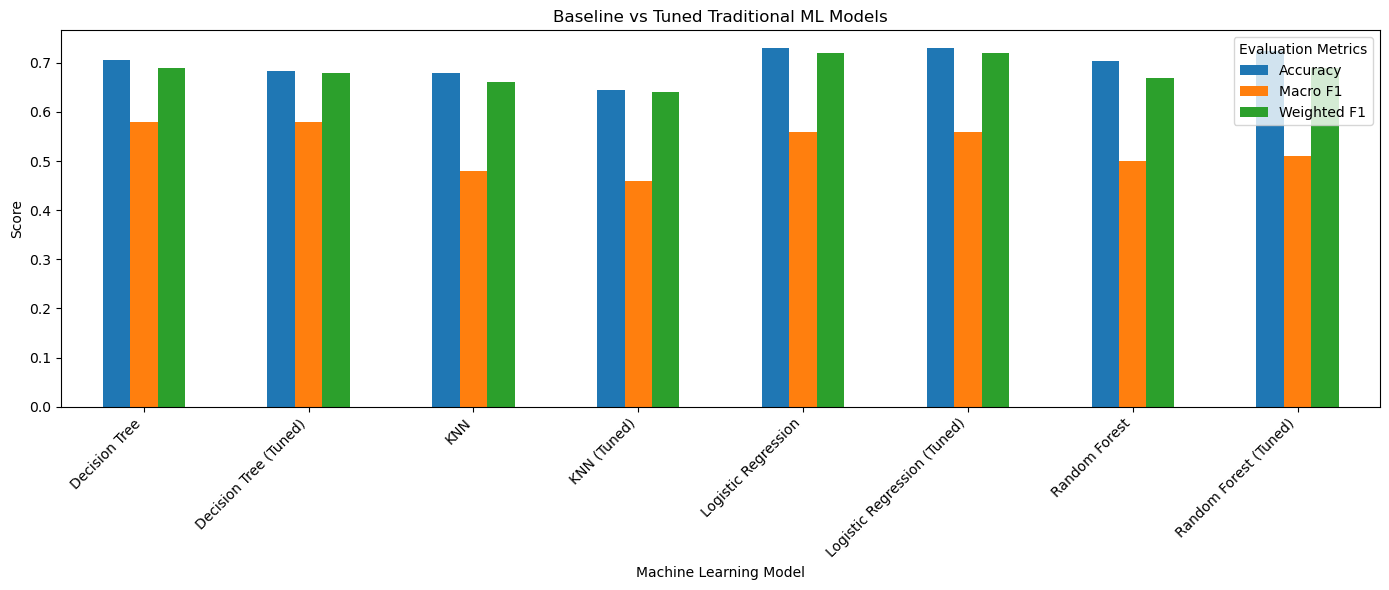

In [357]:
# 242. Plot comparison of traditional ML models
model_comparison.set_index("Model")[
    ["Accuracy", "Macro F1", "Weighted F1"]
].plot(
    kind="bar",
    figsize=(14, 6)
)

plt.title("Baseline vs Tuned Traditional ML Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

# Baseline vs Tuned Traditional Machine Learning Models

Four traditional machine learning algorithms were evaluated: Decision Tree, K-Nearest Neighbours (KNN), Logistic Regression and Random Forest.

Hyperparameter tuning was performed using GridSearchCV with five-fold StratifiedGroupKFold cross-validation. Macro F1-score was selected as the optimisation metric to give equal importance to all diagnostic categories.

The results showed that hyperparameter tuning did not consistently improve test performance.

| Model | Accuracy | Macro F1 | Weighted F1 |
|---|---:|---:|---:|
| Decision Tree | 0.7060 | 0.58 | 0.69 |
| Decision Tree (Tuned) | 0.6824 | 0.58 | 0.68 |
| KNN | 0.6798 | 0.48 | 0.66 |
| KNN (Tuned) | 0.6457 | 0.46 | 0.64 |
| Logistic Regression | 0.7297 | 0.56 | 0.72 |
| Logistic Regression (Tuned) | 0.7297 | 0.56 | 0.72 |
| Random Forest | 0.7034 | 0.50 | 0.67 |
| Random Forest (Tuned) | 0.7244 | 0.51 | 0.69 |

**Key observations:**

- Decision Tree achieved the highest macro F1-score of 0.58, indicating the strongest balance across the six diagnostic categories among these models.
- Logistic Regression achieved the highest accuracy (72.97%) and weighted F1-score (0.72).
- Random Forest showed improvement after tuning, with accuracy increasing from 70.34% to 72.44%.
- KNN performance decreased after tuning.
- Logistic Regression retained the same performance because the search selected its original effective hyperparameter configuration.

Overall, the results demonstrate that hyperparameter tuning does not guarantee improved performance on unseen data. Model evaluation should consider multiple metrics, particularly macro F1-score, because the diagnostic categories are imbalanced.

# STAGE 6 - Neural Network - Multi-Layer Perceptron (MLP)

In [359]:
# 243.. Initialise the MLP Classifier
mlp_model = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=42
)

In [360]:
# 244. Train the MLP Classifier
mlp_model.fit(X_train_scaled, y_train)

,hidden_layer_sizes,"(64, ...)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,500
,shuffle,True
,random_state,42


In [361]:
# 245. Make predictions using the MLP Classifier
y_pred_mlp = mlp_model.predict(X_test_scaled)

In [362]:
# 246. Evaluate MLP accuracy
accuracy_mlp = accuracy_score(y_test, y_pred_mlp)

print("MLP Accuracy:", accuracy_mlp)

MLP Accuracy: 0.6929133858267716


In [363]:
# 247. Generate classification report for MLP
print(classification_report(y_test, y_pred_mlp))

              precision    recall  f1-score   support

         ACK       0.78      0.84      0.81       125
         BCC       0.75      0.77      0.76       121
         MEL       0.60      0.30      0.40        10
         NEV       0.73      0.74      0.74        58
         SCC       0.13      0.15      0.14        20
         SEK       0.49      0.36      0.41        47

    accuracy                           0.69       381
   macro avg       0.58      0.53      0.54       381
weighted avg       0.69      0.69      0.69       381



### Confusion Matrix

In [364]:
# 248. Generate confusion matrix for MLP
from sklearn.metrics import confusion_matrix

cm_mlp = confusion_matrix(y_test, y_pred_mlp)

print(cm_mlp)

[[105   8   0   2   2   8]
 [ 11  93   2   2  11   2]
 [  0   1   3   2   4   0]
 [  1   7   0  43   1   6]
 [  4  10   0   1   3   2]
 [ 14   5   0   9   2  17]]


# MLP Confusion Matrix Analysis

The confusion matrix shows the number of correct and incorrect predictions made by the MLP classifier across the six diagnostic categories.

| Diagnosis | Correct Predictions | Total Records |
|---|---:|---:|
| ACK | 105 | 125 |
| BCC | 93 | 121 |
| MEL | 3 | 10 |
| NEV | 43 | 58 |
| SCC | 3 | 20 |
| SEK | 17 | 47 |

The model achieved its strongest classification results for ACK and NEV. However, it struggled with SCC, correctly identifying only 3 of 20 cases. Several SCC cases were misclassified as BCC.

MEL and SEK also showed relatively low classification performance. These results indicate that the model has difficulty distinguishing certain diagnostic categories using the available tabular features.

In [366]:
# 249. Get patient IDs for the training records
groups_train = groups.loc[X_train.index]

# Check the number of unique patients
print("Training records:", len(X_train))
print("Unique patients:", groups_train.nunique())

Training records: 1510
Unique patients: 1098


In [367]:
# 250. Define hyperparameter combinations for MLP
mlp_param_grid = {
    "hidden_layer_sizes": [
        (32,),
        (64, 32),
        (128, 64)
    ],
    "activation": ["relu", "tanh"],
    "alpha": [0.0001, 0.001, 0.01]
}

#### Configure Cross-validation

In [368]:
# 251. Configure 5-fold stratified group cross-validation
mlp_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

#### Configure GridSearchCV for MLP

In [369]:
# 252. Configure GridSearchCV for MLP
mlp_grid_search = GridSearchCV(
    estimator=MLPClassifier(
        solver="adam",
        max_iter=500,
        random_state=42
    ),
    param_grid=mlp_param_grid,
    scoring="f1_macro",
    cv=mlp_cv,
    n_jobs=-1,
    verbose=1
)

In [370]:
# 253. Run hyperparameter tuning using training data
mlp_grid_search.fit(
    X_train_scaled,
    y_train,
    groups=groups_train
)

Fitting 5 folds for each of 18 candidates, totalling 90 fits


C:\Users\97152\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


,estimator,MLPClassifier...ndom_state=42)
,param_grid,"{'activation': ['relu', 'tanh'], 'alpha': [0.0001, 0.001, ...], 'hidden_layer_sizes': [(32,), (64, ...), ...]}"
,scoring,'f1_macro'
,n_jobs,-1
,refit,True
,cv,StratifiedGro... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,hidden_layer_sizes,"(32,)"


In [371]:
# 254. Display the best MLP hyperparameters
print("Best Parameters:", mlp_grid_search.best_params_)

# Display the best cross-validation macro F1-score
print("Best Cross-Validation Macro F1:", mlp_grid_search.best_score_)

Best Parameters: {'activation': 'tanh', 'alpha': 0.001, 'hidden_layer_sizes': (32,)}
Best Cross-Validation Macro F1: 0.6104119891013453


In [372]:
# 255. Initialise the tuned MLP model
mlp_tuned = MLPClassifier(
    hidden_layer_sizes=(32,),
    activation="tanh",
    solver="adam",
    alpha=0.001,
    max_iter=1000,
    random_state=42
)

In [373]:
# 256. Train the tuned MLP model
mlp_tuned.fit(X_train_scaled, y_train)

C:\Users\97152\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,hidden_layer_sizes,"(32,)"
,activation,'tanh'
,solver,'adam'
,alpha,0.001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True
,random_state,42


In [374]:
# 257. Check MLP training progress
print("Iterations completed:", mlp_tuned.n_iter_)
print("Final training loss:", mlp_tuned.loss_)

Iterations completed: 1000
Final training loss: 0.08944334645692906


In [375]:
# 258. Make predictions using the tuned MLP model
y_pred_mlp_tuned = mlp_tuned.predict(X_test_scaled)

In [376]:
# 259. Evaluate tuned MLP accuracy
accuracy_mlp_tuned = accuracy_score(y_test, y_pred_mlp_tuned)

print("Original MLP Accuracy:", accuracy_mlp)
print("Tuned MLP Accuracy:", accuracy_mlp_tuned)

Original MLP Accuracy: 0.6929133858267716
Tuned MLP Accuracy: 0.6850393700787402


In [377]:
# 260. Generate classification report for tuned MLP
print(classification_report(y_test, y_pred_mlp_tuned))

              precision    recall  f1-score   support

         ACK       0.77      0.79      0.78       125
         BCC       0.73      0.79      0.76       121
         MEL       0.40      0.20      0.27        10
         NEV       0.73      0.71      0.72        58
         SCC       0.12      0.15      0.14        20
         SEK       0.55      0.45      0.49        47

    accuracy                           0.69       381
   macro avg       0.55      0.51      0.53       381
weighted avg       0.68      0.69      0.68       381



# MLP Hyperparameter Tuning Results

Hyperparameter tuning was performed using GridSearchCV with five-fold StratifiedGroupKFold cross-validation. Macro F1-score was used as the optimisation metric to give equal importance to all diagnostic categories.

The best configuration was:

| Hyperparameter | Selected Value |
|---|---|
| Hidden layers | (32,) |
| Activation | tanh |
| Alpha | 0.001 |
| Solver | adam |
| Maximum iterations | 1000 |

The best cross-validation macro F1-score was 0.6104.

However, the tuned model achieved a test accuracy of 68.50%, compared with 69.29% for the original MLP.

| Metric | Original MLP | Tuned MLP |
|---|---:|---:|
| Accuracy | 0.69 | 0.69 |
| Macro Precision | 0.58 | 0.55 |
| Macro Recall | 0.53 | 0.51 |
| Macro F1-score | 0.54 | 0.53 |
| Weighted F1-score | 0.69 | 0.68 |

The original MLP performed slightly better across all overall test metrics. Although the tuned model improved the F1-score for SEK, it performed worse for ACK, MEL and NEV.

Therefore, hyperparameter tuning did not improve the overall test performance in this experiment. The original MLP was retained as the better-performing configuration.

The tuned model also reached its maximum iteration limit without convergence, which should be considered when interpreting its results.

### Confusion Matrix

In [379]:
# 261. Generate confusion matrix for tuned MLP
cm_mlp_tuned = confusion_matrix(y_test, y_pred_mlp_tuned)

print(cm_mlp_tuned)

[[99  8  0  2  8  8]
 [11 95  1  1 11  2]
 [ 1  2  2  4  1  0]
 [ 0  9  0 41  1  7]
 [ 3 12  2  0  3  0]
 [14  4  0  8  0 21]]


# Tuned MLP Confusion Matrix Analysis

The confusion matrix shows that the tuned MLP correctly classified 261 out of 381 test records.

The model performed best for ACK and BCC, correctly identifying 79.2% and 78.5% of these cases respectively. NEV achieved a recall of 70.7%.

However, performance was weaker for the less represented categories. MEL achieved 20% recall, while SCC achieved only 15%. SEK achieved 44.7% recall.

Compared with the original MLP, the tuned model improved SEK recall but performed slightly worse for ACK and NEV. Overall, hyperparameter tuning did not improve the model's test performance.

These results highlight the difficulty of classifying underrepresented diagnostic categories in this dataset.

# Stage 7 – Model Evaluation and Comparison

In [381]:
# 262. Create baseline model comparison

baseline_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "KNN",
        "Logistic Regression",
        "Random Forest",
        "MLP"
    ],
    "Accuracy": [
        0.7060, 0.6798, 0.7297, 0.7034, 0.6929
    ],
    "Macro F1": [
        0.58, 0.48, 0.56, 0.50, 0.54
    ],
    "Weighted F1": [
        0.69, 0.66, 0.72, 0.67, 0.69
    ]
})

display(baseline_comparison)

,Model,Accuracy,Macro F1,Weighted F1
0,Decision Tree,0.7060,0.58,0.69
1,KNN,0.6798,0.48,0.66
2,Logistic Regression,0.7297,0.56,0.72
3,Random Forest,0.7034,0.50,0.67
4,MLP,0.6929,0.54,0.69


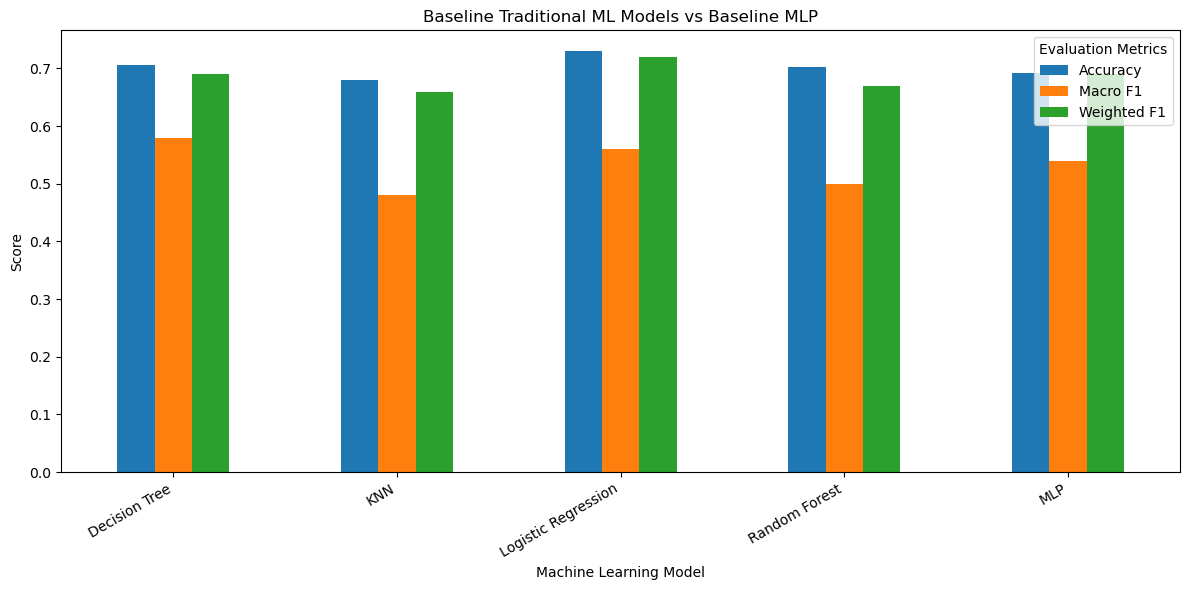

In [382]:
# 263. Plot baseline model performance
baseline_comparison.set_index("Model")[
    ["Accuracy", "Macro F1", "Weighted F1"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Baseline Traditional ML Models vs Baseline MLP")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

# Baseline Traditional ML Models vs Baseline MLP

The four baseline traditional machine learning algorithms were compared with the baseline Multi-Layer Perceptron (MLP) neural network.

The Logistic Regression model achieved the highest accuracy of 72.97% and weighted F1-score of 0.72. The Decision Tree achieved the highest macro F1-score of 0.58, indicating better balance across the six diagnostic categories.

The baseline MLP achieved an accuracy of 69.29%, macro F1-score of 0.54 and weighted F1-score of 0.69.

Although the MLP performed competitively, it did not outperform the strongest traditional machine learning models in this experiment. Its macro F1-score was higher than those of KNN and Random Forest but lower than those of Decision Tree and Logistic Regression.

Overall, the baseline comparison suggests that traditional machine learning algorithms performed better than the MLP on this tabular dataset.

### Tuned Model Comparison Table

In [384]:
# 264. Compare tuned traditional ML models with tuned MLP

tuned_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree (Tuned)",
        "KNN (Tuned)",
        "Logistic Regression (Tuned)",
        "Random Forest (Tuned)",
        "MLP (Tuned)"
    ],
    "Accuracy": [
        0.6824,
        0.6457,
        0.7297,
        0.7244,
        0.6850
    ],
    "Macro F1": [
        0.58,
        0.46,
        0.56,
        0.51,
        0.53
    ],
    "Weighted F1": [
        0.68,
        0.64,
        0.72,
        0.69,
        0.68
    ]
})

display(tuned_comparison)

,Model,Accuracy,Macro F1,Weighted F1
0,Decision Tree (Tuned),0.6824,0.58,0.68
1,KNN (Tuned),0.6457,0.46,0.64
2,Logistic Regression (Tuned),0.7297,0.56,0.72
3,Random Forest (Tuned),0.7244,0.51,0.69
4,MLP (Tuned),0.6850,0.53,0.68


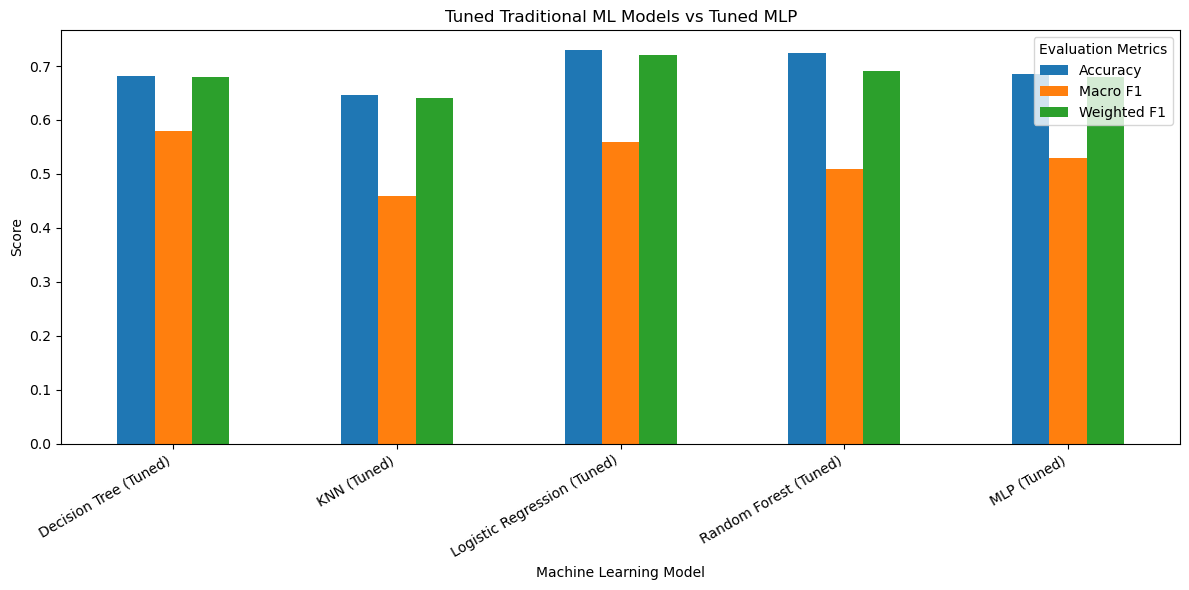

In [385]:
# 265. Plot tuned model performance
tuned_comparison.set_index("Model")[
    ["Accuracy", "Macro F1", "Weighted F1"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Tuned Traditional ML Models vs Tuned MLP")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

# Tuned Traditional ML Models vs Tuned MLP

The four tuned traditional machine learning models were compared with the tuned Multi-Layer Perceptron (MLP) neural network.

The tuned Logistic Regression model achieved the highest accuracy of 72.97% and weighted F1-score of 0.72. The tuned Decision Tree achieved the highest macro F1-score of 0.58, indicating the strongest balance across the six diagnostic categories.

The tuned MLP achieved an accuracy of 68.50%, macro F1-score of 0.53 and weighted F1-score of 0.68. It performed better than tuned KNN and tuned Random Forest in macro F1-score, but did not outperform the tuned Decision Tree or Logistic Regression.

The tuned Random Forest achieved an accuracy of 72.44%, making it competitive with Logistic Regression. However, its macro F1-score remained lower at 0.51.

Overall, hyperparameter tuning did not make the MLP the best-performing model. Traditional machine learning, particularly Logistic Regression and Decision Tree, produced stronger results on this tabular dataset.

### Overall Model Comparison

In [387]:
# 266. Create overall model comparison

overall_comparison = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Decision Tree (Tuned)",
        "KNN",
        "KNN (Tuned)",
        "Logistic Regression",
        "Logistic Regression (Tuned)",
        "Random Forest",
        "Random Forest (Tuned)",
        "MLP",
        "MLP (Tuned)"
    ],
    "Accuracy": [
        0.7060, 0.6824,
        0.6798, 0.6457,
        0.7297, 0.7297,
        0.7034, 0.7244,
        0.6929, 0.6850
    ],
    "Macro F1": [
        0.58, 0.58,
        0.48, 0.46,
        0.56, 0.56,
        0.50, 0.51,
        0.54, 0.53
    ],
    "Weighted F1": [
        0.69, 0.68,
        0.66, 0.64,
        0.72, 0.72,
        0.67, 0.69,
        0.69, 0.68
    ]
})

display(overall_comparison)

,Model,Accuracy,Macro F1,Weighted F1
0,Decision Tree,0.7060,0.58,0.69
1,Decision Tree (Tuned),0.6824,0.58,0.68
2,KNN,0.6798,0.48,0.66
3,KNN (Tuned),0.6457,0.46,0.64
4,Logistic Regression,0.7297,0.56,0.72
5,Logistic Regression (Tuned),0.7297,0.56,0.72
6,Random Forest,0.7034,0.50,0.67
7,Random Forest (Tuned),0.7244,0.51,0.69
8,MLP,0.6929,0.54,0.69
9,MLP (Tuned),0.6850,0.53,0.68


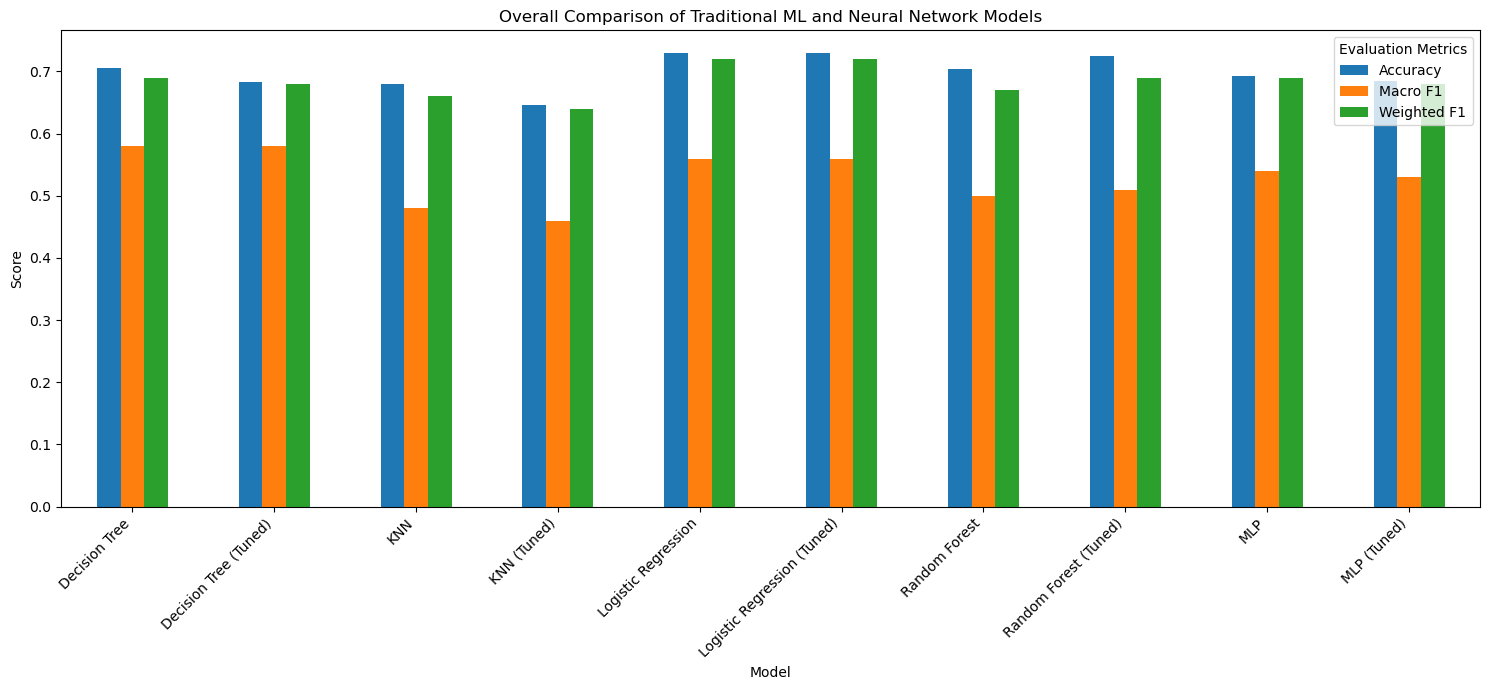

In [388]:
# 267. Plot overall model comparison
overall_comparison.set_index("Model")[
    ["Accuracy", "Macro F1", "Weighted F1"]
].plot(
    kind="bar",
    figsize=(15, 7)
)

plt.title("Overall Comparison of Traditional ML and Neural Network Models")
plt.xlabel("Model")
plt.ylabel("Score")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

# Final Model Selection

| Evaluation criterion | Selected model | Score |
|---|---|---:|
| Highest accuracy | Logistic Regression | 72.97% |
| Highest macro F1-score | Decision Tree | 0.58 |
| Highest weighted F1-score | Logistic Regression | 0.72 |

| Model | Main strength | Main limitation |
|---|---|---|
| Logistic Regression | Highest overall accuracy and weighted F1 | Lower macro F1 than Decision Tree |
| Decision Tree | Best balance across diagnostic categories | Lower accuracy than Logistic Regression |

Both models were retained as the strongest candidates for final evaluation. Logistic Regression performed best on overall accuracy, while Decision Tree achieved the highest macro F1-score.

### Why Were Both Models Retained?

Both Logistic Regression and Decision Tree were retained because they demonstrated different strengths across the evaluation metrics.

Logistic Regression achieved the highest accuracy (72.97%) and weighted F1-score (0.72), making it the strongest model in terms of overall predictive performance.

Decision Tree achieved the highest macro F1-score (0.58). Since macro F1 calculates the average F1-score across all six diagnostic categories with equal weight, it provides a more balanced assessment when working with an imbalanced dataset.

Therefore, selecting only the model with the highest accuracy could overlook differences in performance across minority diagnostic categories. Retaining both models allows their strengths to be considered under different evaluation priorities.

The final selection should also consider individual class performance, particularly for MEL and SCC, where classification remains challenging. Neither model should be considered clinically suitable based on these experimental results alone.

# Model Trade-offs and Final Selection

The model comparison demonstrates that higher overall accuracy does not necessarily indicate better performance across every diagnostic category.

Logistic Regression provided the strongest overall results, achieving 72.97% accuracy and a weighted F1-score of 0.72. However, its macro F1-score of 0.56 was lower than the Decision Tree's score of 0.58.

The Decision Tree achieved a slightly lower accuracy of 70.60%, but its higher macro F1-score suggests a better balance across the six diagnostic categories.

Other models presented different trade-offs. Random Forest improved following hyperparameter tuning, reaching 72.44% accuracy, although its macro F1-score remained at 0.51. KNN experienced a decline after tuning, while the MLP did not outperform the leading traditional models.

Therefore, Logistic Regression was retained as the strongest model for overall predictive performance, while Decision Tree was retained as the strongest candidate for balanced classification performance. This comparison demonstrates why multiple evaluation metrics are necessary when assessing models on an imbalanced multiclass dataset.

### Class Level Performance

In [391]:
# 268. Compare class-level performance of the two leading models

class_comparison = pd.DataFrame({
    "Diagnostic": ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"],

    "DT Precision": [0.75, 0.71, 0.54, 0.75, 0.18, 0.69],
    "DT Recall":    [0.82, 0.82, 0.70, 0.71, 0.10, 0.38],
    "DT F1":        [0.78, 0.76, 0.61, 0.73, 0.13, 0.49],

    "LR Precision": [0.77, 0.76, 0.40, 0.79, 0.20, 0.62],
    "LR Recall":    [0.86, 0.83, 0.20, 0.72, 0.15, 0.49],
    "LR F1":        [0.82, 0.79, 0.27, 0.76, 0.17, 0.55]
})

display(class_comparison)

,Diagnostic,DT Precision,DT Recall,DT F1,LR Precision,LR Recall,LR F1
0,ACK,0.75,0.82,0.78,0.77,0.86,0.82
1,BCC,0.71,0.82,0.76,0.76,0.83,0.79
2,MEL,0.54,0.70,0.61,0.40,0.20,0.27
3,NEV,0.75,0.71,0.73,0.79,0.72,0.76
4,SCC,0.18,0.10,0.13,0.20,0.15,0.17
5,SEK,0.69,0.38,0.49,0.62,0.49,0.55


| Diagnostic | Better-performing model | Comparison |
|---|---|---|
| ACK | Logistic Regression | Higher F1 (0.82 vs 0.78) and recall (0.86 vs 0.82) |
| BCC | Logistic Regression | Higher F1 (0.79 vs 0.76) and recall (0.83 vs 0.82) |
| MEL | Decision Tree | Higher F1 (0.61 vs 0.27) and recall (0.70 vs 0.20) |
| NEV | Logistic Regression | Higher F1 (0.76 vs 0.73) |
| SCC | Logistic Regression | Slightly higher F1 (0.17 vs 0.13) and recall (0.15 vs 0.10) |
| SEK | Logistic Regression | Higher F1 (0.55 vs 0.49) and recall (0.49 vs 0.38) |

**Explanation of Findings**

- **Logistic Regression:** Performed better across five of the six diagnostic categories. It was particularly effective for ACK, BCC, NEV and SEK.
- **Decision Tree:** Performed considerably better for MEL, achieving 70% recall compared with 20% for Logistic Regression. This means it identified more of the actual MEL cases in the test set.
- **SCC:** Both models performed poorly, with recall scores of 10% and 15%, respectively. Neither model identified a satisfactory proportion of actual SCC cases.

**Overall Interpretation**

Logistic Regression demonstrated stronger class-level performance across most diagnostic categories. However, Decision Tree showed a substantial advantage for MEL.

This demonstrates that the model with the highest overall accuracy is not necessarily the best model for every diagnostic category. Both models were therefore retained for further consideration.

**Limitation:** MEL and SCC had only 10 and 20 actual cases respectively in the test set. Their performance scores should therefore be interpreted cautiously, as a small number of predictions can substantially affect the results.

### Compare the tuned models at class level

In [393]:
# 269. Compare class-level performance of tuned models

tuned_class_comparison = pd.DataFrame({
    "Diagnostic": ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"],

    "DT Tuned Precision": [0.72, 0.71, 0.80, 0.75, 0.17, 0.68],
    "DT Tuned Recall":    [0.83, 0.74, 0.40, 0.62, 0.20, 0.49],
    "DT Tuned F1":        [0.77, 0.72, 0.53, 0.68, 0.18, 0.57],

    "LR Tuned Precision": [0.77, 0.76, 0.40, 0.79, 0.20, 0.62],
    "LR Tuned Recall":    [0.86, 0.83, 0.20, 0.72, 0.15, 0.49],
    "LR Tuned F1":        [0.82, 0.79, 0.27, 0.76, 0.17, 0.55]
})

display(tuned_class_comparison)

,Diagnostic,DT Tuned Precision,DT Tuned Recall,DT Tuned F1,LR Tuned Precision,LR Tuned Recall,LR Tuned F1
0,ACK,0.72,0.83,0.77,0.77,0.86,0.82
1,BCC,0.71,0.74,0.72,0.76,0.83,0.79
2,MEL,0.80,0.40,0.53,0.40,0.20,0.27
3,NEV,0.75,0.62,0.68,0.79,0.72,0.76
4,SCC,0.17,0.20,0.18,0.20,0.15,0.17
5,SEK,0.68,0.49,0.57,0.62,0.49,0.55


# Class-Level Performance Comparison: Tuned Decision Tree vs Tuned Logistic Regression

| Diagnostic | Better-performing model | Comparison |
|---|---|---|
| ACK | Logistic Regression (Tuned) | Higher F1 (0.82 vs 0.77) and recall (0.86 vs 0.83) |
| BCC | Logistic Regression (Tuned) | Higher F1 (0.79 vs 0.72) and recall (0.83 vs 0.74) |
| MEL | Decision Tree (Tuned) | Higher F1 (0.53 vs 0.27) and precision (0.80 vs 0.40) |
| NEV | Logistic Regression (Tuned) | Higher F1 (0.76 vs 0.68) and recall (0.72 vs 0.62) |
| SCC | Decision Tree (Tuned) | Slightly higher F1 (0.18 vs 0.17) and recall (0.20 vs 0.15) |
| SEK | Decision Tree (Tuned) | Slightly higher F1 (0.57 vs 0.55) and equal recall (0.49) |

**Explanation of Findings**

- **Logistic Regression (Tuned):** Performed better for ACK, BCC and NEV. It maintained strong recall for ACK and BCC.
- **Decision Tree (Tuned):** Performed better for MEL, SCC and SEK. Its MEL precision of 0.80 indicates that most of its MEL predictions were correct, although its recall of 0.40 means it still missed 60% of actual MEL cases.
- **SCC:** Both models continued to struggle. The tuned Decision Tree showed a small improvement, but neither model achieved strong SCC classification performance.

**Overall Interpretation**

Hyperparameter tuning did not make one model consistently superior. Tuned Logistic Regression remained stronger for ACK, BCC and NEV, while tuned Decision Tree performed better for MEL, SCC and SEK.

The tuned Decision Tree also demonstrated a higher MEL precision and F1-score than its baseline version, although its MEL recall decreased from 0.70 to 0.40.

These findings demonstrate that hyperparameter tuning can change the balance between precision and recall without necessarily improving overall model performance.

### Compare all four models by diagnostic category

In [395]:
# 270. Compare class-level F1-scores across all four models

final_class_f1 = pd.DataFrame({
    "Diagnostic": ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"],

    "Decision Tree": [0.78, 0.76, 0.61, 0.73, 0.13, 0.49],
    "Decision Tree (Tuned)": [0.77, 0.72, 0.53, 0.68, 0.18, 0.57],

    "Logistic Regression": [0.82, 0.79, 0.27, 0.76, 0.17, 0.55],
    "Logistic Regression (Tuned)": [0.82, 0.79, 0.27, 0.76, 0.17, 0.55]
})

display(final_class_f1)

,Diagnostic,Decision Tree,Decision Tree (Tuned),Logistic Regression,Logistic Regression (Tuned)
0,ACK,0.78,0.77,0.82,0.82
1,BCC,0.76,0.72,0.79,0.79
2,MEL,0.61,0.53,0.27,0.27
3,NEV,0.73,0.68,0.76,0.76
4,SCC,0.13,0.18,0.17,0.17
5,SEK,0.49,0.57,0.55,0.55


# Comparison of Class-Level F1-Scores Across Four Models

| Diagnostic | Best-performing model | F1-score | Key observation |
|---|---|---:|---|
| ACK | Logistic Regression (Baseline and Tuned) | 0.82 | Strongest performance for ACK |
| BCC | Logistic Regression (Baseline and Tuned) | 0.79 | Strongest performance for BCC |
| MEL | Decision Tree (Baseline) | 0.61 | Considerably better than Logistic Regression |
| NEV | Logistic Regression (Baseline and Tuned) | 0.76 | Strongest performance for NEV |
| SCC | Decision Tree (Tuned) | 0.18 | Highest score, but performance remains poor |
| SEK | Decision Tree (Tuned) | 0.57 | Slightly better than the other configurations |

**Explanation of Findings**

- **Logistic Regression:** Achieved the highest F1-scores for ACK, BCC and NEV. Its performance remained unchanged after tuning.
- **Decision Tree:** Achieved the highest F1-score for MEL, demonstrating a substantial advantage over Logistic Regression for this category.
- **Tuned Decision Tree:** Improved the F1-scores for SCC and SEK compared with its baseline version, but its performance declined for ACK, BCC, MEL and NEV.
- **SCC:** All four configurations achieved F1-scores below 0.20, indicating that SCC classification remains a major challenge.

**Overall Interpretation**

No single configuration achieved the highest F1-score across all six diagnostic categories.

Logistic Regression performed consistently well for ACK, BCC and NEV, while Decision Tree configurations performed better for MEL, SCC and SEK.

The baseline Decision Tree achieved the highest MEL F1-score (0.61), whereas the tuned Decision Tree achieved the highest SCC and SEK F1-scores (0.18 and 0.57).

These findings demonstrate that model performance depends on the diagnostic category being classified. Therefore, final model selection should consider both overall metrics and individual class performance.

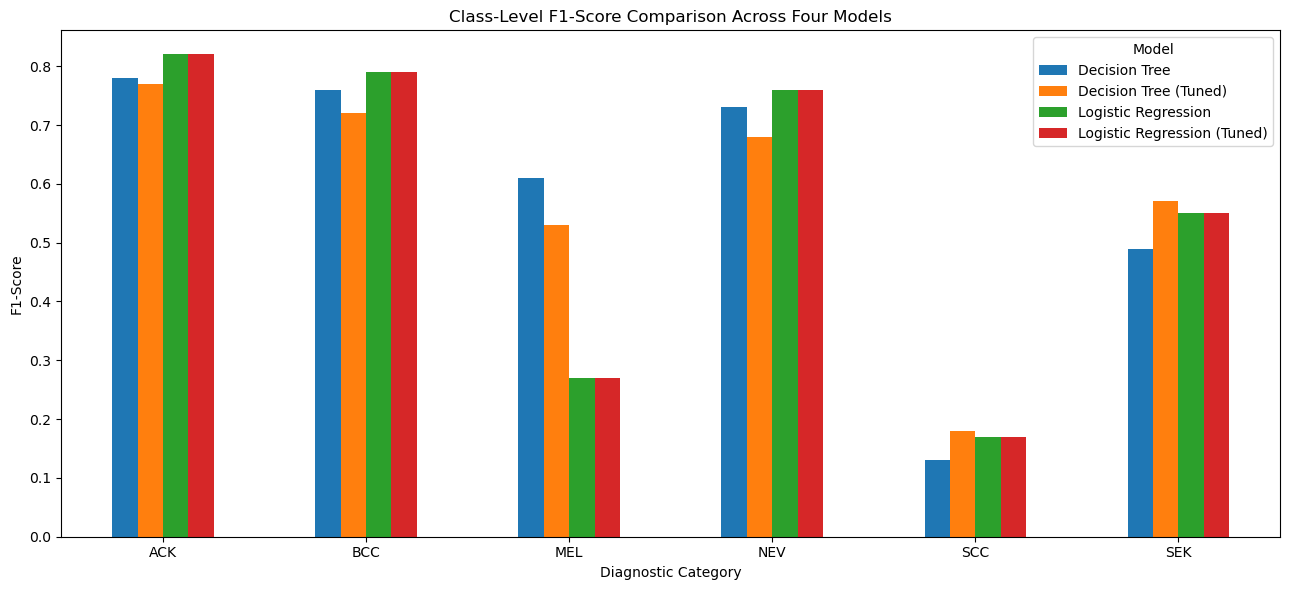

In [397]:
# 271. Plot class-level F1-score comparison

final_class_f1.set_index("Diagnostic").plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Class-Level F1-Score Comparison Across Four Models")
plt.xlabel("Diagnostic Category")
plt.ylabel("F1-Score")
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

### Final model selection and justification

# Final Model Selection and Justification

Logistic Regression and Decision Tree were selected as the two strongest candidate models based on their overall and class-level performance.

**Logistic Regression** was selected as the strongest model for overall predictive performance. It achieved the highest accuracy (72.97%) and weighted F1-score (0.72). It also achieved the highest class-level F1-scores for ACK, BCC and NEV.

**Decision Tree** was retained because it achieved the highest macro F1-score (0.58), indicating stronger average performance across the six diagnostic categories. Its baseline configuration also achieved the highest MEL F1-score (0.61), while its tuned configuration achieved the highest SCC and SEK F1-scores.

Although hyperparameter tuning improved some class-level results for Decision Tree, it did not improve its overall accuracy or macro F1-score. Logistic Regression also showed no measurable improvement following tuning.

Therefore, both algorithms were retained for comparison because they offer different performance advantages rather than one model consistently outperforming the other.

Important limitation
Neither model is suitable for clinical diagnosis based on these results. In particular, SCC classification remains weak, and the relatively small number of MEL and SCC cases in the test set limits confidence in their performance estimates.

# Stage 8: Model Evaluation, Performance Comparison and Error Analysis

In [427]:
# 8.1 DEFINE CLASS ORDER

classes = ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"]

# Convert actual test labels into binary format
# Required for multiclass ROC-AUC and Average Precision calculations

y_test_binary = label_binarize(y_test, classes=classes)


# 8.2 BASELINE MODEL PERFORMANCE COMPARISON

# Define baseline models and their corresponding test matrices

baseline_models = {
    "Logistic Regression": (lr_model, X_test_scaled),
    "Decision Tree": (dt_model, X_test_processed),
    "Random Forest": (rf_model, X_test_processed),
    "KNN": (knn_model, X_test_scaled),
    "MLP": (mlp_model, X_test_scaled)
}

# Create an empty list to store evaluation results

baseline_results = []

# Evaluate each baseline model

for name, (model, X_input) in baseline_models.items():

    # Generate predictions and predicted probabilities
    y_pred = model.predict(X_input)
    y_proba = model.predict_proba(X_input)

    # Align predicted probabilities with the defined class order
    proba_aligned = np.column_stack([
        y_proba[:, list(model.classes_).index(c)]
        for c in classes
    ])

    # Calculate performance metrics
    baseline_results.append({
        "Model": name,

        "Accuracy": accuracy_score(y_test, y_pred),

        "Balanced Accuracy": balanced_accuracy_score(
            y_test, y_pred
        ),

        "Macro F1": f1_score(
            y_test, y_pred, average="macro"
        ),

        "Weighted F1": f1_score(
            y_test, y_pred, average="weighted"
        ),

        "ROC-AUC (OVR)": roc_auc_score(
            y_test_binary, proba_aligned, average="macro"
        ),

        "Macro Average Precision": average_precision_score(
            y_test_binary, proba_aligned, average="macro"
        ),

        "SCC Recall": recall_score(
            y_test, y_pred,
            labels=["SCC"],
            average="macro",
            zero_division=0
        ),

        "MEL Recall": recall_score(
            y_test, y_pred,
            labels=["MEL"],
            average="macro",
            zero_division=0
        )
    })

# Convert results into a DataFrame

baseline_results_df = pd.DataFrame(baseline_results)

# Display results rounded to four decimal places

baseline_results_df.round(4)

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,ROC-AUC (OVR),Macro Average Precision,SCC Recall,MEL Recall
0,Logistic Regression,0.7297,0.5423,0.5585,0.7182,0.9076,0.6363,0.15,0.2
1,Decision Tree,0.7060,0.5873,0.5828,0.6914,0.8677,0.5534,0.10,0.7
2,Random Forest,0.7034,0.4858,0.5020,0.6738,0.9114,0.6445,0.00,0.2
3,KNN,0.6798,0.4664,0.4759,0.6595,0.7982,0.4898,0.15,0.0
4,MLP,0.6929,0.5269,0.5427,0.6870,0.8983,0.6317,0.15,0.3


In [428]:
# 8.3 HYPERPARAMETER-TUNED MODEL PERFORMANCE COMPARISON

# Define tuned models and their corresponding test matrices

tuned_models = {
    "Logistic Regression": (lr_tuned, X_test_scaled),
    "Decision Tree": (dt_tuned, X_test_processed),
    "Random Forest": (rf_tuned, X_test_processed),
    "KNN": (knn_tuned, X_test_scaled),
    "MLP": (mlp_tuned, X_test_scaled)
}

# Create an empty list to store tuned model results

tuned_results = []

# Evaluate each tuned model

for name, (model, X_input) in tuned_models.items():

    # Generate predictions and predicted probabilities
    y_pred = model.predict(X_input)
    y_proba = model.predict_proba(X_input)

    # Align predicted probabilities with the defined class order
    proba_aligned = np.column_stack([
        y_proba[:, list(model.classes_).index(c)]
        for c in classes
    ])

    # Calculate performance metrics
    tuned_results.append({
        "Model": name,

        "Accuracy": accuracy_score(y_test, y_pred),

        "Balanced Accuracy": balanced_accuracy_score(
            y_test, y_pred
        ),

        "Macro F1": f1_score(
            y_test, y_pred, average="macro"
        ),

        "Weighted F1": f1_score(
            y_test, y_pred, average="weighted"
        ),

        "ROC-AUC (OVR)": roc_auc_score(
            y_test_binary, proba_aligned, average="macro"
        ),

        "Macro Average Precision": average_precision_score(
            y_test_binary, proba_aligned, average="macro"
        ),

        "SCC Recall": recall_score(
            y_test, y_pred,
            labels=["SCC"],
            average="macro",
            zero_division=0
        ),

        "MEL Recall": recall_score(
            y_test, y_pred,
            labels=["MEL"],
            average="macro",
            zero_division=0
        )
    })

# Convert results into a DataFrame

tuned_results_df = pd.DataFrame(tuned_results)

# Display tuned model results

tuned_results_df.round(4)

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,ROC-AUC (OVR),Macro Average Precision,SCC Recall,MEL Recall
0,Logistic Regression,0.7297,0.5423,0.5585,0.7182,0.9076,0.6363,0.15,0.2
1,Decision Tree,0.6824,0.5463,0.5760,0.6796,0.8273,0.5647,0.20,0.4
2,Random Forest,0.7244,0.4950,0.5126,0.6948,0.9184,0.6513,0.05,0.1
3,KNN,0.6457,0.4505,0.4568,0.6363,0.7666,0.4599,0.20,0.0
4,MLP,0.6850,0.5135,0.5260,0.6818,0.8787,0.5836,0.15,0.2


In [429]:
# 8.4 CLASS WEIGHTING EXPERIMENT

# Apply balanced class weights to Logistic Regression

lr_weighted = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight="balanced"
)

lr_weighted.fit(X_train_scaled, y_train)


# Apply balanced class weights to Decision Tree

dt_weighted = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

dt_weighted.fit(X_train_processed, y_train)


# Apply balanced class weights to Random Forest

rf_weighted = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

rf_weighted.fit(X_train_processed, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [432]:
# Calculate sample weights based on class frequencies

mlp_sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Initialise MLP model

mlp_weighted = MLPClassifier(
    max_iter=1000,
    random_state=42
)

# Train MLP using sample weights

mlp_weighted.fit(
    X_train_scaled,
    y_train,
    sample_weight=mlp_sample_weights
)

,hidden_layer_sizes,"(100,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True
,random_state,42


In [434]:
# Evaluate class-weighted and sample-weighted models

weighted_models = {
    "Class-Weighted Logistic Regression": (lr_weighted, X_test_scaled),
    "Class-Weighted Decision Tree": (dt_weighted, X_test_processed),
    "Class-Weighted Random Forest": (rf_weighted, X_test_processed),
    "Sample-Weighted MLP": (mlp_weighted, X_test_scaled)
}

weighted_results = []

for name, (model, X_input) in weighted_models.items():

    y_pred = model.predict(X_input)
    y_proba = model.predict_proba(X_input)

    proba_aligned = np.column_stack([
        y_proba[:, list(model.classes_).index(c)]
        for c in classes
    ])

    weighted_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(y_test, y_pred, average="macro"),
        "Weighted F1": f1_score(y_test, y_pred, average="weighted"),
        "ROC-AUC (OVR)": roc_auc_score(
            y_test_binary, proba_aligned, average="macro"
        ),
        "Macro Average Precision": average_precision_score(
            y_test_binary, proba_aligned, average="macro"
        ),
        "SCC Recall": recall_score(
            y_test, y_pred, labels=["SCC"],
            average="macro", zero_division=0
        ),
        "MEL Recall": recall_score(
            y_test, y_pred, labels=["MEL"],
            average="macro", zero_division=0
        )
    })

weighted_results_df = pd.DataFrame(weighted_results)

weighted_results_df.round(4)

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,ROC-AUC (OVR),Macro Average Precision,SCC Recall,MEL Recall
0,Class-Weighted Logistic Regression,0.6798,0.5886,0.5715,0.7054,0.8993,0.6254,0.25,0.5
1,Class-Weighted Decision Tree,0.6273,0.4861,0.4928,0.6245,0.7032,0.3511,0.15,0.3
2,Class-Weighted Random Forest,0.6745,0.4558,0.4637,0.6458,0.8971,0.6241,0.00,0.1
3,Sample-Weighted MLP,0.6798,0.5702,0.5754,0.6836,0.8891,0.6224,0.20,0.5


Class weighting and sample weighting were investigated to determine whether assigning greater importance to underrepresented classes could improve classification performance.

Class-weighted Logistic Regression achieved a balanced accuracy of 58.86%, compared with 54.23% for its baseline model. Its MEL recall also increased from 20% to 50%, while SCC recall increased from 15% to 25%. However, overall accuracy decreased from 72.97% to 67.98%.

The sample-weighted MLP achieved a Macro F1-score of 57.54%, compared with 54.27% for the baseline MLP. Its MEL recall increased from 30% to 50%, although its overall accuracy decreased from 69.29% to 67.98%.

The results indicate that weighting techniques improved certain aspects of minority-class detection, but did not consistently improve overall model performance.

### SMOTE-Based Oversampling

To further investigate the effect of class imbalance on classification performance, the Synthetic Minority Over-sampling Technique (SMOTE) was applied to the training dataset.

SMOTE generates synthetic observations for minority classes by interpolating between existing minority-class samples. This increases the representation of underrepresented classes and produces a more balanced training dataset.

The technique was applied separately to the processed and scaled training datasets to accommodate the input requirements of the five classification models. The number of nearest neighbours was set to 3, with a random state of 42 to ensure reproducibility.

Oversampling was restricted to the training data, while the original test dataset remained unchanged. This ensured that model performance was evaluated using the original class distribution rather than an artificially balanced test set.

The five tuned classification models were subsequently fitted using the oversampled training data and evaluated against the unchanged test dataset.

In [437]:
# Apply SMOTE to the scaled training data
smote = SMOTE(random_state=42, k_neighbors=3)

X_train_scaled_smote, y_train_smote = smote.fit_resample(
    X_train_scaled, y_train
)

# Apply SMOTE to the processed training data
X_train_processed_smote, y_train_processed_smote = smote.fit_resample(
    X_train_processed, y_train
)

# Check the class distribution after oversampling
print(y_train_smote.value_counts())

# Create copies of the tuned models
lr_smote = clone(lr_tuned)
dt_smote = clone(dt_tuned)
rf_smote = clone(rf_tuned)
knn_smote = clone(knn_tuned)
mlp_smote = clone(mlp_tuned)

# Train Logistic Regression using scaled SMOTE data
lr_smote.fit(X_train_scaled_smote, y_train_smote)

# Train Decision Tree using processed SMOTE data
dt_smote.fit(X_train_processed_smote, y_train_processed_smote)

# Train Random Forest using processed SMOTE data
rf_smote.fit(X_train_processed_smote, y_train_processed_smote)

# Train KNN using scaled SMOTE data
knn_smote.fit(X_train_scaled_smote, y_train_smote)

# Train MLP using scaled SMOTE data
mlp_smote.fit(X_train_scaled_smote, y_train_smote)

diagnostic
NEV    531
ACK    531
BCC    531
SEK    531
SCC    531
MEL    531
Name: count, dtype: int64


,hidden_layer_sizes,"(32,)"
,activation,'tanh'
,solver,'adam'
,alpha,0.001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True
,random_state,42


Following SMOTE-based oversampling, all five tuned classification models were evaluated using the original held-out test dataset. Multiple evaluation metrics were considered to assess overall predictive performance and the models' ability to identify minority classes.

The results indicate that the effect of SMOTE varied across the classification models. Logistic Regression achieved a macro F1-score of 0.5738 and a balanced accuracy of 0.5809, showing improvements over its baseline performance. Random Forest also demonstrated improvements, achieving a macro F1-score of 0.5574 compared with 0.5020 in the baseline experiment.

KNN achieved a higher SCC recall of 0.40 following oversampling, compared with 0.15 in its baseline experiment. However, its overall macro F1-score decreased from 0.4759 to 0.4617.

Decision Tree performance declined following SMOTE, with its macro F1-score decreasing from 0.5828 to 0.5244. Similarly, MLP showed little overall improvement, with its macro F1-score changing from 0.5427 to 0.5400.

These findings suggest that SMOTE did not improve every model equally. Its effectiveness depended on the classification algorithm and the evaluation metric considered.

In [438]:
# 8.5.5 COMPARE SMOTE MODEL PERFORMANCE

# Create a DataFrame containing the SMOTE evaluation results
smote_results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "MLP"
    ],
    "Accuracy": [0.6903, 0.6667, 0.7165, 0.5512, 0.6903],
    "Balanced Accuracy": [0.5809, 0.5129, 0.5328, 0.4979, 0.5344],
    "Macro F1": [0.5738, 0.5244, 0.5574, 0.4617, 0.5400],
    "Weighted F1": [0.7117, 0.6362, 0.7052, 0.5806, 0.6836],
    "ROC-AUC": [0.8973, 0.7855, 0.9123, 0.7557, 0.8761],
    "Macro AP": [0.6238, 0.4824, 0.6362, 0.4134, 0.6224],
    "SCC Recall": [0.25, 0.10, 0.15, 0.40, 0.20],
    "MEL Recall": [0.40, 0.30, 0.20, 0.30, 0.20]
})

# Display the SMOTE results
smote_results_df

,Model,Accuracy,Balanced Accuracy,Macro F1,Weighted F1,ROC-AUC,Macro AP,SCC Recall,MEL Recall
0,Logistic Regression,0.6903,0.5809,0.5738,0.7117,0.8973,0.6238,0.25,0.4
1,Decision Tree,0.6667,0.5129,0.5244,0.6362,0.7855,0.4824,0.10,0.3
2,Random Forest,0.7165,0.5328,0.5574,0.7052,0.9123,0.6362,0.15,0.2
3,KNN,0.5512,0.4979,0.4617,0.5806,0.7557,0.4134,0.40,0.3
4,MLP,0.6903,0.5344,0.5400,0.6836,0.8761,0.6224,0.20,0.2


To further assess the effectiveness of SMOTE, its results were compared with the baseline and class-weighted experiments. This comparison was conducted using balanced accuracy, macro F1-score, SCC recall and MEL recall to evaluate both overall classification performance and minority-class detection.

The results demonstrate that SMOTE produced different outcomes across the classification algorithms. Logistic Regression showed improvements in macro F1-score compared with both its baseline and class-weighted configurations. Random Forest also achieved a higher macro F1-score following SMOTE than in the baseline and class-weighted experiments.

However, SMOTE did not consistently outperform class weighting. For example, class-weighted Logistic Regression achieved a slightly higher balanced accuracy than its SMOTE counterpart. Similarly, sample-weighted MLP achieved better macro F1-score and MEL recall than the SMOTE-trained MLP.

These findings indicate that the effectiveness of imbalance-handling techniques is model-dependent. Neither class weighting nor synthetic oversampling consistently improved all evaluation metrics.

In [440]:
# 8.5.6 COMPARE IMBALANCE-HANDLING TECHNIQUES

comparison_data = {
    "Model": ["Logistic Regression", "Decision Tree",
              "Random Forest", "MLP"],

    "Baseline Macro F1": [0.5585, 0.5828, 0.5020, 0.5427],
    "Weighted Macro F1": [0.5715, 0.4928, 0.4637, 0.5754],
    "SMOTE Macro F1": [0.5738, 0.5244, 0.5574, 0.5400],

    "Baseline Balanced Accuracy": [0.5423, 0.5873, 0.4858, 0.5269],
    "Weighted Balanced Accuracy": [0.5886, 0.4861, 0.4558, 0.5702],
    "SMOTE Balanced Accuracy": [0.5809, 0.5129, 0.5328, 0.5344]
}

imbalance_comparison_df = pd.DataFrame(comparison_data)

imbalance_comparison_df

,Model,Baseline Macro F1,Weighted Macro F1,SMOTE Macro F1,Baseline Balanced Accuracy,Weighted Balanced Accuracy,SMOTE Balanced Accuracy
0,Logistic Regression,0.5585,0.5715,0.5738,0.5423,0.5886,0.5809
1,Decision Tree,0.5828,0.4928,0.5244,0.5873,0.4861,0.5129
2,Random Forest,0.5020,0.4637,0.5574,0.4858,0.4558,0.5328
3,MLP,0.5427,0.5754,0.5400,0.5269,0.5702,0.5344


## Classification Report Analysis

Classification reports were generated to examine the predictive performance of the selected models across the six diagnostic categories: ACK, BCC, MEL, NEV, SCC and SEK.

Precision measures the proportion of observations predicted as a particular class that were correctly classified, whereas recall measures the proportion of actual observations belonging to that class that were correctly identified. The F1-score provides a harmonic mean of precision and recall, offering a combined measure of classification performance.

Particular attention was given to MEL and SCC because these classes had relatively few observations in the training and test datasets. Examining class-specific performance provides further insight into the models' ability to identify underrepresented categories, which may not be fully reflected by overall accuracy.

In [442]:
# Define the selected models and their corresponding test datasets
selected_models = {
    "Baseline Logistic Regression": (lr_model, X_test_scaled),
    "Class-Weighted Logistic Regression": (lr_weighted, X_test_scaled),
    "SMOTE Logistic Regression": (lr_smote, X_test_scaled),
    "Baseline Decision Tree": (dt_model, X_test_processed),
    "Sample-Weighted MLP": (mlp_weighted, X_test_scaled),
    "SMOTE Random Forest": (rf_smote, X_test_processed)
}

# Generate classification reports for each selected model
for model_name, (model, X_test_input) in selected_models.items():

    y_pred = model.predict(X_test_input)

    print(f"\n{model_name}")
    print(classification_report(
        y_test,
        y_pred,
        labels=classes,
        zero_division=0
    ))


Baseline Logistic Regression
              precision    recall  f1-score   support

         ACK       0.77      0.86      0.82       125
         BCC       0.76      0.83      0.79       121
         MEL       0.40      0.20      0.27        10
         NEV       0.79      0.72      0.76        58
         SCC       0.20      0.15      0.17        20
         SEK       0.62      0.49      0.55        47

    accuracy                           0.73       381
   macro avg       0.59      0.54      0.56       381
weighted avg       0.71      0.73      0.72       381


Class-Weighted Logistic Regression
              precision    recall  f1-score   support

         ACK       0.85      0.80      0.82       125
         BCC       0.83      0.64      0.73       121
         MEL       0.33      0.50      0.40        10
         NEV       0.80      0.74      0.77        58
         SCC       0.10      0.25      0.15        20
         SEK       0.54      0.60      0.57        47

    accurac

The classification reports revealed differences in the ability of the selected models to identify individual diagnostic categories.

The baseline Decision Tree achieved the highest MEL recall of 0.70 and an F1-score of 0.6087, correctly identifying seven out of ten MEL observations. The sample-weighted MLP achieved the second-highest MEL F1-score of 0.5263, with a recall of 0.50.

For SCC, class-weighted and SMOTE Logistic Regression both achieved a recall of 0.25, correctly identifying five out of twenty observations. The sample-weighted MLP achieved an SCC recall of 0.20.

Despite improvements in recall for certain minority classes, precision remained relatively low, particularly for SCC. This indicates that increasing the detection of minority-class observations also resulted in a greater number of incorrect class predictions.

Overall, the results demonstrate that model performance varied considerably across diagnostic categories. The baseline Decision Tree was particularly effective for MEL detection, while the Logistic Regression models demonstrated comparatively stronger SCC recall than the baseline Decision Tree.

In [443]:
# Store classification reports for the selected models
classification_reports = {}

for model_name, (model, X_test_input) in selected_models.items():

    y_pred = model.predict(X_test_input)

    classification_reports[model_name] = classification_report(
        y_test,
        y_pred,
        labels=classes,
        output_dict=True,
        zero_division=0
    )

# Display the stored classification reports
classification_reports

{'Baseline Logistic Regression': {'ACK': {'precision': 0.7714285714285715,
   'recall': 0.864,
   'f1-score': 0.8150943396226416,
   'support': 125.0},
  'BCC': {'precision': 0.7633587786259542,
   'recall': 0.8264462809917356,
   'f1-score': 0.7936507936507936,
   'support': 121.0},
  'MEL': {'precision': 0.4,
   'recall': 0.2,
   'f1-score': 0.26666666666666666,
   'support': 10.0},
  'NEV': {'precision': 0.7924528301886793,
   'recall': 0.7241379310344828,
   'f1-score': 0.7567567567567568,
   'support': 58.0},
  'SCC': {'precision': 0.2,
   'recall': 0.15,
   'f1-score': 0.17142857142857143,
   'support': 20.0},
  'SEK': {'precision': 0.6216216216216216,
   'recall': 0.48936170212765956,
   'f1-score': 0.5476190476190477,
   'support': 47.0},
  'accuracy': 0.7296587926509186,
  'macro avg': {'precision': 0.5914769669774712,
   'recall': 0.5423243190256463,
   'f1-score': 0.5585360292907463,
   'support': 381.0},
  'weighted avg': {'precision': 0.7138411128857518,
   'recall': 0.729


Baseline Logistic Regression


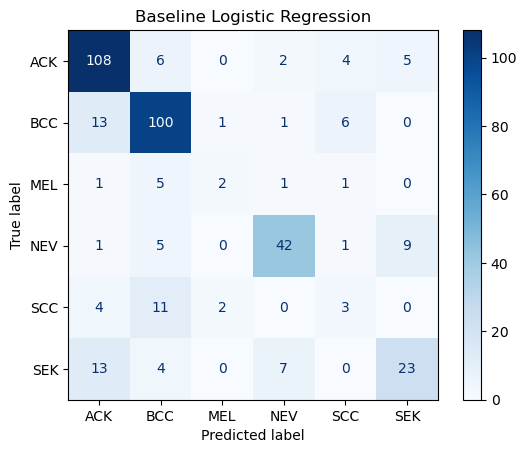


Class-Weighted Logistic Regression


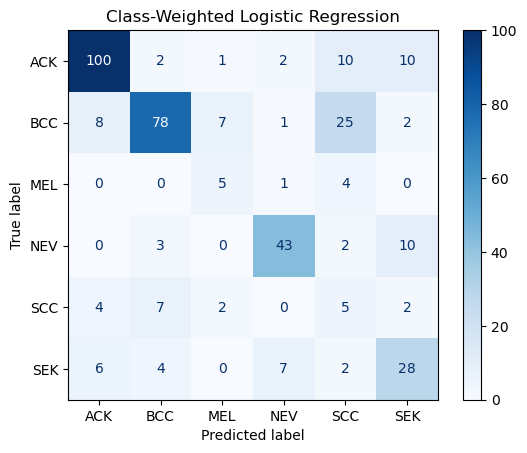


SMOTE Logistic Regression


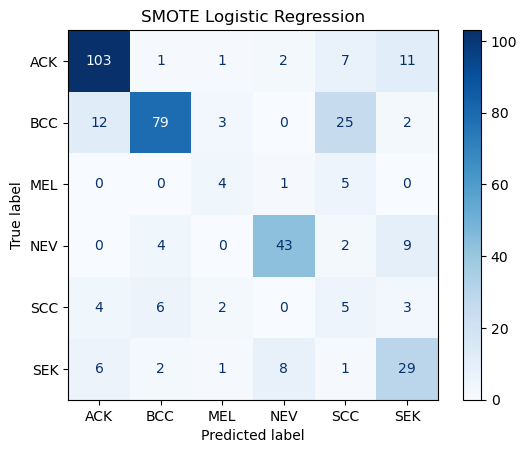


Baseline Decision Tree


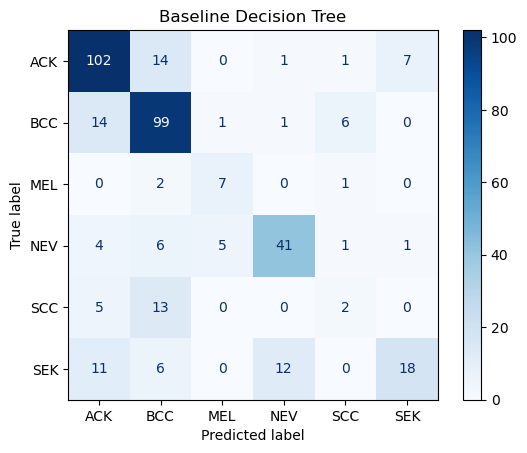


Sample-Weighted MLP


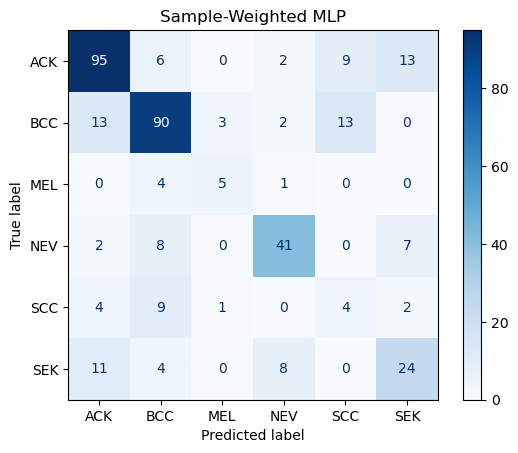


SMOTE Random Forest


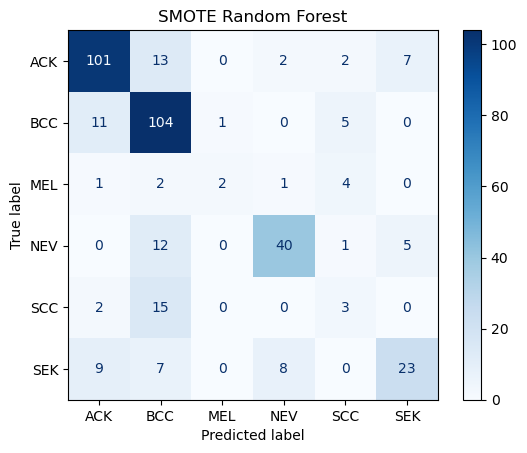

In [444]:

# 8.7 CONFUSION MATRIX ANALYSIS

# Import confusion_matrix to calculate classification errors
from sklearn.metrics import confusion_matrix

# Import ConfusionMatrixDisplay to visualise the matrices
from sklearn.metrics import ConfusionMatrixDisplay

# Generate confusion matrices for the selected models
for model_name, (model, X_test_input) in selected_models.items():

    # Generate predictions
    y_pred = model.predict(X_test_input)

    # Calculate confusion matrix using the fixed class order
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=classes
    )

    # Display the confusion matrix
    print(f"\n{model_name}")

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=classes
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(model_name)
    plt.show()

The confusion matrices provided further insight into the classification errors made by the selected models. Although the models achieved reasonable overall accuracy, their ability to distinguish between individual diagnostic categories varied considerably.

A recurring pattern was the misclassification of SCC observations as BCC. This was particularly evident in the SMOTE Random Forest, which incorrectly classified 15 out of 20 SCC observations as BCC. The baseline Decision Tree also demonstrated this issue, misclassifying 13 SCC observations as BCC.

For MEL, the baseline Decision Tree achieved the strongest detection performance, correctly classifying seven out of ten observations. In comparison, class-weighted Logistic Regression and sample-weighted MLP each correctly identified five MEL observations.

These findings highlight the challenges associated with distinguishing between underrepresented classes. They also demonstrate that improvements in the detection of one minority class do not necessarily result in improvements across other classes.

Overall, the confusion matrix analysis supports the findings from the classification reports: the baseline Decision Tree was particularly effective for MEL, whereas class-weighted and SMOTE Logistic Regression achieved stronger SCC detection.

In [445]:
# 8.8 OVERALL MODEL COMPARISON AND SELECTION

# Create a summary of the strongest model configurations
final_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression",
        "SMOTE Logistic Regression",
        "Baseline Decision Tree",
        "Sample-Weighted MLP",
        "SMOTE Random Forest",
        "Tuned Random Forest"
    ],

    "Accuracy": [
        0.7297, 0.6798, 0.6903, 0.7060,
        0.6798, 0.7165, 0.7244
    ],

    "Balanced Accuracy": [
        0.5423, 0.5886, 0.5809, 0.5873,
        0.5702, 0.5328, 0.4950
    ],

    "Macro F1": [
        0.5585, 0.5715, 0.5738, 0.5828,
        0.5754, 0.5574, 0.5126
    ],

    "ROC-AUC": [
        0.9076, 0.8993, 0.8973, 0.8677,
        0.8891, 0.9123, 0.9184
    ],

    "SCC Recall": [
        0.15, 0.25, 0.25, 0.10,
        0.20, 0.15, 0.05
    ],

    "MEL Recall": [
        0.20, 0.50, 0.40, 0.70,
        0.50, 0.20, 0.10
    ]
})

# Display models ordered by Macro F1
final_comparison.sort_values(
    by="Macro F1",
    ascending=False
)


,Model,Accuracy,Balanced Accuracy,Macro F1,ROC-AUC,SCC Recall,MEL Recall
3,Baseline Decision Tree,0.7060,0.5873,0.5828,0.8677,0.10,0.7
4,Sample-Weighted MLP,0.6798,0.5702,0.5754,0.8891,0.20,0.5
2,SMOTE Logistic Regression,0.6903,0.5809,0.5738,0.8973,0.25,0.4
1,Class-Weighted Logistic Regression,0.6798,0.5886,0.5715,0.8993,0.25,0.5
0,Baseline Logistic Regression,0.7297,0.5423,0.5585,0.9076,0.15,0.2
5,SMOTE Random Forest,0.7165,0.5328,0.5574,0.9123,0.15,0.2
6,Tuned Random Forest,0.7244,0.4950,0.5126,0.9184,0.05,0.1


# Stage 9 – Limitations and Critical Evaluation

**9.1 Class Imbalance**

The dataset contains an uneven distribution of diagnostic categories. ACK and BCC are the most frequent classes, whereas MEL and SCC have considerably fewer samples.

This imbalance may affect the models' ability to learn representative patterns for minority categories. Models may perform better on frequently occurring diagnoses while struggling to identify less common ones.

For example, the test set contained 125 ACK samples but only 10 MEL samples and 20 SCC samples. This imbalance was reflected in the classification results, particularly in the relatively low SCC recall achieved by several models.

To address this issue, class weighting, sample weighting and SMOTE-based oversampling were investigated. Although these techniques improved certain evaluation metrics and minority-class recall for some models, none consistently improved performance across all diagnostic categories.

For example, the baseline Decision Tree achieved a MEL recall of 0.70, whereas Class-Weighted Logistic Regression achieved an SCC recall of 0.25. However, improving the recognition of one minority category did not necessarily improve the recognition of another.

Despite these approaches, class imbalance remains a limitation of the dataset and may affect the reliability of predictions for minority categories.

**9.2 Missing Data**

The dataset contained substantial missing values across several demographic, lifestyle and medical-history features, with approximately 35% missingness in multiple columns.

Numerical missing values were handled using median imputation, while categorical missing values were assigned a separate "Missing" category. These imputation methods allowed the dataset to be retained without removing a large number of records.

However, imputation does not recover the original missing information and may affect the relationships between features and diagnostic categories.

Additionally, missing values were concentrated in particular groups of records. The models may therefore have learned patterns associated with missingness rather than solely learning underlying clinical characteristics.

This is an important limitation because such patterns may not be consistent in other datasets or real-world clinical settings.

**9.3 Dataset Size and Representativeness**

The dataset contained 2,298 original records, which were reduced to 1,891 unique patient-lesion combinations after duplicate combinations were identified.

Although the dataset provided sufficient records for comparing multiple machine learning algorithms, its size remains a limitation for a six-class classification problem.

Some diagnostic categories, particularly MEL and SCC, had relatively few observations. This limits the amount of representative information available for the models to learn patterns associated with these categories.

Furthermore, the dataset may not fully represent the wider population of patients with skin lesions. Differences in demographics, geographical regions and clinical settings could affect model performance when applied to other populations.

Therefore, the results should be interpreted within the context of the dataset used, and further evaluation using larger and more diverse datasets would be necessary to assess generalisability.

**9.4 Model Generalisation**

The ability of a machine learning model to generalise to unseen data is an important consideration when evaluating its performance.

In this project, a patient-level train/test split was implemented using StratifiedGroupKFold to reduce the possibility of data leakage between training and testing sets. This ensured that records belonging to the same patient were not shared across the two sets.

Patient-level grouping was particularly important because some patients had multiple lesion records. Without this approach, the model could potentially learn patient-specific patterns, resulting in overly optimistic evaluation results.

However, the evaluation was based on a single held-out test split from the same dataset. Therefore, the results do not establish how well the models would perform on completely independent datasets or different patient populations.

Further evaluation using repeated grouped cross-validation and external datasets would be necessary to assess the models' generalisation capabilities.

**9.5 Tabular Data Only**

This study focused exclusively on the tabular clinical metadata from the PAD-UFES-20 dataset. Although the original dataset also contains skin lesion images, these were excluded from the analysis.

The tabular features provided information about patient demographics, medical history, lesion dimensions and reported symptoms. However, they do not capture all the visual characteristics that may be relevant to skin lesion classification.

For example, image-based analysis could provide additional information about lesion colour, texture, shape, border irregularities and asymmetry.

Consequently, the models were limited to the information available in the tabular features. Combining clinical metadata with image-based features could potentially provide a more comprehensive representation of skin lesions and may improve classification performance.

However, the effectiveness of such a combined approach would need to be investigated through further experimentation.

**9.6 Neural Network Convergence**

The MLP neural network presented a convergence limitation during training.

The baseline MLP was trained with a maximum of 500 iterations. Following hyperparameter tuning, the selected configuration was trained with an increased maximum of 1,000 iterations. However, a convergence warning was still generated.

This indicates that the optimisation process had not satisfied the model's convergence criterion within the specified number of iterations.

Although the tuned MLP produced a final training loss of approximately 0.0894, this value alone does not establish that the model reached an optimal solution.

The convergence warning may have affected the reliability of the tuned model's performance and makes it difficult to determine whether additional training or different hyperparameters could have improved its results.

Therefore, the MLP results should be interpreted cautiously, and further experimentation with training iterations, network architecture and optimisation settings could be considered.

The MLP's lower performance does not necessarily prove that neural networks are unsuitable for this dataset. Its training may not have fully converged, and the hyperparameter search explored only a limited range of configurations.

**9.7 Overall Study Limitations**

Limitation

Potential impact on the study

Possible improvement

Class imbalance

Models may perform better on frequent diagnostic categories than minority categories such as MEL and SCC.

Collect more minority-class samples or investigate alternative class-weighting and resampling techniques.

Missing data

Imputation may introduce bias or allow models to learn patterns associated with missingness.

Investigate alternative imputation techniques and assess the influence of missing-value patterns.

Dataset size and representativeness

Limited samples may restrict learning, particularly for less frequent diagnostic categories. Results may not represent wider patient populations.

Use larger and more diverse datasets.

Model generalisation

Evaluation on a single held-out test set does not establish performance on independent datasets.

Conduct external validation using data from different populations or clinical settings.

Tabular data only

Visual characteristics of skin lesions were not included in the classification process.

Investigate combining clinical metadata with image-based features.

Neural network convergence

The tuned MLP did not satisfy its convergence criterion within 1,000 iterations, potentially affecting its performance.

Experiment with additional iterations, network architectures and optimisation settings.

SMOTE limitations

Interpolation on one-hot-encoded features may generate fractional categorical indicator values that do not represent realistic observations.

Investigate SMOTENC or alternative resampling approaches designed for mixed data.

Overall Evaluation

The study successfully compared traditional machine learning algorithms and a neural network for six-class skin lesion classification using tabular clinical metadata.

The experiments demonstrated that different models performed better under different evaluation criteria. The baseline Decision Tree achieved the highest Macro F1-score of 0.5828 and MEL recall of 0.70, while Class-Weighted Logistic Regression achieved the highest balanced accuracy of 0.5886. These findings highlight the difficulty of achieving consistent classification performance across all diagnostic categories.

However, the findings must be interpreted in the context of the dataset's class imbalance, missing information, limited size, neural network convergence and the absence of image-based features. The patient-level data splitting strategy helped reduce the risk of data leakage, although external validation would still be required to assess generalisation.

Future work could investigate larger and more diverse datasets, alternative approaches to handling missing data, improved class-imbalance techniques and combined image and tabular modelling.

The models developed in this study are experimental coursework models and have not been clinically validated. Their predictions should not be interpreted as medical diagnoses or used as a substitute for professional clinical assessment.